# Notebook 5 of 5 · Evidence-Grounded Agents, Answers to the Research Questions, Threat Report and Deployment

**Project:** Confidence-Aware and Adversarially Robust Cyber Threat Analysis Using Explainable Machine Learning and Evidence-Grounded AI Agents · MSc Data Science Final Project · Spoorthi Hosakote Suresh

This notebook is one of five that together make up the project. It contains the original code **and the outputs of the reported run**, plus guidance added for reading, running and presenting it.

| # | Notebook | Parts of the original notebook | Answers | Needs as input |
|---|---|---|---|---|
| 1 | `01_data_foundation` | Part 1 (+ project overview) | O1 (threat model) | CIC-IDS2017 Kaggle dataset |
| 2 | `02_detectors` | Part 2 | baselines for all RQs | output of 1 |
| 3 | `03_adversarial_attacks` | Part 3 | **RQ1** | outputs of 1, 2 |
| 4 | `04_confidence_mechanism` | Parts 4 and 4b | **RQ2** | outputs of 1, 2, 3 |
| 5 | `05_agents_results_deployment` | Parts 5, 6, 7, 7b, 8 | **RQ3, RQ4**, final answers | outputs of 1, 2, 3, 4 |

**How this notebook is organised:** sections 1–5 below explain the notebook (what it does, how to run it, key concepts, methodology, key results). The original project code and outputs follow. A **viva guide** is at the end.

### Setup · presentation helpers
Writes the small flowchart helper used by every flowchart in this notebook. **Run this cell first** if you re-run any flowchart cell on its own.

In [1]:
# Presentation helpers (flowcharts, colours) are written once to a small module, so every Part can use them
import os, sys
from pathlib import Path
PRES_DIR = Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"
PRES_DIR.mkdir(parents=True, exist_ok=True)
(PRES_DIR / "present_lib.py").write_text(r'''"""Presentation helpers for the combined notebook: flowcharts and a shared colour palette."""
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

FILL = {"data": "#DCE9F5", "model": "#E1F0DC", "attack": "#F8DEDB", "policy": "#FFEFD2",
        "agent": "#E9E1F4", "out": "#EFEFEF", "rq": "#FFFFFF", "accept": "#D7EFD7", "flag": "#FFE9B8", "escalate": "#F6C9C4"}
EDGE = {"data": "#3B6EA8", "model": "#4E9A47", "attack": "#C0453F", "policy": "#D9822B",
        "agent": "#7A5DB0", "out": "#7A7A7A", "rq": "#333333", "accept": "#3E8E41", "flag": "#C99100", "escalate": "#B3261E"}
SYSTEM_COLORS = {"A": "#9E9E9E", "B": "#4C72B0", "C": "#DD8452", "D": "#8172B3", "E": "#55A868"}
MODEL_COLORS = {"rf": "#4C72B0", "xgb": "#55A868", "mlp": "#C44E52"}


def _anchor(node, toward):
    x, y, w, h = node[:4]
    tx, ty = toward
    dx, dy = tx - x, ty - y
    if abs(dx) * h >= abs(dy) * w:           # leave through the left or right side
        return (x + (w / 2 + 0.6) * (1 if dx > 0 else -1), y)
    return (x, y + (h / 2 + 0.6) * (1 if dy > 0 else -1))


def flowchart(nodes, edges, size=(15, 6.5), title=None, fontsize=9.5, legend=None):
    """nodes: {key: (x, y, w, h, text, kind)} in a 0-100 x 0-50 canvas (centre coordinates).
    edges: [(from, to, label, rad)] - label and rad optional."""
    fig, ax = plt.subplots(figsize=size)
    ax.set_xlim(0, 100); ax.set_ylim(0, 50); ax.axis("off")
    for k, (x, y, w, h, text, kind) in nodes.items():
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.35,rounding_size=1.0",
                                    fc=FILL[kind], ec=EDGE[kind], lw=1.6, zorder=2))
        ax.text(x, y, text, ha="center", va="center", fontsize=fontsize, zorder=3, linespacing=1.25)
    for e in edges:
        a, b = e[0], e[1]
        label = e[2] if len(e) > 2 else ""
        rad = e[3] if len(e) > 3 else 0.0
        pa = _anchor(nodes[a], nodes[b][:2]); pb = _anchor(nodes[b], nodes[a][:2])
        ax.annotate("", xy=pb, xytext=pa, zorder=1,
                    arrowprops=dict(arrowstyle="-|>", color="#444444", lw=1.4, mutation_scale=14,
                                    connectionstyle=f"arc3,rad={rad}"))
        if label:
            mx, my = (pa[0] + pb[0]) / 2, (pa[1] + pb[1]) / 2
            ax.text(mx, my + 1.0 + 6 * abs(rad), label, ha="center", va="bottom", fontsize=fontsize - 1.5,
                    color="#333333", style="italic", zorder=4,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    if legend:
        handles = [plt.Rectangle((0, 0), 1, 1, fc=FILL[k], ec=EDGE[k]) for k in legend]
        ax.legend(handles, list(legend.values()), loc="lower center", ncol=len(legend), frameon=False,
                  fontsize=fontsize - 1, bbox_to_anchor=(0.5, -0.04))
    if title:
        ax.set_title(title, fontsize=fontsize + 3, fontweight="bold", loc="left")
    plt.tight_layout()
    return fig, ax
''')
sys.path.insert(0, str(PRES_DIR))
print("presentation helpers ready:", PRES_DIR / "present_lib.py")

presentation helpers ready: /kaggle/working/presentation/present_lib.py


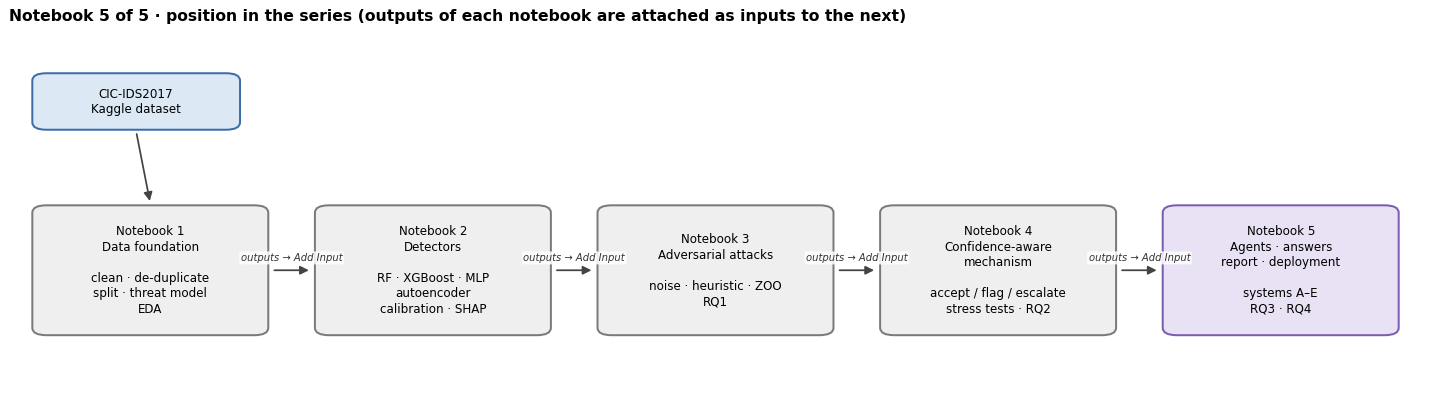

In [ ]:
import os, sys
from pathlib import Path
sys.path.insert(0, str(Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"))
import matplotlib.pyplot as plt
from present_lib import flowchart

# Where this notebook sits in the five-notebook series (highlighted box = this notebook)
nodes = {
    "data": (9, 40, 14, 7, "CIC-IDS2017\nKaggle dataset", "data"),
    "n1": (10, 17, 16, 17, 'Notebook 1\nData foundation\n\nclean · de-duplicate\nsplit · threat model\nEDA', "out"),
    "n2": (30, 17, 16, 17, 'Notebook 2\nDetectors\n\nRF · XGBoost · MLP\nautoencoder\ncalibration · SHAP', "out"),
    "n3": (50, 17, 16, 17, 'Notebook 3\nAdversarial attacks\n\nnoise · heuristic · ZOO\nRQ1', "out"),
    "n4": (70, 17, 16, 17, 'Notebook 4\nConfidence-aware\nmechanism\n\naccept / flag / escalate\nstress tests · RQ2', "out"),
    "n5": (90, 17, 16, 17, 'Notebook 5\nAgents · answers\nreport · deployment\n\nsystems A–E\nRQ3 · RQ4', "agent"),
}
edges = [("data", "n1")] + [(f"n{i}", f"n{i+1}", "outputs → Add Input") for i in range(1, 5)]
flowchart(nodes, edges, size=(16, 4.6), title="Notebook 5 of 5 · position in the series (outputs of each notebook are attached as inputs to the next)")
plt.show()

## 1 · What this notebook does

This notebook answers **RQ3** (*Does the mechanism improve reliability compared with individual models and a conventional multi-agent baseline?*) and **RQ4** (*What are the trade-offs between robustness, performance, latency and cost?*). It builds LLM agents with LangGraph and retrieval (RAG), compares five systems A–E on the same flows, then brings all results together (Part 6), generates an HTML threat report (Part 7), deploys the mechanism as a REST API (Part 7b) and concludes (Part 8).

| Item | Detail |
|---|---|
| Role in the project | **RQ3, RQ4**; final answers to all research questions |
| Input | Outputs of Notebooks 1–4 (optional: an earlier run's output containing `nb5_agents/llm_cache.jsonl`) |
| Output folders | `nb5_agents/`, `results_synthesis/`, `threat_report/` (printable summary report, one separate report per flow in `incidents/`, searchable `incident_explorer.html`), `nb7b_deployment/` (FastAPI service, tests, Dockerfile) |
| Run time | about **9.3 hours** for Part 5 without an LLM cache (close to Kaggle's 12-hour limit); far shorter with the cache attached. Parts 6 and 7 take about a minute; Part 7b about 5 minutes |
| Hardware | **GPU T4 ×2** · **Internet on** (Gemma 4 is downloaded once) |
| Report sections | 4.9, 5.5–5.7, 6, 7 · Tables 6, 10, 11 · Figures 11, 12, 13 |

## 2 · How to run

**General Kaggle steps (same for every notebook)**
1. On Kaggle, click **Create → New Notebook**, then **File → Import Notebook** and upload this `.ipynb` file.
2. In the right-hand panel, open **Session options** and set the **Accelerator** and **Internet** as listed below.
3. Click **+ Add Input** and attach the inputs listed below. Outputs of your earlier notebooks are found under **Your Work → Notebooks**: choose the notebook and attach its latest **output** version.
4. Click **Save Version → Save & Run All (Commit)**. Running as a saved version keeps the files in `/kaggle/working/` as this notebook's **output**, which the next notebook attaches.
5. When the run finishes, open the version and check the **Final checks** section (every row should show ✔).

**Why this works.** Every Part starts from a clean memory state and finds what it needs by file name, first in `/kaggle/working/` and then anywhere under `/kaggle/input/`. Attached outputs are therefore found automatically; no paths need to be edited.

**For the viva you do not need to re-run anything.** This file already contains every output of the reported run, so all tables and figures can be shown immediately.

**Settings for this notebook**

| Setting | Value |
|---|---|
| Accelerator | GPU T4 ×2 |
| Internet | **On** |
| Inputs to attach | Outputs of **Notebooks 1, 2, 3 and 4** |
| Hugging Face access | Accept the Gemma licence on huggingface.co, create an access token, and add it in Kaggle under **Add-ons → Secrets** with the name `HF_TOKEN` |
| Optional (much faster) | Attach the output of an earlier run that contains `nb5_agents/llm_cache.jsonl`; cached LLM answers are reused |

**Settings you can change** (Section 5.2, `CONFIG`)

| Key | Reported value | Meaning |
|---|---|---|
| `backend` | hf | `hf` = local Gemma via Transformers; `mock` = code test only (never report) |
| `hf_model` | google/gemma-4-E2B-it | the LLM used by the agents |
| `smoke_test` | False | True runs 10 + 10 flows to test the setup in minutes |
| `n_flagged`, `n_accepted` | 100, 100 | evaluation sample (weighted to the test mix) |
| `kb_top_k` | 3 | knowledge-base entries retrieved per flow |
| `max_revisions` | 1 | verifier → decision-agent revision loops |
| `temperature` | 0.0 | deterministic generation |

**Tip:** run once with `smoke_test = True` to check the setup before the long run.

## 3 · Key concepts and techniques

| Concept | In plain words | Why it is used here | Section |
|---|---|---|---|
| LLM agent | A language model given a role, inputs and an output format | Turns detector evidence into readable reports | 5.9 |
| Gemma 4 E2B | Small open LLM run locally on the GPU | No traffic data leaves the environment | 5.7 |
| LangGraph | Library that wires agents into a graph with loops | Evidence analyst → threat-intelligence agent → decision/report agent → verifier | 5.9 |
| RAG (retrieval-augmented generation) | Retrieve relevant knowledge and give it to the LLM | Knowledge base of attack families with MITRE ATT&CK techniques; TF-IDF top 3 | 5.5 |
| Evidence items | Numbered facts from the models (never the true label) | Every claim must cite them | 5.6 |
| Deterministic verifier | Code that rejects claims citing nothing, unknown items, absent classes or numbers not in the evidence | Checks grounding without trusting another LLM | 5.8 |
| Systems A–E | A model only; B rules pipeline; C single agent; D multi-agent on every flow; E mechanism routes flows to the same agents | D vs E isolates the effect of routing | 5.10 |
| Weighted sample | 200 flows re-weighted to the test-set proportions | Affordable but representative | 5.4 |
| Paired bootstrap | Resampling the same flows for both systems | Which differences are real | 5.12 |
| Tokens, latency, energy | Cost of each system | RQ4 | 5.13, 6.9 |
| LLM-only baseline | The LLM classifies flows directly | Can the LLM replace the detector? (no: 0.047) | 5.19 |
| Incident explorer and live report generator | Type an incident number, sample ID or keyword: only that incident's report is shown, generated from the data | A clean, separate report per flow for analysts and the viva demo | 7.2–7.3 |
| FastAPI, Docker, parity test | REST service, container, same decisions as Notebook 4 | Shows the mechanism is deployable | 7b |

## 4 · Methodology at a glance

| Step | What happens | Why | Section |
|---|---|---|---|
| Load | Decisions and evidence from Notebook 4 | Same flows for every system | 5.3 |
| Sample | 100 flagged/escalated + 100 accepted test flows, weighted | Affordable LLM evaluation | 5.4 |
| Knowledge base | Attack families, MITRE ATT&CK techniques, feature dictionary; TF-IDF retrieval | Grounding for the agents | 5.5 |
| Agents + verifier | LangGraph graph, numbered evidence, deterministic verifier, one revision | Grounded reports | 5.6–5.9 |
| Systems A–E | Run all five on the same sample | RQ3 comparison | 5.10 |
| Reliability | Errors handled, automatic macro-F1, unsupported claims | RQ3 | 5.11 |
| Bootstrap | Paired differences (E − D, E − B, …) | Established or not | 5.12 |
| Trade-offs | Tokens, latency, cost | RQ4 | 5.13 |
| Extra checks | Larger LLM, agent ablation, verifier stress test, LLM-only baseline | Robustness of the conclusions | 5.16–5.19 |
| Answers | RQ1–RQ4, main RQ, best model, energy | Synthesis | Part 6 |
| Report | Executive summary; one separate report per flow (saved as its own file); searchable explorer; live report generator | Demonstration | Part 7 |
| Deployment | FastAPI service, parity, tests, latency, Docker | Implementability | Part 7b |
| Conclusion | Contributions, limitations, future work | Wrap-up | Part 8 |

## 5 · Key results to remember

| System | Errors handled | Auto macro-F1 | Auto coverage | Tokens / flow | Seconds / flow |
|---|---|---|---|---|---|
| A single model | 0.0 % | 0.633 | 100 % | 0 | < 0.01 |
| B rules pipeline | 92.4 % | 0.958 | 61.4 % | 0 | < 0.01 |
| C single agent | 96.2 % | 0.965 | 62.0 % | 1,068 | 22.1 |
| D multi-agent | 96.2 % | 0.965 | 59.5 % | 3,073 | 63.6 |
| **E proposed** | **93.7 %** | 0.954 | 61.9 % | **1,506** | **29.4** |

- **E vs D:** errors handled −2.4 points [−5.9, 0.0], *not established*; tokens −1,567 [−1,801, −1,328] and time −34.2 s [−39.6, −28.9] per flow, *both established*. The reliability gain comes from the mechanism, not the LLM.
- **Grounding:** unsupported claims ≤ 0.13 %; invalid output ≤ 0.5 %; the verifier caught 100 % of injected citation, number and label errors (0 % false alarms) but cannot check meaning.
- **LLM-only classifier:** macro-F1 0.047 vs 0.633 for XGBoost on the same flows → the LLM should explain, not classify.
- **Larger LLM (E4B):** 95.1 % errors handled, no established gain; 23 s slower per flow.
- **Energy:** about 1.24 kWh (D) vs 0.57 kWh (E) per 1,000 flows (upper bound).
- **Deployment:** 100 % parity with Notebook 4 on 347 flows; 9 of 9 API tests passed; 62 ms per flow end to end; 226 flows/s in batches of 1,000.

---
# Original project code and outputs
Everything below is the project code exactly as in the reported run, with its outputs. Grey **Findings** boxes are generated by the code above them.

<a id="part5"></a>
# Part 5 · Evidence-Grounded Agents, System Comparison and Trade-offs (RQ3, RQ4)

| | |
|---|---|
| **Goal** | Run LLM agents (Gemma 4, LangGraph, RAG) on the mechanism's evidence and compare five systems on reliability, grounding and cost. |
| **Answers** | **RQ3 / O3** and **RQ4 / O4** |
| **Inputs** | Part 4 outputs (+ Parts 2–3 cost tables) |
| **Outputs used later** | system results, agent reports, bootstrap comparisons, trade-off table |
| **Run time** | ≈ 5 h on a T4 (minutes if the LLM cache of an earlier run is attached) + ≈ 3 h per extra LLM in Section 5.16 + ≈ 20–40 min for the LLM-only baseline (5.19, self-limiting) |

#### Research questions answered here
> **RQ3:** Does the confidence-aware mechanism, combined with evidence-grounded agents, make better decisions than individual detectors, a non-agentic pipeline, a single agent and a conventional multi-agent system?
>
> **RQ4:** What are the trade-offs between reliability, latency and computational cost of these systems?

#### Five systems on the same flows
| System | What it does | Role |
|---|---|---|
| **A · Single model** | the policy detector's prediction, always accepted | baseline |
| **B · Non-agentic pipeline** | Part 4's mechanism; *flagged* flows get a deterministic evidence check (majority of classifiers + anomaly consistency), *escalated* flows go to a human | baseline |
| **C · Single agent** | one LLM agent analyses **every** flow (no mechanism) | baseline |
| **D · Multi-agent** | evidence analyst → threat-intelligence agent (RAG) → decision/report agent → verifier, on **every** flow | conventional multi-agent comparator |
| **E · Proposed** | Part 4's mechanism routes flows: accepted flows are decided at once; only flagged and escalated flows go to the same agents as D | contribution |
| *G · Guarded agents* | E's agent answers, but a flow is decided automatically only if the agents agree with B's deterministic check; otherwise it is escalated (Section 5.12b, post-hoc) | design variant |

D and E use **identical agents**, so the D–E difference isolates what the confidence-aware routing adds in reliability, cost and latency. The C–D difference tests whether several agents justify their extra cost over one, and B–E tests whether an LLM is needed at all.

#### Evidence and retrieval
Every agent receives only facts produced by the models (never the true label) and may cite only:
* **E-items**: the classifiers' verdicts and calibrated confidence, the anomaly p-value, explanation robustness, the three most influential features (described with Part 1's feature dictionary), the five most similar training flows, and the mechanism's decision;
* **K-items** (retrieval-augmented generation): curated reference entries on the CIC-IDS2017 attack families with their MITRE ATT&CK techniques, and feature-group entries generated from Part 1's feature dictionary.

A programmatic **verifier** rejects claims that cite nothing, cite unknown items, name a class absent from the evidence, or quote numbers that are not in the evidence; the decision agent gets one chance to revise.

#### LLM
Section 5.16 repeats the proposed system with the larger Gemma 4 E4B (a cybersecurity-specialised LLM, Cisco Foundation-Sec 1.1 8B, is configured but was not run in the reported run), to test whether model size or domain training changes the result.

The agents run on **Gemma 4** (`google/gemma-4-E2B-it`, instruction-tuned) locally on Kaggle's GPU through Hugging Face Transformers, so no flow data leaves the environment. An Anthropic API backend is available as an alternative, and a `mock` backend exists only to test the code path.

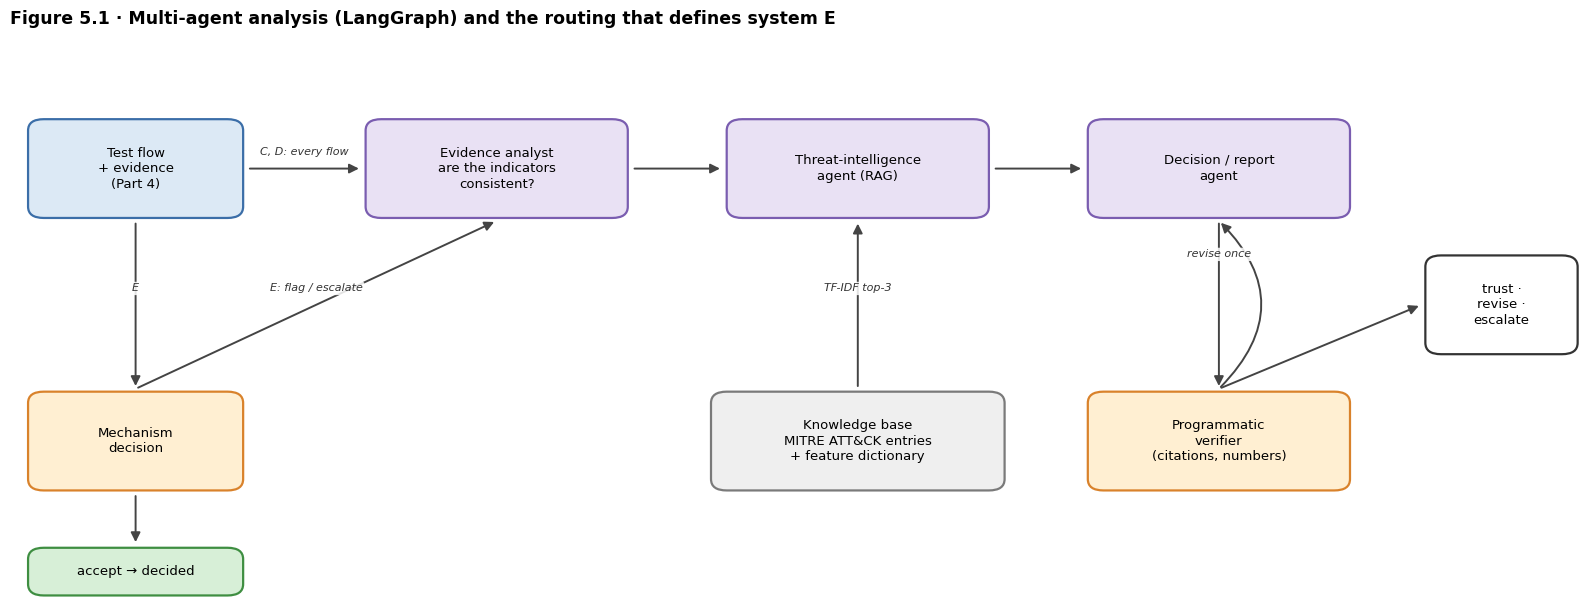

In [98]:
import os, sys
from pathlib import Path
sys.path.insert(0, str(Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"))
import matplotlib.pyplot as plt
from present_lib import flowchart

nodes = {
    "flow": (8, 38, 13, 8, "Test flow\n+ evidence\n(Part 4)", "data"),
    "mech": (8, 14, 13, 8, "Mechanism\ndecision", "policy"),
    "fast": (8, 2.5, 13, 3.5, "accept → decided", "accept"),
    "ea": (31, 38, 16, 8, "Evidence analyst\nare the indicators\nconsistent?", "agent"),
    "ti": (54, 38, 16, 8, "Threat-intelligence\nagent (RAG)", "agent"),
    "kb": (54, 14, 18, 8, "Knowledge base\nMITRE ATT&CK entries\n+ feature dictionary", "out"),
    "dr": (77, 38, 16, 8, "Decision / report\nagent", "agent"),
    "ver": (77, 14, 16, 8, "Programmatic\nverifier\n(citations, numbers)", "policy"),
    "fin": (95, 26, 9, 8, "trust ·\nrevise ·\nescalate", "rq"),
}
edges = [("flow", "ea", "C, D: every flow"), ("flow", "mech", "E"), ("mech", "ea", "E: flag / escalate", 0.0), ("mech", "fast"), ("ea", "ti"),
         ("kb", "ti", "TF-IDF top-3"), ("ti", "dr"), ("dr", "ver"), ("ver", "dr", "revise once", 0.5), ("ver", "fin")]
flowchart(nodes, edges, size=(16, 6.2), title="Figure 5.1 · Multi-agent analysis (LangGraph) and the routing that defines system E")
plt.show()

## 5.1 · Setup

In [99]:
# Fresh start: this Part reloads everything it needs from the files saved by earlier Parts,
# so memory from the previous Part (e.g. the 2.8 M-row table of Part 1) is released first.
%reset -f
import gc; gc.collect()

0

In [100]:
# Gemma 4 needs a recent Transformers release; LangGraph orchestrates the agents (Kaggle: Internet on)
import os, subprocess, sys
if os.environ.get("IDS_SKIP_INSTALL") != "1":
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "transformers", "accelerate", "langgraph"], check=False)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [101]:
import os, re, json, time, hashlib, warnings, platform, sys
from datetime import datetime, timezone
from pathlib import Path
from typing import TypedDict
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

SEED = 42
INPUT_ROOT = Path(os.environ.get("IDS_INPUT_ROOT", "/kaggle/input"))
WORK_ROOT  = Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working"))
OUT = WORK_ROOT / "nb5_agents"; (OUT / "figures").mkdir(parents=True, exist_ok=True)

try:
    from langgraph.graph import StateGraph, END
    HAVE_LANGGRAPH = True
except ImportError:
    HAVE_LANGGRAPH = False
import importlib.metadata as _md
def _ver(p):
    try: return _md.version(p)
    except Exception: return None
VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "sklearn": sklearn.__version__, "langgraph": _ver("langgraph"), "transformers": _ver("transformers"),
            "torch": _ver("torch")}
display(pd.DataFrame(VERSIONS.items(), columns=["package", "version"]))
if not HAVE_LANGGRAPH:
    print("LangGraph is not installed: run `!pip install -q langgraph` (Internet on). Without it the same agent "
          "nodes run in a plain sequential loop, and the run record says so.")

def findings(rows, meaning=""):
    text = "> #### Findings\n> | Check | Result |\n> |---|---|\n" + "".join(f"> | {a} | {b} |\n" for a, b in rows)
    if meaning: text += f">\n> **Meaning:** {meaning}\n"
    display(Markdown(text))

,package,version
0,python,3.13.15
1,numpy,2.1.3
2,pandas,2.3.3
3,sklearn,1.6.1
4,langgraph,1.2.17
5,transformers,5.20.2
6,torch,2.11.0+cu128


## 5.2 · Configuration
| Backend | Needs | Use |
|---|---|---|
| `"hf"` (default) | GPU, Internet on for the first download, `HF_TOKEN` secret, accepted Gemma licence | the reported run: Gemma 4 running locally |
| `"anthropic"` | `ANTHROPIC_API_KEY` secret, Internet on | alternative backend; paid per token |
| `"mock"` | nothing | **code test only**; its numbers must never be reported |

Prices stay `None` unless copied from the provider's official pricing page (cited in the report); tokens and latency are always measured. For a local model the relevant cost is GPU time, which is measured as latency.

In [102]:
CONFIG = {
    "backend": "hf",                          # "hf" | "anthropic" | "mock"
    "hf_model": "google/gemma-4-E2B-it",      # Hugging Face ID, or "kaggle:<owner>/<model>/transformers/<variation>" for Kaggle Models
    "hf_dtype": "float16",                    # T4 has no bfloat16; use "float32" (with T4 x2) if outputs look garbled
    "anthropic_model": "claude-haiku-5-5",
    "max_output_tokens": 600,
    "temperature": 0.0,
    "price_per_mtok_input": None,             # USD per million input tokens (API backends only)
    "price_per_mtok_output": None,
    "smoke_test": False,                       # True: 10 + 10 flows to test the setup; False: the reported run
    "n_flagged": 100,                         # flagged or escalated test flows in the evaluation sample
    "n_accepted": 100,                        # accepted test flows in the evaluation sample
    "kb_top_k": 3,
    "max_revisions": 1,                       # verifier -> decision agent loops in D and E
    "n_boot": 1000,
    "seed": SEED,
}
if CONFIG["smoke_test"]:
    CONFIG["n_flagged"] = CONFIG["n_accepted"] = 10
print(json.dumps(CONFIG, indent=2))
if CONFIG["backend"] == "mock":
    print("\n*** MOCK BACKEND: results below test the code only and must NOT be reported. ***")
if CONFIG["smoke_test"]:
    print("\n*** SMOKE TEST: 20 flows only. Set smoke_test = False for the reported run. ***")

{
  "backend": "hf",
  "hf_model": "google/gemma-4-E2B-it",
  "hf_dtype": "float16",
  "anthropic_model": "claude-haiku-5-5",
  "max_output_tokens": 600,
  "temperature": 0.0,
  "price_per_mtok_input": null,
  "price_per_mtok_output": null,
  "smoke_test": false,
  "n_flagged": 100,
  "n_accepted": 100,
  "kb_top_k": 3,
  "max_revisions": 1,
  "n_boot": 1000,
  "seed": 42
}


## 5.3 · Load Part 4's decisions and evidence

In [103]:
def find_one(name, required=True):
    hits = sorted(WORK_ROOT.glob(f"*/{name}")) + sorted(INPUT_ROOT.rglob(name))  # this run first, then attached outputs
    hits = list(dict.fromkeys(hits))
    if not hits:
        if required: raise FileNotFoundError(f"{name} not found: attach Part 4's saved output")
        print(f"[optional, missing] {name}"); return None
    if len(hits) > 1: print(f"note: several copies of {name}; using {hits[0]}")
    print(f"[found] {name}: {hits[0]}"); return hits[0]

FLAGS_ALL = pd.read_parquet(find_one("policy_flags_test.parquet"))
SPEC = json.loads(find_one("policy_spec.json").read_text())
FDICT = pd.read_csv(find_one("agent_feature_dictionary.csv"))
COST_PATHS = {"cost_profile.csv": find_one("cost_profile.csv", False), "attack_cost.csv": find_one("attack_cost.csv", False),
              "cost_policy.csv": find_one("cost_policy.csv", False)}
NB4_RUN = find_one("run_record_nb4.json", False)
CLASS_NAMES, BENIGN_ID = SPEC["class_names"], int(SPEC["benign_id"])
POLICY, OTHERS = SPEC["policy_detector"], SPEC["other_models"]
assert SPEC["stability_mode"] == "deployable", "Part 4 output is from an old version: rerun Part 4"
STAB_NAME = {"local_stab": "local explanation robustness", "proto_sim": "similarity to the class prototype explanation"}[SPEC["stability_variant"]]
FLAGS = FLAGS_ALL[FLAGS_ALL["set"] == "test"].reset_index(drop=True)
need = {"y", "pred", "conf", "anomaly_p", "stability", "decision", "flagged", "variant", "group", "is_error", "is_evasion",
        "top_feature_1", "knn_families"} | {f"pred_{m}" for m in OTHERS}
assert need <= set(FLAGS.columns), f"missing columns: {need - set(FLAGS.columns)}"
DESC = {r.feature: (str(r.description), str(r.unit)) for r in FDICT.itertuples()}
findings([("Test flow versions", f"{len(FLAGS):,}"),
          ("Accepted / flagged / escalated", " / ".join(f"{(FLAGS.decision == d).mean():.1%}" for d in ["accept", "flag", "escalate"])),
          ("Policy detector / other classifiers", f"{POLICY} / {', '.join(OTHERS)}"),
          ("Explanation-robustness indicator", STAB_NAME)])

[found] policy_flags_test.parquet: /kaggle/working/nb4_decision_policy/policy_flags_test.parquet
[found] policy_spec.json: /kaggle/working/nb4_decision_policy/policy_spec.json
[found] agent_feature_dictionary.csv: /kaggle/working/nb4_decision_policy/agent_feature_dictionary.csv
[found] cost_profile.csv: /kaggle/working/nb2_detectors/cost_profile.csv
[found] attack_cost.csv: /kaggle/working/nb3_attacks/attack_cost.csv
[found] cost_policy.csv: /kaggle/working/nb4_decision_policy/cost_policy.csv
[found] run_record_nb4.json: /kaggle/working/nb4_decision_policy/run_record_nb4.json


> #### Findings
> | Check | Result |
> |---|---|
> | Test flow versions | 54,158 |
> | Accepted / flagged / escalated | 47.8% / 16.0% / 36.2% |
> | Policy detector / other classifiers | xgb / rf, mlp |
> | Explanation-robustness indicator | similarity to the class prototype explanation |


## 5.4 · Fixed evaluation sample
LLM calls are slow, so all systems run on the **same** stratified sample of `n_flagged` non-accepted and `n_accepted` accepted test flow versions, drawn with a fixed seed. Non-accepted flows are over-represented relative to the test set, so every metric is **re-weighted to the test-set proportions** and estimates performance on the whole test set. The sample is saved, so every backend sees identical flows.

In [104]:
rng = np.random.default_rng(SEED); parts = []
for is_flag, n in [(True, CONFIG["n_flagged"]), (False, CONFIG["n_accepted"])]:
    pool = FLAGS.index[FLAGS["flagged"] == is_flag].to_numpy()
    parts.append(rng.choice(pool, size=min(n, len(pool)), replace=False))
SAMPLE = FLAGS.loc[np.sort(np.concatenate(parts))].reset_index(drop=True)
pop_share, samp_share = FLAGS["flagged"].mean(), SAMPLE["flagged"].mean()
SAMPLE["weight"] = np.where(SAMPLE["flagged"], pop_share / samp_share, (1 - pop_share) / (1 - samp_share))
SAMPLE["sample_id"] = np.arange(len(SAMPLE))
SAMPLE.to_parquet(OUT / "evaluation_sample.parquet", index=False)
display(SAMPLE.groupby(["decision", "variant"]).size().rename("flows").to_frame())
findings([("Sampled flows", f"{len(SAMPLE)}"), ("Policy-detector errors / evasions in the sample",
                                               f"{int(SAMPLE.is_error.sum())} / {int(SAMPLE.is_evasion.sum())}")])

flows
decision variant        
accept   attacked     96
         clean         4
escalate attacked     70
flag     attacked     30

> #### Findings
> | Check | Result |
> |---|---|
> | Sampled flows | 200 |
> | Policy-detector errors / evasions in the sample | 76 / 74 |


## 5.5 · Knowledge base and retrieval (RAG)
Two kinds of K-items:
* **curated reference entries** on the CIC-IDS2017 attack families, written in my own words from the cited sources, with the MITRE ATT&CK technique each family corresponds to;
* **feature-group entries** generated from Part 1's feature dictionary, so agents can explain what an influential feature measures.

Retrieval uses TF-IDF cosine similarity: deterministic, no downloads, and fully inspectable. The query combines the candidate class names with the evidence text.

In [105]:
KB = [
    {"id": "K-DOS", "title": "Denial of service (DoS) in CIC-IDS2017",
     "text": "DoS traffic in CIC-IDS2017 was generated with tools such as Hulk, GoldenEye, Slowloris and Slowhttptest against a "
             "web server. Volume-based variants send many requests quickly, while slow variants hold connections open with "
             "partial requests to exhaust server resources. MITRE ATT&CK maps such behaviour to Network Denial of Service "
             "(T1498) and Endpoint Denial of Service (T1499).",
     "source": "Sharafaldin, Lashkari and Ghorbani (2018); MITRE ATT&CK T1498, T1499", "url": "https://attack.mitre.org/techniques/T1499/"},
    {"id": "K-DDOS", "title": "Distributed denial of service (DDoS)",
     "text": "The DDoS traffic in CIC-IDS2017 was produced with LOIC from several attacking machines, flooding the victim with "
             "requests. Distributed floods correspond to MITRE ATT&CK Network Denial of Service (T1498).",
     "source": "Sharafaldin, Lashkari and Ghorbani (2018); MITRE ATT&CK T1498", "url": "https://attack.mitre.org/techniques/T1498/"},
    {"id": "K-PORTSCAN", "title": "Port scanning",
     "text": "Port scans probe many ports or hosts with short connection attempts to discover services. Flows are typically "
             "very short with few packets. MITRE ATT&CK calls this Network Service Discovery (T1046).",
     "source": "Sharafaldin, Lashkari and Ghorbani (2018); MITRE ATT&CK T1046", "url": "https://attack.mitre.org/techniques/T1046/"},
    {"id": "K-BRUTE", "title": "Credential brute force (FTP-Patator, SSH-Patator)",
     "text": "Brute-force traffic repeatedly attempts logins against FTP and SSH services with the Patator tool. MITRE ATT&CK "
             "lists this as Brute Force (T1110), sub-technique Password Guessing (T1110.001).",
     "source": "Sharafaldin, Lashkari and Ghorbani (2018); MITRE ATT&CK T1110", "url": "https://attack.mitre.org/techniques/T1110/"},
    {"id": "K-WEB", "title": "Web application attacks (brute force, XSS, SQL injection)",
     "text": "The web attacks target a vulnerable web application with login brute forcing, cross-site scripting and SQL "
             "injection. These classes are rare in the dataset. MITRE ATT&CK maps exploitation of web applications to "
             "Exploit Public-Facing Application (T1190).",
     "source": "Sharafaldin, Lashkari and Ghorbani (2018); MITRE ATT&CK T1190", "url": "https://attack.mitre.org/techniques/T1190/"},
    {"id": "K-BOT", "title": "Botnet (Ares)",
     "text": "Bot traffic comes from hosts infected with the Ares botnet communicating with a command-and-control server. "
             "MITRE ATT&CK describes command-and-control over standard protocols as Application Layer Protocol (T1071).",
     "source": "Sharafaldin, Lashkari and Ghorbani (2018); MITRE ATT&CK T1071", "url": "https://attack.mitre.org/techniques/T1071/"},
    {"id": "K-INFIL", "title": "Infiltration and Heartbleed",
     "text": "Infiltration traffic follows a victim opening a malicious file, after which the attacker scans the internal "
             "network from the compromised host. Heartbleed exploits the OpenSSL vulnerability CVE-2014-0160. Both classes "
             "have very few flows in CIC-IDS2017 and were not used for training in this project.",
     "source": "Sharafaldin, Lashkari and Ghorbani (2018)", "url": "https://doi.org/10.5220/0006639801080116"},
    {"id": "K-BENIGN", "title": "Benign traffic in CIC-IDS2017",
     "text": "Benign traffic was produced by profiles of simulated user behaviour (web browsing, email, file transfer and "
             "similar protocols) in a lab testbed. It is not real production traffic.",
     "source": "Sharafaldin, Lashkari and Ghorbani (2018)", "url": "https://doi.org/10.5220/0006639801080116"},
    {"id": "K-EVASION", "title": "Adversarial evasion of flow-based detectors",
     "text": "Attackers who control their own traffic can change packet counts, sizes and timing so that a malicious flow is "
             "classified as benign while the attack still works. Realistic threat models restrict changes to "
             "attacker-controllable features.",
     "source": "Apruzzese et al. (2022)", "url": "https://doi.org/10.1145/3469659"},
    {"id": "K-DATASET", "title": "Known CIC-IDS2017 data issues",
     "text": "Engelen, Rimmer and Joosen (2021) documented labelling and feature-extraction errors in CIC-IDS2017, so some "
             "ground-truth labels may themselves be wrong.",
     "source": "Engelen, Rimmer and Joosen (2021)", "url": "https://doi.org/10.1109/SPW53761.2021.00009"},
    {"id": "K-XAI", "title": "Instability of post-hoc explanations",
     "text": "SHAP and LIME explanations can change under small input perturbations and can be manipulated, so an unstable "
             "explanation is a reason for caution rather than proof of an attack.",
     "source": "Alvarez-Melis and Jaakkola (2018); Slack et al. (2020)", "url": "https://doi.org/10.1145/3375627.3375830"},
]
for grp, d in FDICT[FDICT.get("in_model", True).astype(bool)].groupby("group"):
    feats = "; ".join(f"{r.feature} ({r.description}, {r.unit})" for r in d.head(8).itertuples())
    KB.append({"id": f"K-FEAT-{str(grp).upper().replace('_', '-')}", "title": f"Flow features: {grp}",
               "text": f"Features in the group '{grp}': {feats}.", "source": "Part 1 feature dictionary (CICFlowMeter features)",
               "url": ""})
(OUT / "knowledge_base.json").write_text(json.dumps(KB, indent=2))
KB_TEXT = [f"{k['title']}. {k['text']}" for k in KB]
TFIDF = TfidfVectorizer(stop_words="english", ngram_range=(1, 2)).fit(KB_TEXT)
KB_MATRIX = TFIDF.transform(KB_TEXT)

def retrieve(query, k=CONFIG["kb_top_k"]):
    sims = (KB_MATRIX @ TFIDF.transform([query]).T).toarray().ravel()
    return [KB[i] for i in np.argsort(-sims, kind="stable")[:k]]

display(pd.DataFrame([(k["id"], k["title"], k["source"]) for k in KB], columns=["id", "title", "source"]))

,id,title,source
0,K-DOS,Denial of service (DoS) in CIC-IDS2017,"Sharafaldin, Lashkari and Ghorbani (2018); MIT..."
1,K-DDOS,Distributed denial of service (DDoS),"Sharafaldin, Lashkari and Ghorbani (2018); MIT..."
2,K-PORTSCAN,Port scanning,"Sharafaldin, Lashkari and Ghorbani (2018); MIT..."
3,K-BRUTE,"Credential brute force (FTP-Patator, SSH-Patator)","Sharafaldin, Lashkari and Ghorbani (2018); MIT..."
4,K-WEB,"Web application attacks (brute force, XSS, SQL...","Sharafaldin, Lashkari and Ghorbani (2018); MIT..."
5,K-BOT,Botnet (Ares),"Sharafaldin, Lashkari and Ghorbani (2018); MIT..."
6,K-INFIL,Infiltration and Heartbleed,"Sharafaldin, Lashkari and Ghorbani (2018)"
7,K-BENIGN,Benign traffic in CIC-IDS2017,"Sharafaldin, Lashkari and Ghorbani (2018)"
8,K-EVASION,Adversarial evasion of flow-based detectors,Apruzzese et al. (2022)
9,K-DATASET,Known CIC-IDS2017 data issues,"Engelen, Rimmer and Joosen (2021)"


## 5.6 · Evidence for each flow
Each flow's evidence is a numbered list of facts taken directly from Part 4's output. Nothing in it is generated, and the true label and attack status are **never** included.

In [106]:
NAME2ID = {n: i for i, n in enumerate(CLASS_NAMES)}
def name(c): return CLASS_NAMES[int(c)]
REASON_TEXT = {"reason_low_confidence": "low confidence", "reason_possible_evasion": "benign verdict contradicted by the anomaly detector",
               "reason_unsupported_alarm": "attack verdict not supported by the anomaly detector",
               "reason_unstable_explanation": "unstable explanation"}

def build_evidence(row):
    ev = [("E1", f"Policy detector ({POLICY}) predicts {name(row.pred)} with calibrated confidence {row.conf:.3f}.")]
    for m in OTHERS:
        ev.append((f"E{len(ev) + 1}", f"Classifier {m} predicts {name(row[f'pred_{m}'])} with confidence {row[f'conf_{m}']:.3f}."))
    ev.append((f"E{len(ev) + 1}", f"Anomaly detector p-value is {row.anomaly_p:.4f} (small values mean the flow is unusual "
                                  f"compared with benign traffic)."))
    ev.append((f"E{len(ev) + 1}", f"Explanation robustness ({STAB_NAME}) is {row.stability:.3f} (1 = fully robust)."))
    feats = []
    for k in (1, 2, 3):
        f = row[f"top_feature_{k}"]; desc, unit = DESC.get(f.replace("__missing", ""), ("", ""))
        feats.append(f"{f}" + (f" [{desc}, {unit}]" if desc else "") + (" supporting" if row[f"top_feature_{k}_supports"] else " opposing")
                     + " the prediction")
    ev.append((f"E{len(ev) + 1}", "Most influential features: " + "; ".join(feats) + "."))
    ev.append((f"E{len(ev) + 1}", f"The {len(str(row.knn_families).split(','))} most similar training flows are: {row.knn_families} "
                                  f"(share agreeing with the majority {row.knn_agree:.3f})."))
    reasons = [t for c, t in REASON_TEXT.items() if c in row.index and bool(row[c])]
    ev.append((f"E{len(ev) + 1}", "Confidence-aware mechanism decision: " + row.decision.upper()
               + (f" ({', '.join(reasons)})." if reasons else ".")))
    return ev

def evidence_values(row):
    """Numbers and labels an honest claim may mention (for the verifier)."""
    nums = [row.conf, row.anomaly_p, row.stability, row.knn_agree] + [row[f"conf_{m}"] for m in OTHERS]
    labels = {name(row.pred)} | {name(row[f"pred_{m}"]) for m in OTHERS} | set(str(row.knn_families).split(","))
    return nums, labels

for i, t in build_evidence(SAMPLE.iloc[0]): print(i, t)

E1 Policy detector (xgb) predicts PortScan with calibrated confidence 0.990.
E2 Classifier rf predicts PortScan with confidence 0.872.
E3 Classifier mlp predicts PortScan with confidence 0.937.
E4 Anomaly detector p-value is 0.0159 (small values mean the flow is unusual compared with benign traffic).
E5 Explanation robustness (similarity to the class prototype explanation) is 0.867 (1 = fully robust).
E6 Most influential features: Bwd Packets/s [rate over the flow duration, per second] supporting the prediction; eng_fwd_header_share [engineered behavioural feature (Section 1.6), ratio/flag] supporting the prediction; ACK Flag Count [TCP flag counts, count] supporting the prediction.
E7 The 5 most similar training flows are: PortScan,PortScan,PortScan,PortScan,PortScan (share agreeing with the majority 1.000).
E8 Confidence-aware mechanism decision: ACCEPT.


## 5.7 · LLM backends with caching and usage logging
Every call is logged with its role, tokens, latency and backend, and cached by a hash of the prompt. A rerun reuses the cache instead of recomputing, and the cache file is a reproducibility record (any `llm_cache.jsonl` attached under the input folder is loaded).

In [107]:
CACHE_PATH = OUT / "llm_cache.jsonl"; CACHE = {}
for f in list(INPUT_ROOT.rglob("llm_cache.jsonl")) + ([CACHE_PATH] if CACHE_PATH.exists() else []):
    for line in f.read_text().splitlines():
        rec = json.loads(line); CACHE[rec["key"]] = rec
print(f"cache entries loaded: {len(CACHE)}")
CALL_LOG = []

def kaggle_secret(name):
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(name)
    except Exception:
        return os.environ.get(name)

def resolve_model(name):
    """Where to load an LLM from.
    1. A model attached with Add Input -> Models whose folder matches the name (e.g. "google/gemma-4-E2B-it" matches
       /kaggle/input/gemma-4/transformers/gemma-4-e2b-it/1): loaded locally, no download and no Hugging Face token.
       The name in the notebook stays the same, so cached answers and result labels are unchanged.
    2. "kaggle:<owner>/<model>/<framework>/<variation>": a Kaggle Models handle, downloaded with kagglehub if not attached.
    3. Otherwise a Hugging Face ID, downloaded with the HF_TOKEN secret."""
    name = str(name)
    is_kaggle = name.startswith("kaggle:")
    handle = name.split(":", 1)[1].strip("/") if is_kaggle else name
    parts = handle.split("/")
    variation = (parts[3] if is_kaggle and len(parts) > 3 else parts[-1]).lower()
    for cfg in sorted(INPUT_ROOT.rglob("config.json")):
        if variation in str(cfg.parent).lower().replace("_", "-"):
            print(f"  loading {name} from attached Kaggle model: {cfg.parent}"); return str(cfg.parent)
    if is_kaggle:
        import kagglehub
        path = kagglehub.model_download(handle); print(f"  downloaded {name} with kagglehub: {path}")
        return path
    print(f"  {name}: no attached Kaggle model found, loading from Hugging Face")
    return name

class Backend:
    def __init__(self, kind):
        self.kind = kind
        if kind == "anthropic":
            import anthropic
            key = kaggle_secret("ANTHROPIC_API_KEY")
            assert key, "Add ANTHROPIC_API_KEY under Add-ons > Secrets (never paste keys into the notebook)"
            self.client = anthropic.Anthropic(api_key=key); self.model = CONFIG["anthropic_model"]
        elif kind == "hf":
            import torch, transformers
            from transformers import AutoTokenizer, AutoProcessor
            self.torch, self.model = torch, CONFIG["hf_model"]      # label used in results and cache keys
            src = resolve_model(self.model)                         # Hugging Face ID or local Kaggle-model folder
            tok = kaggle_secret("HF_TOKEN"); kw = {"token": tok} if tok else {}
            dtype = getattr(torch, CONFIG["hf_dtype"])
            try:
                from transformers import AutoModelForCausalLM
                self.lm = AutoModelForCausalLM.from_pretrained(src, torch_dtype=dtype, device_map="auto", **kw)
                self.tok = AutoTokenizer.from_pretrained(src, **kw); self.proc = None
            except (ValueError, KeyError, OSError) as e:
                if isinstance(e, OSError) and "gated" in str(e).lower(): raise
                from transformers import AutoModelForImageTextToText      # Gemma 4 checkpoints are multimodal
                self.lm = AutoModelForImageTextToText.from_pretrained(src, torch_dtype=dtype, device_map="auto", **kw)
                self.proc = AutoProcessor.from_pretrained(src, **kw); self.tok = self.proc.tokenizer
            self.lm.eval()
        elif kind == "mock":
            self.model = "mock"
        else:
            raise ValueError(kind)

    def _hf_generate(self, system, user):
        tmpl = self.proc if self.proc is not None else self.tok
        as_parts = self.proc is not None
        def msgs(merge):
            if merge:
                m = [{"role": "user", "content": system + "\n\n" + user}]
            else:
                m = [{"role": "system", "content": system}, {"role": "user", "content": user}]
            if as_parts:
                m = [{"role": x["role"], "content": [{"type": "text", "text": x["content"]}]} for x in m]
            return m
        try:
            enc = tmpl.apply_chat_template(msgs(False), add_generation_prompt=True, tokenize=True, return_dict=True, return_tensors="pt")
        except Exception:      # chat templates without a system role
            enc = tmpl.apply_chat_template(msgs(True), add_generation_prompt=True, tokenize=True, return_dict=True, return_tensors="pt")
        enc = {k: v.to(self.lm.device) for k, v in enc.items()}
        with self.torch.no_grad():
            out = self.lm.generate(**enc, max_new_tokens=CONFIG["max_output_tokens"], do_sample=False,
                                   pad_token_id=self.tok.pad_token_id or self.tok.eos_token_id)
        n_in = int(enc["input_ids"].shape[1]); gen = out[0, n_in:]
        return self.tok.decode(gen, skip_special_tokens=True), n_in, int(len(gen))

    def __call__(self, role, system, user, context, system_id):
        key = hashlib.sha256(f"{self.kind}|{self.model}|{system}|{user}".encode()).hexdigest()
        if key in CACHE:
            rec = CACHE[key]
            CALL_LOG.append({"role": role, "system_id": system_id, "in_tok": rec["in_tok"], "out_tok": rec["out_tok"],
                             "latency_s": rec["latency_s"], "cached": True})
            return rec["text"]
        t0 = time.perf_counter()
        if self.kind == "anthropic":
            r = self.client.messages.create(model=self.model, max_tokens=CONFIG["max_output_tokens"], temperature=CONFIG["temperature"],
                                            system=system, messages=[{"role": "user", "content": user}])
            text = "".join(b.text for b in r.content if getattr(b, "type", "") == "text")
            in_tok, out_tok = r.usage.input_tokens, r.usage.output_tokens
        elif self.kind == "hf":
            text, in_tok, out_tok = self._hf_generate(system, user)
        else:
            text = mock_answer(role, context); in_tok, out_tok = (len(system) + len(user)) // 4, len(text) // 4
        latency = time.perf_counter() - t0
        rec = {"key": key, "text": text, "in_tok": in_tok, "out_tok": out_tok, "latency_s": latency, "model": self.model, "backend": self.kind}
        CACHE[key] = rec
        with open(CACHE_PATH, "a") as f: f.write(json.dumps(rec) + "\n")
        CALL_LOG.append({"role": role, "system_id": system_id, "in_tok": in_tok, "out_tok": out_tok, "latency_s": latency, "cached": False})
        return text

def mock_answer(role, ctx):
    """Deterministic stand-in used ONLY to test the code path. Not a model, not a result."""
    labels = ctx["model_labels"]; vals, counts = np.unique(labels, return_counts=True)
    top, agree = vals[np.argmax(counts)], counts.max() / len(labels); ids, kids = ctx["evidence_ids"], ctx["kb_ids"]
    h = int(hashlib.md5(str(ctx["sample_id"]).encode()).hexdigest(), 16)
    claims = [{"text": f"Most classifiers predict {top}.", "evidence": ids[:max(1, len(labels))]},
              {"text": f"The mechanism decision is recorded in {ids[-1]}.", "evidence": [ids[-1]]}]
    if kids: claims.append({"text": "The retrieved reference describes this family.", "evidence": [kids[0]]})
    if h % 10 == 0 and not ctx.get("revision"):
        claims.append({"text": "The attacker used a known exploit kit.", "evidence": []})   # unsupported, on purpose
    if role == "evidence_analyst":
        return json.dumps({"assessment": top, "consistency": "consistent" if agree == 1 else "conflicting", "claims": claims[:2]})
    if role == "threat_intel":
        return json.dumps({"claims": claims[2:3]})
    decision = "trust" if (agree == 1 and top == labels[0]) else ("revise" if agree >= 2 / 3 else "escalate")
    return json.dumps({"decision": decision, "final_label": top, "claims": claims, "report": f"Flow assessed as {top} ({decision})."})

t0 = time.time(); LLM = Backend(CONFIG["backend"])
print(f"backend ready: {CONFIG['backend']} {getattr(LLM, 'model', '')} ({time.time() - t0:.0f} s)")

cache entries loaded: 0


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


  loading google/gemma-4-E2B-it from attached Kaggle model: /kaggle/input/models/google/gemma-4/transformers/gemma-4-e2b-it/1


backend ready: hf google/gemma-4-E2B-it (46 s)


## 5.8 · Prompts, output format and the programmatic verifier
Every agent must answer with one JSON object. The verifier marks a claim **unsupported** if it cites no evidence or knowledge id, cites an id that was not provided, names a class that appears in neither the evidence nor the retrieved knowledge, or quotes a decimal number that matches no evidence value. It also checks that `final_label` is a valid class and `decision` is one of trust / revise / escalate. An answer that cannot be parsed is treated as **escalate** and counted, so a model that ignores the format is penalised rather than silently repaired.

In [108]:
SYSTEM_RULES = (
    "You are a careful network-security analyst assisting an intrusion-detection system. "
    "Use ONLY the numbered evidence items (E#) and knowledge items (K-...) given to you. "
    "Every claim must cite at least one of those ids in its 'evidence' list. "
    "Never invent values, CVEs, IP addresses, tools or attack details that are not in the items. "
    "If the evidence conflicts or is insufficient, choose decision 'escalate'. "
    "Reply with a single JSON object and nothing else."
)
DECISION_FORMAT = ('{"decision": "trust" | "revise" | "escalate", "final_label": "<one of the allowed labels>", '
                   '"claims": [{"text": "...", "evidence": ["E1", "K-..."]}], "report": "<3-5 sentence defensive report>"}')

def flow_prompt(row, kb_items, extra=""):
    ev = build_evidence(row)
    lines = [f"{i}: {t}" for i, t in ev] + [f"{k['id']}: {k['title']}. {k['text']} (source: {k['source']})" for k in kb_items]
    return ("Allowed labels: " + ", ".join(CLASS_NAMES) + "\n\nItems:\n" + "\n".join(lines) + (f"\n\n{extra}" if extra else "")), [i for i, _ in ev]

_DEC = json.JSONDecoder()
def parse_json(text):
    """Last JSON object in the text (models sometimes write reasoning or code fences around it)."""
    found = []
    for m in re.finditer(r"\{", text or ""):
        try:
            obj, _ = _DEC.raw_decode(text[m.start():])
            if isinstance(obj, dict): found.append(obj)
        except json.JSONDecodeError:
            continue
    keyed = [o for o in found if {"decision", "claims", "assessment"} & set(o)]
    return (keyed or found or [None])[-1]

NUM_RE = re.compile(r"(?<![A-Za-z0-9])(\d+\.\d+|\d+)(?![A-Za-z0-9])")
def verify(answer, row, ev_ids, kb_items):
    nums, model_labels = evidence_values(row)
    kb_ids = {k["id"] for k in kb_items}; kb_text = " ".join(k["text"] + " " + k["title"] for k in kb_items).lower()
    allowed = set(ev_ids) | kb_ids
    out = {"valid_json": answer is not None, "n_claims": 0, "n_unsupported": 0, "unsupported": [],
           "valid_label": False, "valid_decision": False, "bad_citations": 0}
    if answer is None: return out
    out["valid_label"] = answer.get("final_label") in CLASS_NAMES
    out["valid_decision"] = answer.get("decision") in ("trust", "revise", "escalate")
    for c in answer.get("claims", []) or []:
        c = c if isinstance(c, dict) else {"text": str(c), "evidence": []}
        text = str(c.get("text", "")); cites = [str(x) for x in (c.get("evidence") or [])]; reasons = []
        if not cites: reasons.append("no citation")
        bad = [x for x in cites if x not in allowed]
        if bad: reasons.append(f"unknown ids {bad}"); out["bad_citations"] += len(bad)
        for lab in CLASS_NAMES:
            if re.search(rf"(?<![A-Za-z]){re.escape(lab)}(?![A-Za-z])", text) and lab not in model_labels and lab.lower() not in kb_text:
                reasons.append(f"label {lab} not in evidence")
        for n in NUM_RE.findall(text):
            v = float(n)
            if "." in n and not any(abs(v - x) < 5e-4 * max(1, abs(x)) for x in nums):
                reasons.append(f"number {n} not in evidence")
        out["n_claims"] += 1
        if reasons: out["n_unsupported"] += 1; out["unsupported"].append({"claim": text, "why": reasons})
    return out

def mock_ctx(row, ev_ids, kb_items, revision=False):
    return {"model_labels": [name(row.pred)] + [name(row[f"pred_{m}"]) for m in OTHERS], "evidence_ids": ev_ids,
            "kb_ids": [k["id"] for k in kb_items], "sample_id": int(row.sample_id), "revision": revision}

## 5.9 · The agents
**Single agent (C).** One call with all evidence and the retrieved knowledge returns the decision, label, cited claims and report.

**Multi-agent (D and E)**, orchestrated with LangGraph (orchestration software, not an agent itself):
1. **Evidence analyst:** compares the classifiers, the anomaly p-value, explanation robustness and the similar training flows, and states whether they are consistent.
2. **Threat-intelligence agent:** retrieves knowledge for the candidate labels and states only what the retrieved entries support.
3. **Decision/report agent:** combines both into the final decision, label, cited claims and report.
4. **Verifier:** the programmatic check of Section 5.8. If any claim is unsupported, the decision agent gets one chance to revise with the list of failed claims.

In [109]:
def single_agent(row, system_id):
    kb = retrieve(f"{name(row.pred)} " + " ".join(t for _, t in build_evidence(row)))
    prompt, ev_ids = flow_prompt(row, kb, "Return JSON in this format: " + DECISION_FORMAT)
    ans = parse_json(LLM("single_agent", SYSTEM_RULES, prompt, mock_ctx(row, ev_ids, kb), system_id))
    return ans, verify(ans, row, ev_ids, kb), 1

class AgentState(TypedDict, total=False):
    row: object; system_id: str; kb: list; ev_ids: list; analysis: dict; intel: dict; answer: dict; check: dict
    revisions: int; calls: int

def node_evidence(st):
    row = st["row"]
    prompt, ev_ids = flow_prompt(row, [], 'Return JSON: {"assessment": "<label>", "consistency": "consistent" | "conflicting", '
                                          '"claims": [{"text": "...", "evidence": ["E1"]}]}')
    text = LLM("evidence_analyst", SYSTEM_RULES, prompt, mock_ctx(row, ev_ids, []), st["system_id"])
    return {"analysis": parse_json(text) or {}, "ev_ids": ev_ids, "calls": st.get("calls", 0) + 1}

def node_intel(st):
    row = st["row"]; cand = {name(row.pred)} | {name(row[f"pred_{m}"]) for m in OTHERS}
    if st["analysis"].get("assessment") in CLASS_NAMES: cand.add(st["analysis"]["assessment"])
    kb = retrieve(" ".join(sorted(cand)) + " " + str(row.top_feature_1) + (" evasion" if row.flagged else ""))
    prompt, ev_ids = flow_prompt(row, kb, "Candidate labels: " + ", ".join(sorted(cand)) +
                                 '. State only what the K-items support about these labels. Return JSON: '
                                 '{"claims": [{"text": "...", "evidence": ["K-..."]}]}')
    text = LLM("threat_intel", SYSTEM_RULES, prompt, mock_ctx(row, ev_ids, kb), st["system_id"])
    return {"intel": parse_json(text) or {}, "kb": kb, "calls": st["calls"] + 1}

def node_decide(st):
    row = st["row"]; revision = st.get("revisions", 0) > 0
    extra = ("Evidence analyst said: " + json.dumps(st["analysis"]) + "\nThreat-intelligence agent said: " + json.dumps(st["intel"])
             + "\nReturn JSON in this format: " + DECISION_FORMAT)
    if revision:
        extra += ("\nYour previous answer had unsupported claims: " + json.dumps(st["check"]["unsupported"])
                  + ". Remove or correct them, citing only provided ids.")
    prompt, ev_ids = flow_prompt(row, st["kb"], extra)
    text = LLM("decision_reporter", SYSTEM_RULES, prompt, mock_ctx(row, ev_ids, st["kb"], revision), st["system_id"])
    return {"answer": parse_json(text), "calls": st["calls"] + 1}

def node_verify(st): return {"check": verify(st["answer"], st["row"], st["ev_ids"], st["kb"])}
def route_after_verify(st):
    return "revise" if st["check"]["n_unsupported"] > 0 and st.get("revisions", 0) < CONFIG["max_revisions"] else "done"
def node_mark_revision(st): return {"revisions": st.get("revisions", 0) + 1}

if HAVE_LANGGRAPH:
    g = StateGraph(AgentState)
    for n, fn in [("evidence_analyst", node_evidence), ("threat_intel", node_intel), ("decision_reporter", node_decide),
                  ("verifier", node_verify), ("mark_revision", node_mark_revision)]:
        g.add_node(n, fn)
    g.set_entry_point("evidence_analyst"); g.add_edge("evidence_analyst", "threat_intel"); g.add_edge("threat_intel", "decision_reporter")
    g.add_edge("decision_reporter", "verifier")
    g.add_conditional_edges("verifier", route_after_verify, {"revise": "mark_revision", "done": END})
    g.add_edge("mark_revision", "decision_reporter"); GRAPH = g.compile()

def multi_agent(row, system_id):
    state = {"row": row, "system_id": system_id, "revisions": 0, "calls": 0}
    if HAVE_LANGGRAPH:
        state = GRAPH.invoke(state)
    else:
        for node in (node_evidence, node_intel, node_decide, node_verify): state.update(node(state))
        while route_after_verify(state) == "revise":
            for node in (node_mark_revision, node_decide, node_verify): state.update(node(state))
    return state["answer"], state["check"], state["calls"]

## 5.10 · Run systems A–E on the same sample

In [110]:
def deterministic_check(row):
    """System B for flagged flows: majority of classifiers + anomaly consistency.
    A benign majority is accepted only if the flow is not strongly anomalous (the possible-evasion case);
    an attack majority is accepted regardless, because anomaly detectors miss some attack families by design."""
    labels = [int(row.pred)] + [int(row[f"pred_{m}"]) for m in OTHERS]
    vals, counts = np.unique(labels, return_counts=True); top, agree = int(vals[np.argmax(counts)]), counts.max() / len(labels)
    alpha_eff = SPEC["alpha"] if SPEC["alpha"] and SPEC["alpha"] > 0 else 0.01
    consistent = (top != BENIGN_ID) or (row.anomaly_p >= alpha_eff)
    if len(labels) >= 3 and agree >= 2 / 3 and consistent:
        return ("trust" if top == int(row.pred) else "revise"), top
    return "escalate", int(row.pred)

RESULTS, calls_before, t_start = [], len(CALL_LOG), time.perf_counter()
for i, row in SAMPLE.iterrows():
    base = {"sample_id": int(row.sample_id), "y": int(row.y), "pred": int(row.pred), "weight": float(row.weight),
            "flagged": bool(row.flagged), "policy_decision": row.decision, "variant": row.variant, "group": row.group,
            "is_error": bool(row.is_error), "is_evasion": bool(row.is_evasion)}
    RESULTS.append({**base, "system": "A single model", "decision": "trust", "final": int(row.pred), "calls": 0, "latency_s": 0.0})
    t0 = time.perf_counter()
    if row.decision == "accept": dec, lab = "trust", int(row.pred)
    elif row.decision == "escalate": dec, lab = "escalate", int(row.pred)
    else: dec, lab = deterministic_check(row)
    RESULTS.append({**base, "system": "B non-agentic pipeline", "decision": dec, "final": lab, "calls": 0, "latency_s": time.perf_counter() - t0})
    for sysname, fn, routed in [("C single agent", single_agent, False), ("D multi-agent", multi_agent, False),
                                ("E proposed (mechanism + agents)", multi_agent, True)]:
        if routed and not row.flagged:
            RESULTS.append({**base, "system": sysname, "decision": "trust", "final": int(row.pred), "calls": 0, "latency_s": 0.0}); continue
        n0, t0 = len(CALL_LOG), time.perf_counter()
        ans, chk, _ = fn(row, sysname)
        dec = ans.get("decision") if ans and chk["valid_decision"] else "escalate"
        lab = NAME2ID.get(ans.get("final_label"), int(row.pred)) if ans else int(row.pred)
        if dec == "escalate": lab = int(row.pred)
        new = CALL_LOG[n0:]
        RESULTS.append({**base, "system": sysname, "decision": dec, "final": lab, "calls": len(new),
                        "in_tok": sum(c["in_tok"] for c in new), "out_tok": sum(c["out_tok"] for c in new),
                        "latency_s": sum(c["latency_s"] for c in new) if new and all(c["cached"] for c in new) else time.perf_counter() - t0,
                        "valid_json": chk["valid_json"], "n_claims": chk["n_claims"], "n_unsupported": chk["n_unsupported"],
                        "bad_citations": chk["bad_citations"], "report": (ans or {}).get("report", ""),
                        "unsupported": json.dumps(chk["unsupported"])[:2000]})
    if (i + 1) % 25 == 0:
        print(f"  {i + 1}/{len(SAMPLE)} flows, {len(CALL_LOG) - calls_before} LLM calls, {time.perf_counter() - t_start:.0f} s")
R = pd.DataFrame(RESULTS); R.to_parquet(OUT / "system_results.parquet", index=False)
pd.DataFrame(CALL_LOG).to_csv(OUT / "llm_call_log.csv", index=False)
print(f"done: {len(R):,} system decisions, {len(CALL_LOG) - calls_before} LLM calls, {time.perf_counter() - t_start:.0f} s")

  25/200 flows, 116 LLM calls, 2398 s
  50/200 flows, 257 LLM calls, 4617 s
  75/200 flows, 382 LLM calls, 6849 s
  100/200 flows, 513 LLM calls, 9097 s
  125/200 flows, 664 LLM calls, 11100 s
  150/200 flows, 792 LLM calls, 13379 s
  175/200 flows, 960 LLM calls, 15329 s
  200/200 flows, 1111 LLM calls, 17214 s
done: 1,000 system decisions, 1111 LLM calls, 17214 s


## 5.11 · Reliability and grounding (RQ3)
All metrics are weighted back to test-set proportions (Section 5.4).

| Metric | Meaning |
|---|---|
| `auto_coverage` | share of flows the system decides itself (not escalated) |
| `auto_macro_f1`, `auto_error` | quality of those automatic decisions |
| `error_handled` | share of the policy detector's wrong predictions that the system escalated or corrected (**the reliability gain**) |
| `evasion_handled` | the same for successful evasions |
| `harmful_revisions` | share of the detector's correct predictions the system changed to a wrong label |
| `unsupported_claim_rate`, `invalid_json_rate`, `bad_citations_per_flow` | grounding quality of the LLM systems |

In [111]:
LABELS = sorted(SAMPLE["y"].unique())
def wmacro_f1(y, p, w, labels):
    L = len(labels); pos = {l: i for i, l in enumerate(labels)}; cm = np.zeros((L, L + 1))
    for a, b, ww in zip(y, p, w):
        if a in pos: cm[pos[a], pos.get(b, L)] += ww
    tp = np.diag(cm[:, :L]); fp = cm[:, :L].sum(0) - tp; fn = cm.sum(1) - tp; d = 2 * tp + fp + fn
    present = cm.sum(1) > 0
    return float(np.divide(2 * tp, d, out=np.zeros(L), where=d > 0)[present].mean()) if present.any() else np.nan

def wmean(x, w):
    x, w = np.asarray(x, float), np.asarray(w, float); ok = ~np.isnan(x)
    return float((x[ok] * w[ok]).sum() / w[ok].sum()) if ok.any() else float("nan")

def summarise(g):
    w = g["weight"].to_numpy(); auto = (g["decision"] != "escalate").to_numpy(); ok = (g["final"] == g["y"]).to_numpy()
    err, ev = g["is_error"].to_numpy(), g["is_evasion"].to_numpy()
    out = {"flows": len(g), "auto_coverage": wmean(auto, w),
           "auto_macro_f1": wmacro_f1(g["y"][auto], g["final"][auto], w[auto], LABELS) if auto.any() else np.nan,
           "auto_error": wmean((~ok)[auto], w[auto]) if auto.any() else np.nan,
           "error_handled": wmean(((~auto) | ok)[err], w[err]) if err.any() else np.nan,
           "evasion_handled": wmean(((~auto) | ok)[ev], w[ev]) if ev.any() else np.nan,
           "harmful_revisions": wmean((auto & ~ok)[~err], w[~err]) if (~err).any() else np.nan,
           "llm_calls_per_flow": wmean(g["calls"], w),
           "tokens_per_flow": wmean(g.get("in_tok", pd.Series(0, index=g.index)).fillna(0) + g.get("out_tok", pd.Series(0, index=g.index)).fillna(0), w),
           "latency_s_per_flow": wmean(g["latency_s"], w)}
    if "n_claims" in g and g["n_claims"].notna().any():
        llm = g["n_claims"].notna()
        out["unsupported_claim_rate"] = float(g["n_unsupported"][llm].sum() / max(g["n_claims"][llm].sum(), 1))
        out["invalid_json_rate"] = float((~g["valid_json"][llm].astype(bool)).mean())
        out["bad_citations_per_flow"] = float(g["bad_citations"][llm].mean())
    return pd.Series(out)

def by_system(df): return pd.DataFrame({k: summarise(g.reset_index(drop=True)) for k, g in df.groupby("system")}).T
SUMMARY = by_system(R)
for gname, sub in [("clean", R[R.variant == "clean"]), ("attacked", R[R.variant == "attacked"])]:
    if len(sub): SUMMARY = SUMMARY.join(by_system(sub)[["auto_coverage", "auto_macro_f1", "error_handled"]].add_suffix(f"_{gname}"))
SUMMARY.to_csv(OUT / "systems_summary.csv")
display(SUMMARY.T.round(4))
if CONFIG["backend"] == "mock": print("*** MOCK BACKEND: these numbers test the code only. Do not report them. ***")

,A single model,B non-agentic pipeline,C single agent,D multi-agent,E proposed (mechanism + agents)
auto_coverage,1.0000,0.6138,0.6203,0.5951,0.6190
auto_error,0.3954,0.0489,0.0245,0.0256,0.0400
auto_macro_f1,0.6327,0.9575,0.9648,0.9648,0.9539
bad_citations_per_flow,NaN,NaN,0.0000,0.0000,0.0000
error_handled,0.0000,0.9241,0.9615,0.9615,0.9373
evasion_handled,0.0000,0.9221,0.9876,0.9876,0.9627
flows,200.0000,200.0000,200.0000,200.0000,200.0000
harmful_revisions,0.0000,0.0000,0.0000,0.0000,0.0000
invalid_json_rate,NaN,NaN,0.0000,0.0050,0.0000
latency_s_per_flow,0.0000,0.0000,22.0515,63.6267,29.3832


## 5.12 · Paired bootstrap for the key comparisons
The same resampled flows are scored for both systems. **E vs D** isolates what the mechanism adds to identical agents; **D vs C** tests whether several agents beat one; **E vs B** tests whether the LLM adds anything over the deterministic pipeline. A difference whose 95% interval contains 0 is not established.

In [112]:
BOOT_METRICS = ["error_handled", "auto_macro_f1", "tokens_per_flow", "latency_s_per_flow"]
def boot_diff(sys_a, sys_b, n=CONFIG["n_boot"]):
    a = R[R.system == sys_a].set_index("sample_id").sort_index(); b = R[R.system == sys_b].set_index("sample_id").sort_index()
    idx = a.index.to_numpy(); rb = np.random.default_rng(SEED); diffs = {m: [] for m in BOOT_METRICS}
    for _ in range(n):
        s = rb.choice(idx, len(idx), replace=True)
        sa, sb = summarise(a.loc[s].reset_index()), summarise(b.loc[s].reset_index())
        for m in BOOT_METRICS: diffs[m].append(sa[m] - sb[m])
    full_a, full_b = summarise(a.reset_index()), summarise(b.reset_index()); rows = []
    for m in BOOT_METRICS:
        d = np.array(diffs[m], float); d = d[~np.isnan(d)]
        lo, hi = (np.percentile(d, [2.5, 97.5]) if len(d) else (np.nan, np.nan))
        rows.append({"comparison": f"{sys_a} minus {sys_b}", "metric": m, "difference": full_a[m] - full_b[m],
                     "ci_low": lo, "ci_high": hi, "established": bool(lo > 0 or hi < 0)})
    return rows
SYS = {"A": "A single model", "B": "B non-agentic pipeline", "C": "C single agent", "D": "D multi-agent", "E": "E proposed (mechanism + agents)"}
BOOT = pd.DataFrame(sum([boot_diff(SYS[a], SYS[b]) for a, b in [("E", "D"), ("D", "C"), ("E", "B"), ("E", "A")]], []))
BOOT.to_csv(OUT / "bootstrap_system_differences.csv", index=False); display(BOOT.round(4))

,comparison,metric,difference,ci_low,ci_high,established
0,E proposed (mechanism + agents) minus D multi-...,error_handled,-0.0242,-0.0592,0.0000,False
1,E proposed (mechanism + agents) minus D multi-...,auto_macro_f1,-0.0110,-0.0277,0.0000,False
2,E proposed (mechanism + agents) minus D multi-...,tokens_per_flow,-1566.8283,-1801.4410,-1328.4971,True
3,E proposed (mechanism + agents) minus D multi-...,latency_s_per_flow,-34.2435,-39.6335,-28.9003,True
4,D multi-agent minus C single agent,error_handled,0.0000,0.0000,0.0000,False
5,D multi-agent minus C single agent,auto_macro_f1,0.0000,0.0000,0.0003,False
6,D multi-agent minus C single agent,tokens_per_flow,2004.9532,1937.4733,2080.0848,True
7,D multi-agent minus C single agent,latency_s_per_flow,41.5752,39.1883,44.0631,True
8,E proposed (mechanism + agents) minus B non-ag...,error_handled,0.0132,-0.0436,0.0709,False
9,E proposed (mechanism + agents) minus B non-ag...,auto_macro_f1,-0.0037,-0.0559,0.0451,False


<a id="guarded"></a>
## 5.12b · Guarded agents: can the agents improve reliability if they may only add caution?
In system E the agents decide on their own: they can **trust** a flagged flow that the deterministic check of system B would have escalated, and Section 5.12 shows they do not handle more errors than B. System **G** keeps the same agents but limits their authority:

| Situation for a flow | System G decides |
|---|---|
| the rules (B) and the agents (E) agree on an automatic decision with the same label | that decision |
| they disagree, or either of them escalates | **escalate** to an analyst |

So the agents can **add caution but never remove it**, the human-in-the-loop principle for high-stakes decisions. By construction, G handles every detector error that B or E handles; the question is how many *more* errors it catches and how many extra flows it sends to an analyst.

G reuses the answers the agents already gave in system E: **no new LLM calls**, identical tokens and latency, and no tunable setting. It was added **after** the main results were known (post-hoc), which is why it is reported separately from systems A–E.

In [113]:
# 5.12b · Guarded agents (G): the agents may add caution but never remove it. Post-hoc variant: it reuses the answers
# the agents gave in system E (no new LLM calls, same tokens and latency) and has no tunable setting.
GNAME = "G guarded agents (agents add caution only)"
b_ = R[R.system == SYS["B"]].set_index("sample_id").sort_index()
e_ = R[R.system == SYS["E"]].set_index("sample_id").sort_index()
assert (b_.index == e_.index).all(), "systems B and E must cover the same flows"
auto_b, auto_e = (b_["decision"] != "escalate").to_numpy(), (e_["decision"] != "escalate").to_numpy()
agree = auto_b & auto_e & (b_["final"].to_numpy() == e_["final"].to_numpy())   # automatic only if rules and agents agree
G = e_.copy()
G["system"] = GNAME
G["decision"] = np.where(agree, e_["decision"].to_numpy(), "escalate")
G["final"] = np.where(agree, e_["final"].to_numpy(), e_["pred"].to_numpy())
G = G.reset_index()
RG = pd.concat([R, G], ignore_index=True)

# by construction G handles every error that B or E handles
def handled(df):
    d = df.set_index("sample_id").sort_index()
    return (d["decision"].eq("escalate") | d["final"].eq(d["y"])).to_numpy()
err_ = b_["is_error"].to_numpy()
assert (handled(G)[err_] >= handled(b_.reset_index())[err_]).all() and (handled(G)[err_] >= handled(e_.reset_index())[err_]).all()

def boot_rg(sys_a, sys_b, metrics=("error_handled", "evasion_handled", "auto_coverage", "auto_macro_f1"), n=CONFIG["n_boot"]):
    a = RG[RG.system == sys_a].set_index("sample_id").sort_index(); b = RG[RG.system == sys_b].set_index("sample_id").sort_index()
    idx = a.index.to_numpy(); rb = np.random.default_rng(SEED); diffs = {m: [] for m in metrics}
    for _ in range(n):
        s_ = rb.choice(idx, len(idx), replace=True)
        sa, sb = summarise(a.loc[s_].reset_index()), summarise(b.loc[s_].reset_index())
        for m in metrics: diffs[m].append(sa[m] - sb[m])
    fa, fb = summarise(a.reset_index()), summarise(b.reset_index()); rows = []
    for m in metrics:
        d = np.array(diffs[m], float); d = d[~np.isnan(d)]
        lo, hi = np.percentile(d, [2.5, 97.5]) if len(d) else (np.nan, np.nan)
        rows.append({"comparison": f"{sys_a} minus {sys_b}", "metric": m, "difference": fa[m] - fb[m],
                     "ci_low": lo, "ci_high": hi, "established": bool(lo > 0 or hi < 0)})
    return rows

GSUM = pd.DataFrame({k: summarise(RG[RG.system == k].reset_index(drop=True))
                     for k in [SYS["A"], SYS["B"], SYS["D"], SYS["E"], GNAME]}).T
GSUM["analyst_share"] = 1 - GSUM["auto_coverage"]
GBOOT = pd.DataFrame(sum([boot_rg(GNAME, SYS[k]) for k in ["B", "E", "D"]], []))
GSUM.to_csv(OUT / "guarded_agents_summary.csv"); GBOOT.to_csv(OUT / "guarded_agents_bootstrap.csv", index=False)
display(GSUM[["error_handled", "evasion_handled", "auto_coverage", "analyst_share", "auto_macro_f1", "tokens_per_flow", "latency_s_per_flow"]]
        .style.format({"error_handled": "{:.1%}", "evasion_handled": "{:.1%}", "auto_coverage": "{:.1%}", "analyst_share": "{:.1%}",
                       "auto_macro_f1": "{:.3f}", "tokens_per_flow": "{:,.0f}", "latency_s_per_flow": "{:.1f}"})
        .set_caption("Table 5.12b · Guarded agents (G) next to systems A, B, D and E (weighted sample)"))
display(GBOOT.round(4))

def gb(k, m):
    r = GBOOT[(GBOOT.comparison == f"{GNAME} minus {SYS[k]}") & (GBOOT.metric == m)].iloc[0]
    return r, f"{r.difference:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}], {'established' if r.established else 'not established'}"
rGB, sGB = gb("B", "error_handled"); rGE, sGE = gb("E", "error_handled"); rGD, sGD = gb("D", "error_handled")
_, cGE = gb("E", "auto_coverage"); _, cGB = gb("B", "auto_coverage")
if rGB.established and rGB.difference > 0:
    meaning = ("restricted to adding caution, the agents make the system **more reliable than the rules alone**: "
               "they catch errors the deterministic check accepts. The price is the extra share of flows sent to an analyst shown above.")
elif rGE.established and rGE.difference > 0:
    meaning = ("guarding the agents is safer than letting them decide alone (G > E), but the gain over the rules-only pipeline B is not established: "
               "the agents' escalations mostly repeat the rules' escalations.")
else:
    meaning = ("even when restricted to adding caution, the agents add no established reliability on this sample: "
               "their value remains the evidence-cited explanation, not extra detection.")
findings([("Errors handled · B / E / D / **G**", " / ".join(f"{GSUM.loc[SYS[k], 'error_handled']:.1%}" for k in "BED") + f" / **{GSUM.loc[GNAME, 'error_handled']:.1%}**"),
          ("G − B errors handled", sGB), ("G − E errors handled", sGE), ("G − D errors handled", sGD),
          ("Share decided automatically · G − E / G − B", f"{cGE} / {cGB}"),
          ("Cost of G", "identical to E (same agent answers, no extra LLM calls)")],
         meaning + " G was added after the main results were known (post-hoc); it has no tunable setting, so it was not fitted to these flows.")
if CONFIG["backend"] == "mock": print("*** MOCK BACKEND: these numbers test the code only. Do not report them. ***")

,error_handled,evasion_handled,auto_coverage,analyst_share,auto_macro_f1,tokens_per_flow,latency_s_per_flow
A single model,0.0%,0.0%,100.0%,0.0%,0.633,0,0.0
B non-agentic pipeline,92.4%,92.2%,61.4%,38.6%,0.958,0,0.0
D multi-agent,96.2%,98.8%,59.5%,40.5%,0.965,"3,073",63.6
E proposed (mechanism + agents),93.7%,96.3%,61.9%,38.1%,0.954,"1,506",29.4
G guarded agents (agents add caution only),96.4%,96.3%,58.2%,41.8%,0.981,"1,506",29.4


,comparison,metric,difference,ci_low,ci_high,established
0,G guarded agents (agents add caution only) min...,error_handled,0.0396,0.0000,0.0858,False
1,G guarded agents (agents add caution only) min...,evasion_handled,0.0407,0.0000,0.0878,False
2,G guarded agents (agents add caution only) min...,auto_coverage,-0.0313,-0.0573,-0.0104,True
3,G guarded agents (agents add caution only) min...,auto_macro_f1,0.0235,0.0000,0.0557,False
4,G guarded agents (agents add caution only) min...,error_handled,0.0264,0.0000,0.0692,False
5,G guarded agents (agents add caution only) min...,evasion_handled,0.0000,0.0000,0.0000,False
6,G guarded agents (agents add caution only) min...,auto_coverage,-0.0365,-0.0677,-0.0105,True
7,G guarded agents (agents add caution only) min...,auto_macro_f1,0.0271,-0.0028,0.0743,False
8,G guarded agents (agents add caution only) min...,error_handled,0.0022,-0.0468,0.0560,False
9,G guarded agents (agents add caution only) min...,evasion_handled,-0.0248,-0.0606,0.0000,False


> #### Findings
> | Check | Result |
> |---|---|
> | Errors handled · B / E / D / **G** | 92.4% / 93.7% / 96.2% / **96.4%** |
> | G − B errors handled | +0.040 [+0.000, +0.086], not established |
> | G − E errors handled | +0.026 [+0.000, +0.069], not established |
> | G − D errors handled | +0.002 [-0.047, +0.056], not established |
> | Share decided automatically · G − E / G − B | -0.037 [-0.068, -0.010], established / -0.031 [-0.057, -0.010], established |
> | Cost of G | identical to E (same agent answers, no extra LLM calls) |
>
> **Meaning:** even when restricted to adding caution, the agents add no established reliability on this sample: their value remains the evidence-cited explanation, not extra detection. G was added after the main results were known (post-hoc); it has no tunable setting, so it was not fitted to these flows.


## 5.13 · Trade-offs (RQ4)
Reliability against cost for every system: systems towards the top-left (more errors handled, lower latency or fewer tokens) dominate. The component costs of Parts 2–4 are shown alongside. If prices were entered, the LLM cost per 1,000 flows is calculated; otherwise it is left blank, not estimated.

,auto_coverage,auto_macro_f1,error_handled,llm_calls_per_flow,tokens_per_flow,latency_s_per_flow,usd_per_1000_flows,gpu_hours_per_1000_flows
A single model,1.0000,0.6327,0.0000,0.0000,0.0000,0.0000,NaN,0.0000
B non-agentic pipeline,0.6138,0.9575,0.9241,0.0000,0.0000,0.0000,NaN,0.0000
C single agent,0.6203,0.9648,0.9615,1.0000,1067.7758,22.0515,NaN,6.1254
D multi-agent,0.5951,0.9648,0.9615,3.0396,3072.7290,63.6267,NaN,17.6741
E proposed (mechanism + agents),0.6190,0.9539,0.9373,1.5815,1505.9007,29.3832,NaN,8.1620


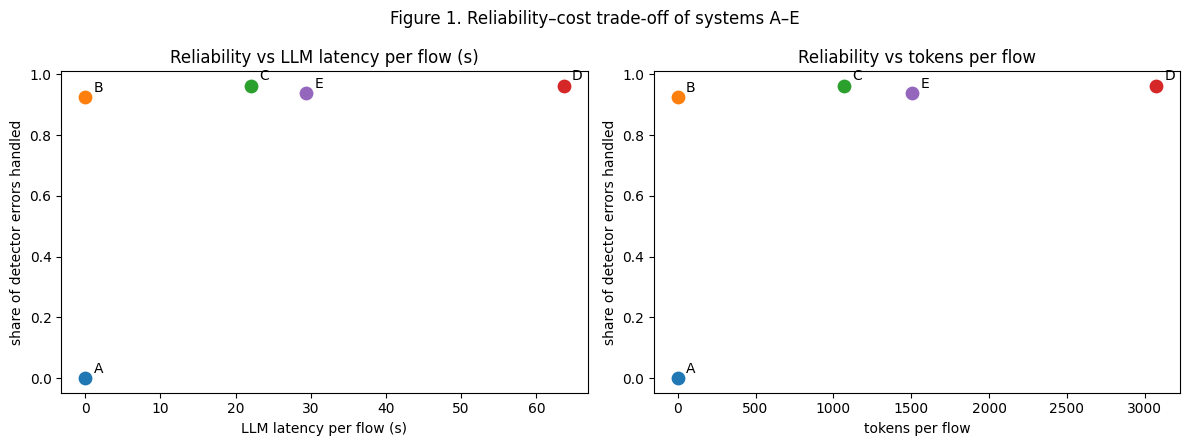


cost_profile.csv:


,Unnamed: 0,train_seconds,model_size_mb,training_rows,imbalance,latency_ms_p50,latency_ms_p95,throughput_flows_per_s,shap_ms_per_flow,device,peak_ram_gb_process
0,rf,144.7,8.54,321277.0,class_weight,45.495,55.741,113850.116,127.68,cuda,10.17
1,xgb,18.3,7.77,321277.0,class_weight,8.000,10.930,525370.841,0.32,cuda,10.17
2,mlp,7.0,0.81,328099.0,smote,0.576,0.683,4066315.094,101.19,cuda,10.17
3,iforest,1.4,6.27,180000.0,NaN,18.242,22.856,47555.592,NaN,cuda,10.17
4,autoencoder,16.2,0.06,180000.0,NaN,0.504,0.607,6372105.471,NaN,cuda,10.17



attack_cost.csv:


,attack,target,ms_per_flow,queries_per_flow
0,heuristic,none,0.01,0.0
1,noise,none,0.01,0.0
2,zoo,mlp,2.24,141.0
3,zoo,rf,9.05,141.0
4,zoo,xgb,3.91,141.0
5,shap_on_attacked_flows,rf,123.59,NaN
6,shap_on_attacked_flows,xgb,0.72,NaN
7,shap_on_attacked_flows,mlp,98.31,NaN



cost_policy.csv:


,component,ms_per_flow
0,"classifier xgb + calibration (batched, this part)",0.0141
1,"classifier xgb, single-flow p50 (Part 2)",8.0000
2,"anomaly detector autoencoder, single-flow p50 ...",0.5040
3,TreeSHAP of the predicted class (batched),0.2440
4,stability: prototype similarity,0.0003
5,policy decision (thresholds),0.0002


In [114]:
TRADE = SUMMARY[["auto_coverage", "auto_macro_f1", "error_handled", "llm_calls_per_flow", "tokens_per_flow", "latency_s_per_flow"]].copy()
pi, po = CONFIG["price_per_mtok_input"], CONFIG["price_per_mtok_output"]
if pi is not None and po is not None and CONFIG["backend"] == "anthropic":
    tok = pd.DataFrame({k: {"in": wmean(g.in_tok.fillna(0), g.weight), "out": wmean(g.out_tok.fillna(0), g.weight)} for k, g in R.groupby("system")}).T
    TRADE["usd_per_1000_flows"] = 1000 * (tok["in"] * pi + tok["out"] * po) / 1e6
else:
    TRADE["usd_per_1000_flows"] = np.nan
TRADE["gpu_hours_per_1000_flows"] = TRADE["latency_s_per_flow"] * 1000 / 3600 if CONFIG["backend"] == "hf" else np.nan
TRADE.to_csv(OUT / "rq4_tradeoffs.csv"); display(TRADE.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, xcol, xl in [(axes[0], "latency_s_per_flow", "LLM latency per flow (s)"), (axes[1], "tokens_per_flow", "tokens per flow")]:
    for sysname, r in TRADE.iterrows():
        ax.scatter(r[xcol], r["error_handled"], s=80)
        ax.annotate(sysname.split(" ")[0], (r[xcol], r["error_handled"]), textcoords="offset points", xytext=(6, 4))
    ax.set(xlabel=xl, ylabel="share of detector errors handled", title=f"Reliability vs {xl}")
plt.suptitle("Figure 1. Reliability–cost trade-off of systems A–E"); plt.tight_layout()
plt.savefig(OUT / "figures" / "rq4_tradeoffs.png", dpi=200, bbox_inches="tight"); plt.show()
for label, path in COST_PATHS.items():
    if path: print(f"\n{label}:"); display(pd.read_csv(path).head(20))

## 5.14 · Example reports and run record

In [115]:
ex_rows = []
for sysname in [SYS["C"], SYS["D"], SYS["E"]]:
    sub = R[(R.system == sysname) & R.get("report", pd.Series("", index=R.index)).fillna("").astype(bool)]
    for _, r in pd.concat([sub[sub.flagged].head(3), sub[sub.is_evasion].head(2)]).drop_duplicates("sample_id").iterrows():
        ex_rows.append(f"### {sysname} · sample {r.sample_id} · true {name(r.y)} · detector {name(r.pred)} · decision {r.decision} → {name(r.final)}\n\n"
                       f"{r.report}\n\nUnsupported claims: {r.unsupported}\n")
(OUT / "example_reports.md").write_text("\n".join(ex_rows) or "No reports produced.")
display(Markdown("\n".join(ex_rows[:3]) or "No reports produced."))
RUN = {"notebook": "nb5_agents", "timestamp_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "versions": VERSIONS,
       "backend": CONFIG["backend"], "model": getattr(LLM, "model", None),
       "orchestration": "LangGraph" if HAVE_LANGGRAPH else "plain sequential loop (LangGraph not installed)",
       "config": CONFIG, "system_prompt": SYSTEM_RULES, "decision_format": DECISION_FORMAT, "knowledge_base_ids": [k["id"] for k in KB],
       "sample_size": len(SAMPLE), "sample_flagged_share": float(samp_share), "population_flagged_share": float(pop_share),
       "llm_calls": len(CALL_LOG), "cached_calls": int(sum(c["cached"] for c in CALL_LOG)),
       "mock_backend_warning": CONFIG["backend"] == "mock", "smoke_test": CONFIG["smoke_test"]}
(OUT / "run_record_nb5.json").write_text(json.dumps(RUN, indent=2, default=str))

### C single agent · sample 11 · true PortScan · detector Benign · decision escalate → Benign

The system shows conflicting signals regarding the traffic classification. While one model predicts Benign (E1) and another predicts PortScan (E3), the anomaly detector flags the flow as unusual (E4). The confidence-aware mechanism explicitly recommends ESCALATE (E8) due to low confidence and contradictory evidence. Furthermore, the most influential features identified point towards characteristics associated with PortScan activity (E6). Therefore, escalation is warranted to investigate this potentially malicious flow.

Unsupported claims: []

### C single agent · sample 13 · true WebAttack · detector WebAttack · decision revise → WebAttack

Multiple classifiers suggest a WebAttack classification, with the policy detector (0.540 confidence) and the mlp (0.627 confidence) pointing towards this label. Furthermore, the anomaly detector shows a low p-value (0.0107), suggesting the flow is unusual. Although the confidence-aware mechanism flagged the decision as low confidence (E8), the combination of classifier outputs and anomaly score warrants a revision to the WebAttack label.

Unsupported claims: []

### C single agent · sample 19 · true DDoS · detector DDoS · decision revise → DDoS

Multiple classifiers strongly indicate a DDoS attack, with the mlp achieving a perfect confidence score of 1.000. The anomaly detector also shows a low p-value (0.0092), suggesting the flow is highly unusual. Although the confidence-aware mechanism flagged the decision as low confidence (E8), the consensus from the policy detector (0.917) and the similarity to known DDoS flows (E7) warrants labeling this as DDoS.

Unsupported claims: []


2260

## 5.15 · Answers to RQ3 and RQ4

In [116]:
def s(sysk, col): return float(SUMMARY.loc[SYS[sysk], col]) if col in SUMMARY and pd.notna(SUMMARY.loc[SYS[sysk], col]) else float("nan")
def b(a, bb, m):
    r = BOOT[(BOOT.comparison == f"{SYS[a]} minus {SYS[bb]}") & (BOOT.metric == m)].iloc[0]
    return f"{r.difference:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}], {'established' if r.established else 'not established'}"
warn = ""
if CONFIG["backend"] == "mock": warn += "> ⚠ **MOCK BACKEND: these numbers test the code only and must not be reported.**\n>\n"
if CONFIG["smoke_test"]: warn += "> ⚠ **SMOKE TEST (20 flows): rerun with `smoke_test = False` before reporting.**\n>\n"
display(Markdown(f"""> #### RQ3 and RQ4 · Answers (generated from this run: {CONFIG['backend']} · {getattr(LLM, 'model', '')})
{warn}> **RQ3 · Reliability.** Share of the policy detector's wrong predictions that were escalated or corrected:
> A {s('A', 'error_handled'):.3f} · B {s('B', 'error_handled'):.3f} · C {s('C', 'error_handled'):.3f} · D {s('D', 'error_handled'):.3f} · **E {s('E', 'error_handled'):.3f}**.
> Macro-F1 of automatic decisions: A {s('A', 'auto_macro_f1'):.3f} · B {s('B', 'auto_macro_f1'):.3f} · C {s('C', 'auto_macro_f1'):.3f} · D {s('D', 'auto_macro_f1'):.3f} · E {s('E', 'auto_macro_f1'):.3f}.
> E vs D (same agents, with vs without the mechanism): errors handled {b('E', 'D', 'error_handled')}.
> D vs C (multi-agent vs single agent): errors handled {b('D', 'C', 'error_handled')}.
> E vs B (does the LLM add to the deterministic pipeline?): errors handled {b('E', 'B', 'error_handled')}.
>
> **Grounding.** Unsupported-claim rate: C {s('C', 'unsupported_claim_rate'):.3f} · D {s('D', 'unsupported_claim_rate'):.3f} · E {s('E', 'unsupported_claim_rate'):.3f};
> invalid-JSON rate: C {s('C', 'invalid_json_rate'):.3f} · D {s('D', 'invalid_json_rate'):.3f} · E {s('E', 'invalid_json_rate'):.3f}.
>
> **RQ4 · Cost.** LLM calls per flow: C {s('C', 'llm_calls_per_flow'):.2f} · D {s('D', 'llm_calls_per_flow'):.2f} · E {s('E', 'llm_calls_per_flow'):.2f};
> tokens per flow: C {s('C', 'tokens_per_flow'):,.0f} · D {s('D', 'tokens_per_flow'):,.0f} · E {s('E', 'tokens_per_flow'):,.0f};
> latency per flow: C {s('C', 'latency_s_per_flow'):.2f} s · D {s('D', 'latency_s_per_flow'):.2f} s · E {s('E', 'latency_s_per_flow'):.2f} s.
> E vs D latency: {b('E', 'D', 'latency_s_per_flow')}. The mechanism sends {pop_share:.1%} of test flows to the agents.
>
> **Limits.** One lab dataset (CIC-IDS2017), a simulated attacker within a stated threat model, one LLM, and a weighted sample of {len(SAMPLE)} flows.
"""))
for p in sorted(OUT.rglob("*")):
    if p.is_file(): print(f"{p.stat().st_size / 1e6:8.2f} MB  {p.relative_to(OUT)}")

> #### RQ3 and RQ4 · Answers (generated from this run: hf · google/gemma-4-E2B-it)
> **RQ3 · Reliability.** Share of the policy detector's wrong predictions that were escalated or corrected:
> A 0.000 · B 0.924 · C 0.962 · D 0.962 · **E 0.937**.
> Macro-F1 of automatic decisions: A 0.633 · B 0.958 · C 0.965 · D 0.965 · E 0.954.
> E vs D (same agents, with vs without the mechanism): errors handled -0.024 [-0.059, +0.000], not established.
> D vs C (multi-agent vs single agent): errors handled +0.000 [+0.000, +0.000], not established.
> E vs B (does the LLM add to the deterministic pipeline?): errors handled +0.013 [-0.044, +0.071], not established.
>
> **Grounding.** Unsupported-claim rate: C 0.001 · D 0.000 · E 0.000;
> invalid-JSON rate: C 0.000 · D 0.005 · E 0.000.
>
> **RQ4 · Cost.** LLM calls per flow: C 1.00 · D 3.04 · E 1.58;
> tokens per flow: C 1,068 · D 3,073 · E 1,506;
> latency per flow: C 22.05 s · D 63.63 s · E 29.38 s.
> E vs D latency: -34.244 [-39.633, -28.900], established. The mechanism sends 52.2% of test flows to the agents.
>
> **Limits.** One lab dataset (CIC-IDS2017), a simulated attacker within a stated threat model, one LLM, and a weighted sample of 200 flows.


    0.00 MB  bootstrap_system_differences.csv
    0.04 MB  evaluation_sample.parquet
    0.01 MB  example_reports.md
    0.09 MB  figures/rq4_tradeoffs.png
    0.00 MB  guarded_agents_bootstrap.csv
    0.00 MB  guarded_agents_summary.csv
    0.01 MB  knowledge_base.json
    1.07 MB  llm_cache.jsonl
    0.07 MB  llm_call_log.csv
    0.00 MB  rq4_tradeoffs.csv
    0.00 MB  run_record_nb5.json
    0.07 MB  system_results.parquet
    0.00 MB  systems_summary.csv


### How the results answer the research questions
| RQ | Evidence in this part |
|---|---|
| **RQ3** | `systems_summary.csv` and Section 5.15: reliability and grounding of systems A–E; `bootstrap_system_differences.csv` for E–D, D–C, E–B and E–A |
| **RQ4** | `rq4_tradeoffs.csv`, Figure 1 and the component costs of Parts 2–4 |
| **RQ1–RQ2** | answered in Parts 3 and 4; this part shows what their findings mean for an analyst-facing system |

<a id="llmcmp"></a>
## 5.16 · Comparing LLMs: model size and cybersecurity specialisation
The agents above run on the small **Gemma 4 E2B**. To test whether the agents' result depends on that choice, the *same* agents, prompts, evidence, knowledge base and verifier are re-run with other pretrained LLMs on the *same* 200 flows:

| LLM | Hugging Face ID | Question it answers |
|---|---|---|
| Gemma 4 E2B (primary) | `google/gemma-4-E2B-it` | reference run (results above) |
| **Foundation-Sec 1.1 8B Instruct** (Cisco) | `fdtn-ai/Foundation-Sec-1.1-8B-Instruct` | does a **cybersecurity-specialised** LLM (Llama-3.1-8B further trained on security data) make better decisions? |
| Gemma 4 E4B *(optional)* | `google/gemma-4-E4B-it` | does a **larger model of the same family** help? |

> **In the reported run** only Gemma 4 E4B was compared with the primary E2B model. Foundation-Sec is configured (add it to `LLM_COMPARISON["models"]` below) but was **not** run, so no conclusion about cybersecurity-specialised LLMs is drawn from this run.

By default only system **E** (the proposed system) is re-run for each extra LLM, because it is the system the thesis proposes and it needs the fewest calls (≈ 1.6 per flow); systems A and B do not use an LLM and are shared. Adding `"C"` and `"D"` doubles the run time. Each LLM is compared with the deterministic pipeline B and with the primary Gemma E2B run using the same flow-level paired bootstrap as Section 5.12.

**Loading from Kaggle Models.** Attach a model with *Add Input → Models* and keep its usual name in the list: a model whose Kaggle folder matches the name (e.g. `google/gemma-4-E4B-it` ↔ `.../transformers/gemma-4-e4b-it/1`) is loaded locally — no download, no Hugging Face token, and cached answers stay valid. A Kaggle handle can also be written as `kaggle:<owner>/<model>/transformers/<variation>`; models not attached are downloaded from Hugging Face. Gemma 4 and several Llama and Qwen models are on Kaggle Models; Foundation-Sec is not, so it needs the Hugging Face token.

**Run time on GPU T4 ×2:** ≈ 3–4 h per 8B model for system E (the cache resumes an interrupted run). Accept each model's licence on Hugging Face first; the same `HF_TOKEN` secret is used. Results are saved as `llm_comparison_*.csv` and summarised in Part 6.8.

In [117]:
LLM_COMPARISON = {
    # Hugging Face IDs, or Kaggle Models handles written as "kaggle:<owner>/<model>/transformers/<variation>"
    # (copy the handle from the model page on kaggle.com/models; attach the model with Add Input → Models to skip the download)
    "models": ["google/gemma-4-E4B-it"],     # attached from Kaggle Models; add "fdtn-ai/Foundation-Sec-1.1-8B-Instruct" (needs HF_TOKEN)
    "systems": ["E"],                                       # add "C", "D" for the full comparison (≈ 2× time)
    "time_budget_h": 10.5,                                  # do not start another model after this many hours
}
import gc
SYSFN = {"C": ("C single agent", single_agent, False), "D": ("D multi-agent", multi_agent, False),
         "E": ("E proposed (mechanism + agents)", multi_agent, True)}
PRIMARY = getattr(LLM, "model", CONFIG.get("hf_model"))

def free_llm():
    global LLM
    if hasattr(LLM, "lm"):
        del LLM.lm
    gc.collect()
    try:
        import torch; torch.cuda.empty_cache()
    except Exception:
        pass

def run_agent_systems(systems, tag):
    rows, n_start, t_start = [], len(CALL_LOG), time.perf_counter()
    for i, row in SAMPLE.iterrows():
        base = {"sample_id": int(row.sample_id), "y": int(row.y), "pred": int(row.pred), "weight": float(row.weight),
                "flagged": bool(row.flagged), "policy_decision": row.decision, "variant": row.variant, "group": row.group,
                "is_error": bool(row.is_error), "is_evasion": bool(row.is_evasion), "llm": tag}
        for k in systems:
            sysname, fn, routed = SYSFN[k]
            if routed and not row.flagged:
                rows.append({**base, "system": sysname, "decision": "trust", "final": int(row.pred), "calls": 0, "latency_s": 0.0}); continue
            n0, t0 = len(CALL_LOG), time.perf_counter()
            ans, chk, _ = fn(row, sysname)
            dec = ans.get("decision") if ans and chk["valid_decision"] else "escalate"
            lab = NAME2ID.get(ans.get("final_label"), int(row.pred)) if ans else int(row.pred)
            if dec == "escalate": lab = int(row.pred)
            new = CALL_LOG[n0:]
            rows.append({**base, "system": sysname, "decision": dec, "final": lab, "calls": len(new),
                         "in_tok": sum(c["in_tok"] for c in new), "out_tok": sum(c["out_tok"] for c in new),
                         "latency_s": sum(c["latency_s"] for c in new) if new and all(c["cached"] for c in new) else time.perf_counter() - t0,
                         "valid_json": chk["valid_json"], "n_claims": chk["n_claims"], "n_unsupported": chk["n_unsupported"],
                         "bad_citations": chk["bad_citations"], "report": (ans or {}).get("report", ""),
                         "unsupported": json.dumps(chk["unsupported"])[:2000]})
        if (i + 1) % 25 == 0:
            print(f"    {tag}: {i + 1}/{len(SAMPLE)} flows, {len(CALL_LOG) - n_start} new LLM calls, {time.perf_counter() - t_start:.0f} s")
    return pd.DataFrame(rows)

# primary run (already computed above) + shared non-LLM systems
RX = [R.assign(llm=PRIMARY)]
t_all, done = time.perf_counter(), [PRIMARY]
for m in LLM_COMPARISON["models"]:
    if (time.perf_counter() - t_all) / 3600 > LLM_COMPARISON["time_budget_h"]:
        print(f"time budget reached: {m} not started (re-run this cell in a new session; cached answers are reused)"); continue
    print(f"\n=== {m} ===")
    try:
        free_llm()
        if CONFIG["backend"] == "hf":
            CONFIG["hf_model"] = m; LLM = Backend("hf")
        else:                                    # mock / API backends: label the run so cache keys differ
            LLM = Backend(CONFIG["backend"]); LLM.model = m
        RX.append(run_agent_systems(LLM_COMPARISON["systems"], m)); done.append(m)
    except Exception as e:
        print(f"  {m} failed: {type(e).__name__}: {str(e)[:300]}")
free_llm()
CONFIG["hf_model"] = PRIMARY
RXALL = pd.concat(RX, ignore_index=True)
RXALL.to_parquet(OUT / "llm_comparison_results.parquet", index=False)
pd.DataFrame(CALL_LOG).to_csv(OUT / "llm_call_log.csv", index=False)

# summary per LLM and system (A and B are LLM-free and taken from the primary run)
CMP_ROWS = []
for m in done:
    keys = "ABCDE" if m == PRIMARY else LLM_COMPARISON["systems"]
    for k in keys:
        g = R[R.system == SYS[k]] if m == PRIMARY else RXALL[(RXALL.llm == m) & (RXALL.system == SYS[k])]
        if len(g): CMP_ROWS.append({"llm": m, "system": SYS[k], **summarise(g.reset_index(drop=True)).to_dict()})
LLMCMP = pd.DataFrame(CMP_ROWS)
LLMCMP.to_csv(OUT / "llm_comparison_summary.csv", index=False)

def boot_pair(a, b, label, n=CONFIG["n_boot"]):
    a = a.set_index("sample_id").sort_index(); b = b.set_index("sample_id").sort_index(); idx = a.index.to_numpy()
    rb = np.random.default_rng(SEED); D = {m_: [] for m_ in BOOT_METRICS}
    for _ in range(n):
        s_ = rb.choice(idx, len(idx), replace=True); sa, sb = summarise(a.loc[s_].reset_index()), summarise(b.loc[s_].reset_index())
        for m_ in BOOT_METRICS: D[m_].append(sa[m_] - sb[m_])
    fa, fb = summarise(a.reset_index()), summarise(b.reset_index()); out = []
    for m_ in BOOT_METRICS:
        d = np.array(D[m_], float); d = d[~np.isnan(d)]; lo, hi = np.percentile(d, [2.5, 97.5]) if len(d) else (np.nan, np.nan)
        out.append({"comparison": label, "metric": m_, "difference": fa[m_] - fb[m_], "ci_low": lo, "ci_high": hi, "established": bool(lo > 0 or hi < 0)})
    return out
BL = []
for m in done:
    eg = RXALL[(RXALL.llm == m) & (RXALL.system == SYS["E"])] if m != PRIMARY else R[R.system == SYS["E"]]
    if not len(eg): continue
    BL += boot_pair(eg, R[R.system == SYS["B"]], f"E[{m}] minus B")
    if m != PRIMARY: BL += boot_pair(eg, R[R.system == SYS["E"]], f"E[{m}] minus E[{PRIMARY}]")
LLMBOOT = pd.DataFrame(BL); LLMBOOT.to_csv(OUT / "llm_comparison_bootstrap.csv", index=False)

view = LLMCMP[LLMCMP.system == SYS["E"]].set_index("llm")[["error_handled", "evasion_handled", "auto_macro_f1", "harmful_revisions",
       "unsupported_claim_rate", "invalid_json_rate", "llm_calls_per_flow", "tokens_per_flow", "latency_s_per_flow"]]
display(view.style.format("{:.3f}").set_caption("Table 5.16a · System E with each LLM (same 200 flows, weighted)"))
display(LLMBOOT.round(4))
if CONFIG["backend"] == "mock": print("*** MOCK BACKEND: these numbers test the code only. Do not report them. ***")
print(f"LLMs compared: {', '.join(done)} · total {(time.perf_counter() - t_all) / 3600:.2f} h")



=== google/gemma-4-E4B-it ===
  loading google/gemma-4-E4B-it from attached Kaggle model: /kaggle/input/models/google/gemma-4/transformers/gemma-4-e4b-it/1


    google/gemma-4-E4B-it: 25/200 flows, 15 new LLM calls, 499 s
    google/gemma-4-E4B-it: 50/200 flows, 55 new LLM calls, 1842 s
    google/gemma-4-E4B-it: 75/200 flows, 79 new LLM calls, 2628 s
    google/gemma-4-E4B-it: 100/200 flows, 109 new LLM calls, 3618 s
    google/gemma-4-E4B-it: 125/200 flows, 161 new LLM calls, 5167 s
    google/gemma-4-E4B-it: 150/200 flows, 188 new LLM calls, 5995 s
    google/gemma-4-E4B-it: 175/200 flows, 258 new LLM calls, 8266 s
    google/gemma-4-E4B-it: 200/200 flows, 311 new LLM calls, 10077 s


,error_handled,evasion_handled,auto_macro_f1,harmful_revisions,unsupported_claim_rate,invalid_json_rate,llm_calls_per_flow,tokens_per_flow,latency_s_per_flow
llm,,,,,,,,,
google/gemma-4-E2B-it,0.937,0.963,0.954,0.000,0.000,0.000,1.582,1505.901,29.383
google/gemma-4-E4B-it,0.951,0.949,0.887,0.000,0.017,0.000,1.623,1612.766,52.597


,comparison,metric,difference,ci_low,ci_high,established
0,E[google/gemma-4-E2B-it] minus B,error_handled,0.0132,-0.0436,0.0709,False
1,E[google/gemma-4-E2B-it] minus B,auto_macro_f1,-0.0037,-0.0559,0.0451,False
2,E[google/gemma-4-E2B-it] minus B,tokens_per_flow,1505.9007,1277.1428,1720.6180,True
3,E[google/gemma-4-E2B-it] minus B,latency_s_per_flow,29.3831,24.4759,33.8732,True
4,E[google/gemma-4-E4B-it] minus B,error_handled,0.0264,-0.0236,0.0814,False
5,E[google/gemma-4-E4B-it] minus B,auto_macro_f1,-0.0707,-0.2601,0.0368,False
6,E[google/gemma-4-E4B-it] minus B,tokens_per_flow,1612.7657,1363.4696,1828.6920,True
7,E[google/gemma-4-E4B-it] minus B,latency_s_per_flow,52.5968,44.1712,59.9877,True
8,E[google/gemma-4-E4B-it] minus E[google/gemma-...,error_handled,0.0132,-0.0304,0.0638,False
9,E[google/gemma-4-E4B-it] minus E[google/gemma-...,auto_macro_f1,-0.0671,-0.2544,0.0486,False


LLMs compared: google/gemma-4-E2B-it, google/gemma-4-E4B-it · total 2.81 h


<a id="ablation"></a>
## 5.17 · Agent ablation: what do retrieval and the verifier contribute?
System E is re-run on the same flows with one component removed at a time:

| Variant | What is removed | Expected effect if the component matters |
|---|---|---|
| **no RAG** | the knowledge base: agents see only the model evidence | fewer correct family descriptions; possibly more unsupported claims |
| **no revision** | the verifier's feedback loop: the first answer of the decision agent is kept | more unsupported claims reach the report |

The verifier still *measures* every answer, so grounding can be compared. "No revision" reuses the cached first answers and costs almost nothing; "no RAG" needs new LLM calls (≈ 1–2 h with Gemma 4 E2B).

In [118]:
ABLATION = {"variants": ["no_revision", "no_rag"], "time_budget_h": 4}
# needs Section 5.16 to have been run (it defines run_agent_systems and boot_pair; its model list may be empty)
if CONFIG["backend"] == "hf" and not hasattr(LLM, "lm"):          # 5.16 released the GPU: reload the primary LLM
    CONFIG["hf_model"] = PRIMARY; LLM = Backend("hf")
elif CONFIG["backend"] != "hf":
    LLM = Backend(CONFIG["backend"]); LLM.model = PRIMARY
_retrieve, _maxrev = retrieve, CONFIG["max_revisions"]; t_ab = time.perf_counter(); AB = [R[R.system == SYS["E"]].assign(llm=f"{PRIMARY} · full")]
for v in ABLATION["variants"]:
    if (time.perf_counter() - t_ab) / 3600 > ABLATION["time_budget_h"]:
        print(f"time budget reached: {v} skipped"); continue
    try:
        if v == "no_rag": retrieve = lambda query, k=CONFIG["kb_top_k"]: []
        if v == "no_revision": CONFIG["max_revisions"] = 0
        print(f"=== E · {v} ==="); AB.append(run_agent_systems(["E"], f"{PRIMARY} · {v}"))
    finally:
        retrieve, CONFIG["max_revisions"] = _retrieve, _maxrev
ABALL = pd.concat(AB, ignore_index=True); ABALL.to_parquet(OUT / "agent_ablation_results.parquet", index=False)
ABS = pd.DataFrame([{"variant": tag.split(" · ")[-1], **summarise(g.reset_index(drop=True)).to_dict()} for tag, g in ABALL.groupby("llm", sort=False)]).set_index("variant")
ABS.to_csv(OUT / "agent_ablation_summary.csv")
ABB = []
for tag, g in ABALL.groupby("llm", sort=False):
    if tag.endswith("full"): continue
    ABB += boot_pair(g, R[R.system == SYS["E"]], f"E[{tag.split(' · ')[-1]}] minus E[full]")
ABB = pd.DataFrame(ABB); ABB.to_csv(OUT / "agent_ablation_bootstrap.csv", index=False)
display(ABS[["error_handled", "auto_macro_f1", "unsupported_claim_rate", "invalid_json_rate", "llm_calls_per_flow", "tokens_per_flow", "latency_s_per_flow"]]
        .style.format("{:.3f}").set_caption("Table 5.17 · System E with components removed"))
display(ABB.round(4))
u = ABS["unsupported_claim_rate"]
display(Markdown(f"""> #### Findings · agent ablation
> Unsupported-claim rate: {" · ".join(f"{k} {v:.1%}" for k, v in u.items())}. Errors handled: {" · ".join(f"{k} {v:.3f}" for k, v in ABS["error_handled"].items())}.
>
> **Meaning:** {"the verifier's revision loop is what keeps the reports grounded" if u.get("no_revision", 0) > u.get("full", 0) else "the first answers are already grounded, so the revision loop rarely changes the result"};
> {"removing retrieval changes the decisions" if abs(ABS["error_handled"].get("no_rag", ABS["error_handled"]["full"]) - ABS["error_handled"]["full"]) > 0.02 else "removing retrieval barely changes the decisions, so the knowledge base mainly enriches the explanation rather than the verdict"}.
> Identical numbers across variants mean that these components changed no decision on this sample. That does **not** show the verifier would catch a bad report: Section 5.18 tests that directly by injecting known errors.
"""))
if CONFIG["backend"] == "mock": print("*** MOCK BACKEND: these numbers test the code only. Do not report them. ***")

  loading google/gemma-4-E2B-it from attached Kaggle model: /kaggle/input/models/google/gemma-4/transformers/gemma-4-e2b-it/1


=== E · no_revision ===
    google/gemma-4-E2B-it · no_revision: 25/200 flows, 15 new LLM calls, 0 s
    google/gemma-4-E2B-it · no_revision: 50/200 flows, 54 new LLM calls, 0 s
    google/gemma-4-E2B-it · no_revision: 75/200 flows, 78 new LLM calls, 0 s
    google/gemma-4-E2B-it · no_revision: 100/200 flows, 105 new LLM calls, 0 s
    google/gemma-4-E2B-it · no_revision: 125/200 flows, 156 new LLM calls, 0 s
    google/gemma-4-E2B-it · no_revision: 150/200 flows, 183 new LLM calls, 0 s
    google/gemma-4-E2B-it · no_revision: 175/200 flows, 249 new LLM calls, 0 s
    google/gemma-4-E2B-it · no_revision: 200/200 flows, 300 new LLM calls, 0 s
=== E · no_rag ===
    google/gemma-4-E2B-it · no_rag: 25/200 flows, 15 new LLM calls, 215 s
    google/gemma-4-E2B-it · no_rag: 50/200 flows, 54 new LLM calls, 812 s
    google/gemma-4-E2B-it · no_rag: 75/200 flows, 78 new LLM calls, 1169 s
    google/gemma-4-E2B-it · no_rag: 100/200 flows, 106 new LLM calls, 1577 s
    google/gemma-4-E2B-it · no_

,error_handled,auto_macro_f1,unsupported_claim_rate,invalid_json_rate,llm_calls_per_flow,tokens_per_flow,latency_s_per_flow
variant,,,,,,,
full,0.937,0.954,0.000,0.000,1.582,1505.901,29.383
no_revision,0.937,0.954,0.009,0.000,1.566,1482.381,28.950
no_rag,0.937,0.954,0.003,0.000,1.576,1223.419,22.279


,comparison,metric,difference,ci_low,ci_high,established
0,E[no_revision] minus E[full],error_handled,0.0000,0.0000,0.0000,False
1,E[no_revision] minus E[full],auto_macro_f1,0.0000,0.0000,0.0000,False
2,E[no_revision] minus E[full],tokens_per_flow,-23.5193,-52.9289,0.0000,False
3,E[no_revision] minus E[full],latency_s_per_flow,-0.4331,-0.9683,0.0000,False
4,E[no_rag] minus E[full],error_handled,0.0000,0.0000,0.0000,False
5,E[no_rag] minus E[full],auto_macro_f1,0.0004,0.0000,0.0021,False
6,E[no_rag] minus E[full],tokens_per_flow,-282.4817,-337.1054,-227.6526,True
7,E[no_rag] minus E[full],latency_s_per_flow,-7.1044,-9.1436,-5.0322,True


> #### Findings · agent ablation
> Unsupported-claim rate: full 0.0% · no_revision 0.9% · no_rag 0.3%. Errors handled: full 0.937 · no_revision 0.937 · no_rag 0.937.
>
> **Meaning:** the verifier's revision loop is what keeps the reports grounded;
> removing retrieval barely changes the decisions, so the knowledge base mainly enriches the explanation rather than the verdict.
> Identical numbers across variants mean that these components changed no decision on this sample. That does **not** show the verifier would catch a bad report: Section 5.18 tests that directly by injecting known errors.


<a id="verifiertest"></a>
## 5.18 · Verifier stress test: does the verifier catch known errors?
Sections 5.11 and 5.17 report 0 % unsupported claims for every system and variant. That is only meaningful if the verifier can catch errors at all. This test takes correct claims built from each flow's own evidence, injects one known error at a time and counts how often the verifier flags the claim.

| Case | Expected |
|---|---|
| correct claim citing an evidence or knowledge item | should pass (false-alarm check) |
| citation to a non-existent item · no citation · invented decimal value · attack label absent from the evidence | should be caught (what the verifier was designed for) |
| invented integer · meaning reversed with correct values · real label attributed to the wrong model | known blind spot (reported, not hidden) |

No LLM is called, so the test runs in seconds after Sections 5.1–5.8. Results are saved as `verifier_stress_test.csv` and summarised in Part 6.9 and the threat report.

In [119]:
# 5.18 · Verifier stress test: inject known errors into otherwise correct claims and count how many the verifier catches.
# No LLM calls: runs in seconds once Sections 5.1–5.8 have defined the evidence, retrieval and verifier.
try:
    verify, build_evidence, retrieve, SAMPLE
except NameError:
    raise RuntimeError("Run Sections 5.1–5.8 of Part 5 first: this test uses their verifier, evidence and retrieval.")

def _claim(text, cites):
    return {"text": text, "evidence": list(cites)}

def _shift(v):                       # a plausible-looking decimal that matches no evidence value
    return f"{(float(v) + 0.137) % 1:.3f}"

STRESS = []
for _, row in SAMPLE.iterrows():
    ev = build_evidence(row); ev_ids = [i for i, _ in ev]; ev_txt = dict(ev)
    kb = retrieve(f"{name(row.pred)} " + " ".join(t for _, t in ev))
    nums, model_labels = evidence_values(row)
    kb_text = " ".join(k["text"] + " " + k["title"] for k in kb).lower()
    e1 = ev_txt["E1"]
    anom_id = next(i for i, t in ev if t.startswith("Anomaly detector"))
    foreign = [c for c in CLASS_NAMES if c not in model_labels and c.lower() not in kb_text]
    other_lab = [c for c in model_labels if c in CLASS_NAMES and c != name(row.pred)]
    conf_txt = f"{row.conf:.3f}"
    cases = [
        ("correct claim, evidence item",       "should pass",       _claim(e1, ["E1"])),
        ("correct claim, knowledge item",      "should pass",       _claim(f"The knowledge base describes {kb[0]['title']}.", [kb[0]["id"]]) if kb else None),
        ("citation to a non-existent item",    "should be caught",  _claim(e1, ["E99"])),
        ("claim without citation",             "should be caught",  _claim(e1, [])),
        ("invented decimal value",             "should be caught",  _claim(e1.replace(conf_txt, _shift(row.conf)), ["E1"]) if conf_txt in e1 else None),
        ("attack label absent from evidence",  "should be caught",  _claim(e1 + f" The traffic matches {foreign[0]} activity.", ["E1"]) if foreign else None),
        ("invented integer count",             "known blind spot",  _claim(e1 + " The flow contained 4821 packets.", ["E1"])),
        ("meaning reversed, values unchanged", "known blind spot",  _claim(f"The anomaly detector considers this flow normal ({ev_txt[anom_id]})", [anom_id])
                                                                     if row.anomaly_p < 0.05 else None),
        ("allowed label, wrong model",         "known blind spot",  _claim(f"The policy detector predicts {other_lab[0]}.", ["E1"]) if other_lab else None),
    ]
    for case, expected, claim in cases:
        if claim is None:
            continue                                         # case not applicable to this flow
        chk = verify({"decision": "escalate", "final_label": name(row.pred), "claims": [claim], "report": ""}, row, ev_ids, kb)
        STRESS.append({"sample_id": int(row.sample_id), "case": case, "expected": expected, "caught": chk["n_unsupported"] > 0})

VST = pd.DataFrame(STRESS); VST.to_csv(OUT / "verifier_stress_test.csv", index=False)
VTAB = (VST.groupby(["expected", "case"], sort=False)["caught"].agg(["size", "mean"])
           .rename(columns={"size": "test claims", "mean": "share flagged as unsupported"}))
display(VTAB.style.format({"share flagged as unsupported": "{:.1%}"}).set_caption("Table 5.18 · Verifier stress test (injected errors)"))
k, b, c = (VST[VST.expected == e]["caught"].mean() for e in ["should be caught", "known blind spot", "should pass"])
display(Markdown(f"""> #### Findings · verifier stress test
> The verifier flags **{k:.0%}** of injected citation, decimal-number and label errors, with {c:.0%} false alarms on correct claims,
> but only {b:.0%} of errors it was not designed for (invented integers, reversed meaning, a label that exists in the evidence but is attributed to the wrong model).
>
> **Meaning:** the "0% unsupported claims" of Sections 5.11 and 5.17 rules out *detectable* fabrication (unknown sources, invented decimals, foreign attack labels).
> It does not prove that every sentence is correct; that needs the planned human evaluation (Part 8).
"""))


> #### Findings · verifier stress test
> The verifier flags **100%** of injected citation, decimal-number and label errors, with 0% false alarms on correct claims,
> but only 0% of errors it was not designed for (invented integers, reversed meaning, a label that exists in the evidence but is attributed to the wrong model).
>
> **Meaning:** the "0% unsupported claims" of Sections 5.11 and 5.17 rules out *detectable* fabrication (unknown sources, invented decimals, foreign attack labels).
> It does not prove that every sentence is correct; that needs the planned human evaluation (Part 8).


<a id="llmonly"></a>
## 5.19 · LLM-only classification baseline: can the LLM replace the detector?
The agents above never classify a flow from scratch: they review the detector's evidence. This section measures the obvious alternative, **the LLM as the classifier**. Gemma 4 E2B receives only the flow's feature values (the same features XGBoost uses, in real units) and the list of allowed families with a one-line description each. It gets no detector output, no anomaly evidence, no retrieval and no agents, and must answer with one label.

| Flows | Why |
|---|---|
| the 200 flows of the Part 5 sample (weighted, mostly attacked) | direct comparison with system A (XGBoost alone) on the same flows |
| 98 clean test flows, 14 per family | macro-F1 on normal conditions, where XGBoost is strongest |

Macro-F1 and accuracy are compared with XGBoost on the same flows, with a paired bootstrap interval for the difference. Attacked flows are rebuilt as the attacker sends them (Part 3's adversarial version). An answer without a valid label counts as wrong.

**Time limit.** The cell stops by itself after 60 minutes, or 30 minutes before Kaggle's 12-hour session limit, and reports how many flows it classified. Answers are cached, so re-running the cell continues where it stopped.

In [120]:
# 5.19 · LLM-only classification baseline: Gemma reads the flow's features and names the family on its own
# (no detector output, no anomaly evidence, no retrieval, no agents). Self-limiting: it stops before Kaggle's 12-h limit.
BASELINE = {
    "n_clean_balanced": 98,       # extra clean test flows, equal number per family (macro-F1 on clean traffic)
    "max_minutes": 60,            # never spend more than this on the baseline
    "session_limit_h": 12.0,      # Kaggle GPU session limit
    "reserve_h": 0.5,             # time kept free for Parts 6, 7 and 7b (they need about 5 minutes)
    "max_new_tokens": 64,         # the answer is one short JSON object
}
try:
    import psutil
    _T_SESSION0 = psutil.Process(os.getpid()).create_time()      # kernel start = start of the Kaggle session
except Exception:
    _T_SESSION0 = time.time()
def session_hours(): return (time.time() - _T_SESSION0) / 3600

# ---- 1. raw feature values of the evaluated flows, exactly as the detector saw them (real units, before scaling)
PARAMS_P = json.loads(find_one("preprocessing_params.json").read_text())
FEATS_LLM = [c for c in PARAMS_P["model_features"]]
rng_b = np.random.default_rng(SEED)
cl = FLAGS[(FLAGS["variant"] == "clean")]
per = max(1, BASELINE["n_clean_balanced"] // max(cl["y"].nunique(), 1))
CLEAN_SET = pd.concat([g.sample(min(per, len(g)), random_state=SEED) for _, g in cl.groupby("y")]).reset_index(drop=True)
EVAL_B = pd.concat([SAMPLE.assign(eval_set="Part 5 sample (weighted, mostly attacked)"),
                    CLEAN_SET.assign(eval_set="clean, family-balanced", weight=1.0, sample_id=-1)], ignore_index=True)

clean_cols = pd.read_parquet(find_one("cicids2017_clean.parquet"), columns=FEATS_LLM)
FV = clean_cols.iloc[EVAL_B["row_id"].astype(int).to_numpy()].reset_index(drop=True)
del clean_cols
adv_path = find_one("adversarial_flows.parquet", required=False)
att = (EVAL_B["variant"] == "attacked").to_numpy()
n_rebuilt = 0
if adv_path is not None and att.any():
    A = pd.read_parquet(adv_path)
    A["set"] = A["set"].astype(str).map({"test_lite": "test", "thr_lite": "thr"}).fillna(A["set"].astype(str))
    for c in ["attack", "target"]: A[c] = A[c].astype(str)
    A["eps"] = A["eps"].astype(float).round(6)
    KEY = ["set", "attack", "target", "eps", "row_id"]
    q = EVAL_B.loc[att, KEY].copy()
    for c in ["set", "attack", "target"]: q[c] = q[c].astype(str)
    q["eps"] = q["eps"].astype(float).round(6); q["row_id"] = q["row_id"].astype(int)
    m = q.reset_index().merge(A[KEY + [c for c in FEATS_LLM if c in A.columns]].drop_duplicates(KEY), on=KEY, how="left").set_index("index")
    found = m[[c for c in FEATS_LLM if c in A.columns]].notna().any(axis=1)
    for c in [c for c in FEATS_LLM if c in A.columns]:
        ok = found & m[c].notna()
        FV.loc[ok.index[ok], c] = m.loc[ok, c].to_numpy()
    n_rebuilt = int(found.sum()); del A
FAMILY_HINT = {"Benign": "normal traffic", "Bot": "botnet command-and-control traffic", "BruteForce": "FTP/SSH password guessing",
               "DDoS": "distributed denial of service", "DoS": "denial of service from one source", "PortScan": "port scanning",
               "WebAttack": "attacks on a web application (brute force, XSS, SQL injection)"}
SYS_LLM_ONLY = ("You are a network intrusion-detection classifier. You receive the statistics of ONE network flow, extracted by "
                "CICFlowMeter from the CIC-IDS2017 dataset (durations and inter-arrival times in microseconds, sizes in bytes). "
                "Classify the flow into exactly one of the allowed labels. Reply with one JSON object "
                '{"label": "<allowed label>"} and nothing else.')
def llm_only_prompt(j):
    labs = "; ".join(f"{c} ({FAMILY_HINT[c]})" if c in FAMILY_HINT else c for c in CLASS_NAMES)
    vals = "\n".join(f"{c}: {'missing' if pd.isna(v) else format(float(v), '.6g')}" for c, v in FV.iloc[j].items())
    return f"Allowed labels: {labs}\n\nFlow features:\n{vals}"
def parse_label(text):
    obj = parse_json(text) or {}
    lab = obj.get("label") or obj.get("final_label") if isinstance(obj, dict) else None
    if lab in NAME2ID: return NAME2ID[lab], True
    hits = [c for c in CLASS_NAMES if re.search(rf"(?<![A-Za-z]){re.escape(c)}(?![A-Za-z])", text or "")]
    return (NAME2ID[hits[0]], True) if len(hits) == 1 else (-1, False)          # -1 = no usable answer (counted as wrong)

# ---- 2. the primary LLM must be loaded (Sections 5.16 / 5.17 may have unloaded it)
PRIMARY = globals().get("PRIMARY", CONFIG["hf_model"])
if CONFIG["backend"] == "hf" and (not hasattr(LLM, "lm") or getattr(LLM, "model", None) != PRIMARY):
    if "free_llm" in globals(): free_llm()
    CONFIG["hf_model"] = PRIMARY; LLM = Backend("hf")

# ---- 3. run, flow by flow, with a time guard (answers are cached, so a re-run continues where it stopped)
BROWS, stopped, t0 = [], "", time.perf_counter()
old_max = CONFIG["max_output_tokens"]; CONFIG["max_output_tokens"] = BASELINE["max_new_tokens"]
print(f"session time so far: {session_hours():.2f} h; flows to classify: {len(EVAL_B)}")
try:
    for j in range(len(EVAL_B)):
        done_min = (time.perf_counter() - t0) / 60; per_min = done_min / max(j, 1)
        if done_min + per_min > BASELINE["max_minutes"]:
            stopped = f"own time budget ({BASELINE['max_minutes']} min) reached"; break
        if session_hours() + per_min / 60 > BASELINE["session_limit_h"] - BASELINE["reserve_h"]:
            stopped = f"session close to the {BASELINE['session_limit_h']:.0f}-h limit"; break
        row = EVAL_B.iloc[j]; n0, t1 = len(CALL_LOG), time.perf_counter()
        ctx = mock_ctx(row, ["E1"], []) if CONFIG["backend"] == "mock" else {}
        text = LLM("llm_only", SYS_LLM_ONLY, llm_only_prompt(j), ctx, "LLM-only")
        lab, valid = parse_label(text); new = CALL_LOG[n0:]
        BROWS.append({"eval_set": row.eval_set, "variant": row.variant, "y": int(row.y), "weight": float(row.weight),
                      "xgb": int(row.pred), "llm": lab, "valid": valid,
                      "latency_s": sum(c["latency_s"] for c in new) if new and all(c["cached"] for c in new) else time.perf_counter() - t1,
                      "tokens": sum(c["in_tok"] + c["out_tok"] for c in new)})
        if (j + 1) % 50 == 0:
            print(f"  {j + 1}/{len(EVAL_B)} flows, {time.perf_counter() - t0:.0f} s")
finally:
    CONFIG["max_output_tokens"] = old_max
BR = pd.DataFrame(BROWS); BR.to_parquet(OUT / "llm_only_results.parquet", index=False)
pd.DataFrame(CALL_LOG).to_csv(OUT / "llm_call_log.csv", index=False)

# ---- 4. LLM alone vs XGBoost alone on the same flows
if BR.empty:
    findings([("Flows classified", f"0 / {len(EVAL_B)} ({stopped})"), ("Session time used", f"{session_hours():.2f} h")],
             "not enough session time was left. Attach this run's output (it contains llm_cache.jsonl) and run again: "
             "Part 5 is then read from the cache in minutes and this baseline has the time it needs.")
else:
    def score(d, col):
        w = d["weight"].to_numpy()
        return {"macro_F1": wmacro_f1(d["y"], d[col], w, sorted(d["y"].unique())), "accuracy": wmean((d["y"] == d[col]).to_numpy(), w)}
    XGB_SPF = np.nan                      # XGBoost seconds per flow, from Part 2's cost profile
    try:
        _cp = pd.read_csv(COST_PATHS["cost_profile.csv"])
        _cp = _cp.set_index(_cp.columns[0]) if POLICY not in _cp.index else _cp
        XGB_SPF = 1.0 / float(_cp.loc[POLICY, "throughput_flows_per_s"])
    except Exception:
        pass
    def boot_f1(d, n=CONFIG["n_boot"]):
        rb = np.random.default_rng(SEED); diffs = []
        for _ in range(n):
            s_ = d.iloc[rb.integers(0, len(d), len(d))]
            diffs.append(score(s_, "llm")["macro_F1"] - score(s_, "xgb")["macro_F1"])
        lo, hi = np.nanpercentile(diffs, [2.5, 97.5]); return lo, hi
    TAB, CI = [], {}
    for es, d in BR.groupby("eval_set", sort=False):
        sx, sl = score(d, "xgb"), score(d, "llm"); CI[es] = boot_f1(d) if len(d) >= 20 else (np.nan, np.nan)
        TAB.append({"flows": f"{es} (n = {len(d)})", "model": "XGBoost alone (system A)", **sx, "invalid answers": 0.0,
                    "seconds per flow": XGB_SPF, "tokens per flow": 0})
        TAB.append({"flows": f"{es} (n = {len(d)})", "model": f"LLM alone ({PRIMARY.split('/')[-1]})", **sl,
                    "invalid answers": float((~d["valid"]).mean()), "seconds per flow": float(d["latency_s"].mean()),
                    "tokens per flow": float(d["tokens"].mean())})
    LLMONLY = pd.DataFrame(TAB); LLMONLY.to_csv(OUT / "llm_only_summary.csv", index=False)
    display(LLMONLY.style.format({"macro_F1": "{:.3f}", "accuracy": "{:.3f}", "invalid answers": "{:.1%}",
                                  "seconds per flow": "{:.4g}", "tokens per flow": "{:,.0f}"}, na_rep="–")
            .hide(axis="index").set_caption("Table 5.19 · LLM alone vs XGBoost alone on the same flows (seconds: XGBoost from Part 2)"))

    rows = []
    for es, d in BR.groupby("eval_set", sort=False):
        lo, hi = CI[es]; diff = score(d, "llm")["macro_F1"] - score(d, "xgb")["macro_F1"]
        est = np.isfinite(lo) and (lo > 0 or hi < 0)
        ci = f" [{lo:+.3f}, {hi:+.3f}], {'established' if est else 'not established'}" if np.isfinite(lo) else " (too few flows for an interval)"
        rows.append((f"{es}: macro-F1 LLM − XGBoost", f"{diff:+.3f}{ci}"))
    spf = float(BR["latency_s"].mean()) if len(BR) else np.nan
    rows += [("Flows classified / planned", f"{len(BR)} / {len(EVAL_B)}" + (f" (stopped: {stopped}; re-run this cell to continue from the cache)" if stopped else "")),
             ("Attacked flows rebuilt from Part 3", f"{n_rebuilt} of {int(att.sum())}"),
             ("LLM time per flow → per million flows", f"{spf:.1f} s → {spf * 1e6 / 86400:,.0f} days on one T4" + (f" (XGBoost: {XGB_SPF * 1e6:,.0f} s)" if np.isfinite(XGB_SPF) else "") if np.isfinite(spf) else "–"),
             ("Session time used", f"{session_hours():.2f} h of {BASELINE['session_limit_h']:.0f} h")]
    findings(rows, "the LLM is asked to do XGBoost's job from the same numbers, with no detector output and no retrieval. "
                   "It is orders of magnitude slower, so even an equal score would not make it usable as the detector: this is why the "
                   "project keeps XGBoost for classification and uses the LLM where language matters (evidence-cited analysis and reports).")
if CONFIG["backend"] == "mock": print("*** MOCK BACKEND: these numbers test the code only. Do not report them. ***")

[found] preprocessing_params.json: /kaggle/working/nb1_data_foundation/preprocessing_params.json
[found] cicids2017_clean.parquet: /kaggle/working/nb1_data_foundation/cicids2017_clean.parquet
[found] adversarial_flows.parquet: /kaggle/working/nb3_attacks/adversarial_flows.parquet
session time so far: 11.08 h; flows to classify: 298
  50/298 flows, 44 s
  100/298 flows, 89 s
  150/298 flows, 133 s
  200/298 flows, 174 s
  250/298 flows, 227 s


flows,model,macro_F1,accuracy,invalid answers,seconds per flow,tokens per flow
"Part 5 sample (weighted, mostly attacked) (n = 200)",XGBoost alone (system A),0.633,0.605,0.0%,1.903e-06,0
"Part 5 sample (weighted, mostly attacked) (n = 200)",LLM alone (gemma-4-E2B-it),0.047,0.192,1.5%,0.8695,843
"clean, family-balanced (n = 98)",XGBoost alone (system A),0.958,0.959,0.0%,1.903e-06,0
"clean, family-balanced (n = 98)",LLM alone (gemma-4-E2B-it),0.037,0.143,4.1%,0.9464,829


> #### Findings
> | Check | Result |
> |---|---|
> | Part 5 sample (weighted, mostly attacked): macro-F1 LLM − XGBoost | -0.586 [-0.644, -0.519], established |
> | clean, family-balanced: macro-F1 LLM − XGBoost | -0.921 [-0.955, -0.878], established |
> | Flows classified / planned | 298 / 298 |
> | Attacked flows rebuilt from Part 3 | 156 of 196 |
> | LLM time per flow → per million flows | 0.9 s → 10 days on one T4 (XGBoost: 2 s) |
> | Session time used | 11.15 h of 12 h |
>
> **Meaning:** the LLM is asked to do XGBoost's job from the same numbers, with no detector output and no retrieval. It is orders of magnitude slower, so even an equal score would not make it usable as the detector: this is why the project keeps XGBoost for classification and uses the LLM where language matters (evidence-cited analysis and reports).


> #### ✅ Part 5 · Key takeaways (reported run)
> - **Guarded agents (Section 5.12b, post-hoc):** when the agents may only add caution, system G handles **96.4 %** of errors (B 92.4 %, E 93.7 %, D 96.2 %), but the gain over the rules alone is not established (+0.040 [+0.000, +0.086]); G sends **41.8 %** of flows to an analyst against 38.1 % for E (established). Even guarded, the agents do not add established reliability.
> - **LLM alone (Section 5.19):** classifying flows from their features alone, Gemma 4 E2B reaches macro-F1 **0.047** against **0.633** for XGBoost on the Part 5 sample, and 0.037 against 0.958 on clean, family-balanced flows (accuracy 14 %, chance level for seven families); both gaps are established. At 0.9 s per flow (≈ 10 days per million flows) it is also far too slow to be the detector.
> - 200 test flows (weighted to the test mix), 1,111 Gemma 4 calls, 4.8 h on one T4 GPU.
> - Detector errors handled: **A 0 % · B 92.4 % · C 96.2 % · D 96.2 % · E 93.7 %**. Every system built on the mechanism or agents vastly outperforms the single model (E − A +0.937, established; by construction, since the single model cannot flag its own errors), but the differences between B, C, D and E are **not** statistically established.
> - The agents' reports are well grounded: unsupported-claim rate ≤ 0.13 %, invalid JSON ≤ 0.5 %. This rules out *detectable* fabrication; Section 5.18 shows which errors the verifier can and cannot catch.
> - System E needs **51 % fewer tokens** (1,506 vs 3,073 per flow) and **54 % less time** (29 s vs 64 s per flow) than the conventional multi-agent system D — both established.

↑ back to contents (Notebook 1)

<a id="part6"></a>
# Part 6 · Answers to the Research Questions

This Part brings the evidence of Parts 3–5 together. It reads only the result tables saved by those Parts, draws one figure per research question and writes the answer from the numbers, so the answers stay correct if the pipeline is re-run.

In [121]:
%reset -f
# Part 6 is self-contained: it only reads the result tables saved by Parts 2–5
# (from this session, or from attached outputs of an earlier run).
import os, sys, json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
INPUT_ROOT = Path(os.environ.get("IDS_INPUT_ROOT", "/kaggle/input"))
WORK_ROOT  = Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working"))
FIG6 = WORK_ROOT / "results_synthesis"; FIG6.mkdir(parents=True, exist_ok=True)
MC = {"rf": "#4C72B0", "xgb": "#55A868", "mlp": "#C44E52"}
SC = {"A": "#9E9E9E", "B": "#4C72B0", "C": "#DD8452", "D": "#8172B3", "E": "#55A868"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})

def find_file(name):
    for root in (WORK_ROOT, INPUT_ROOT):
        hits = sorted(root.rglob(name)) if root.exists() else []
        if hits: return hits[0]
    raise FileNotFoundError(f"{name} not found: run Parts 2–5 first, or attach their saved outputs")

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG6 / name, dpi=200, bbox_inches="tight"); plt.show()

DECLINE = pd.read_csv(find_file("macro_f1_decline.csv"), index_col=0)
DECLINE.columns = ["clean"] + [float(c) for c in DECLINE.columns[1:]]
EPS = [c for c in DECLINE.columns if c != "clean"]; EMAX = max(EPS)
RES   = pd.read_csv(find_file("detection_under_attack.csv"))
RQ1T  = pd.read_csv(find_file("rq1_answer_table.csv"), index_col=0)
TESTS = pd.read_csv(find_file("shap_stability_tests.csv"))
WIN   = pd.read_csv(find_file("window_feature_ablation.csv"))
try:
    SIG = pd.read_csv(find_file("indicator_auroc_thr.csv"))
except FileNotFoundError:                     # output of a run made before the file was renamed
    SIG = pd.read_csv(find_file("signal_auroc_thr.csv"))
PEV   = pd.read_csv(find_file("policy_eval_test.csv"))
B4    = pd.read_csv(find_file("bootstrap_flow_level.csv"))
UNS   = pd.read_csv(find_file("unseen_families.csv"))
BASE  = pd.read_csv(find_file("baselines_test.csv"))
COST4 = pd.read_csv(find_file("cost_policy.csv"))
SPEC  = json.load(open(find_file("policy_spec.json")))
TRADE = pd.read_csv(find_file("rq4_tradeoffs.csv"), index_col=0)
SUM5  = pd.read_csv(find_file("systems_summary.csv"), index_col=0)
B5    = pd.read_csv(find_file("bootstrap_system_differences.csv"))
COST2 = pd.read_csv(find_file("cost_profile.csv"), index_col=0)
RUN5  = json.load(open(find_file("run_record_nb5.json")))
BUDGET, FULL = SPEC["false_flag_budget"], "conf+anom+stab"
MODELS = list(DECLINE.index)
def pev(policy, group, col, budget=None):
    r = PEV[(PEV.policy == policy) & (PEV.budget == (BUDGET if budget is None else budget)) & (PEV.group == group)]
    return float(r[col].iloc[0]) if len(r) and pd.notna(r[col].iloc[0]) else np.nan
def sysrow(prefix): return TRADE.index[TRADE.index.str.startswith(prefix)][0]
SYS = {k: sysrow(k) for k in "ABCDE"}
print(f"loaded 17 result tables · policy budget {BUDGET:.0%} · LLM backend {RUN5['backend']} ({RUN5['model']}) · "
      f"{RUN5['sample_size']} agent-evaluated flows")

loaded 17 result tables · policy budget 5% · LLM backend hf (google/gemma-4-E2B-it) · 200 agent-evaluated flows


<a id="rq1"></a>
## 6.1 · RQ1 — Effect of adversarial perturbation on detection and explanations

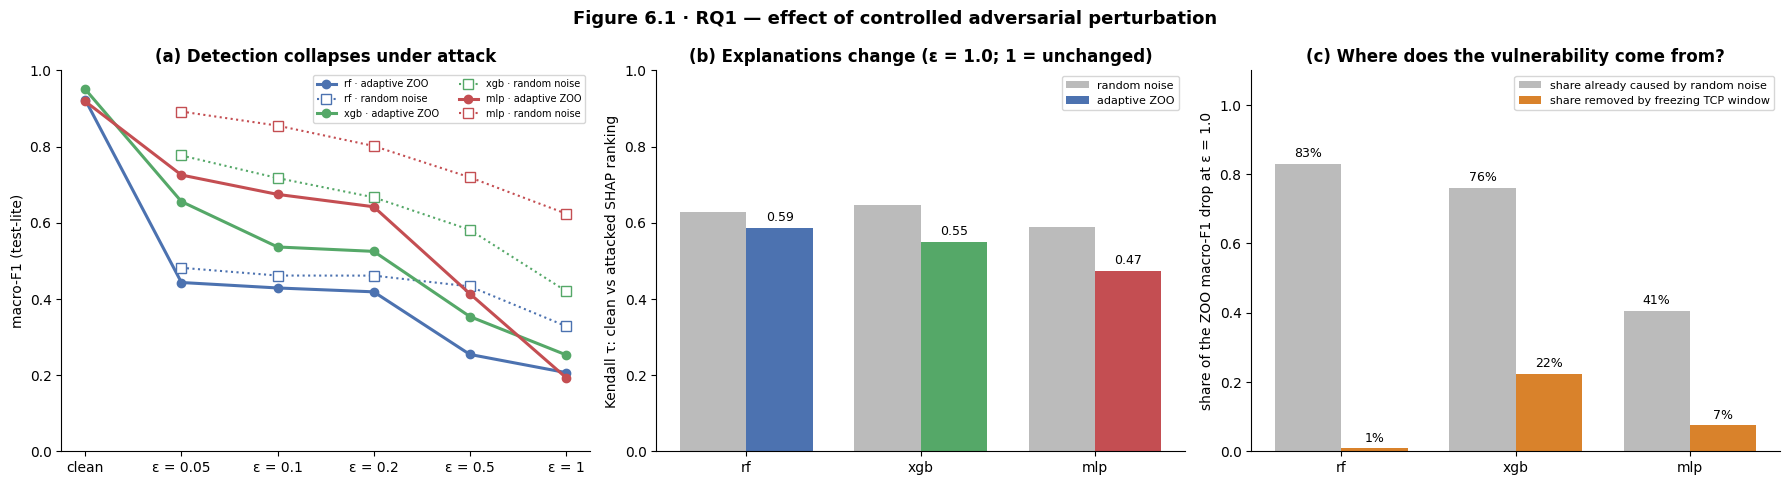

> ### Answer to RQ1
> *How does controlled adversarial perturbation affect the detection performance and explanation stability of the selected intrusion-detection models?*
>
> **Detection performance collapses.** Within a validated threat model (only client-side features, realistic bounds, 0 violations), the adaptive ZOO attack lowers macro-F1 from
> **0.922 → 0.207** (rf), **0.950 → 0.253** (xgb), **0.918 → 0.194** (mlp) at the largest budget, ε = 1.0.
> Even the smallest budget (ε = 0.05) already costs 0.48 (rf), 0.29 (xgb), 0.19 (mlp) macro-F1 points.
> xgb is the most robust model and mlp the least robust at the largest budget; evasion reaches 84% (rf), 79% (xgb), 87% (mlp).
>
> **Explanations become unreliable.** The SHAP ranking of an attacked flow agrees with its clean ranking only at Kendall τ =
> 0.59 (rf), 0.55 (xgb), 0.47 (mlp), significantly lower than under random noise of the same size for 3 of 3 models (Wilcoxon, p < 0.05),
> so the instability is attack-specific. Part 3 also shows that explanations change on many flows whose prediction did *not* flip, so an analyst can be misled even when the alert is correct.
>
> **Nuance.** Random noise of the same size already causes 83% (rf), 76% (xgb), 41% (mlp) of the targeted drop: the models are fragile to *any*
> realistic change of client-side features, and the attack adds a further drop. Freezing the TCP-window feature removes only 1% (rf), 22% (xgb), 7% (mlp)
> of the drop, so the vulnerability is spread over several features rather than one shortcut.


In [122]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.9))
xs = ["clean"] + EPS
ax = axes[0]
for m in MODELS:
    ax.plot(range(len(xs)), [DECLINE.loc[m, c] for c in xs], "-o", color=MC[m], lw=2.2, label=f"{m} · adaptive ZOO")
    nz = RES[(RES["set"] == "test_lite") & (RES["attack"] == "noise") & (RES["evaluated_on"] == m)].sort_values("eps")
    pts = [(xs.index(float(e)), f) for e, f in zip(nz["eps"], nz["macro_F1"]) if float(e) in xs]
    if pts:
        ax.plot(*zip(*pts), ":s", color=MC[m], mfc="white", ms=7, label=f"{m} · random noise")
ax.set_xticks(range(len(xs))); ax.set_xticklabels(["clean"] + [f"ε = {e:g}" for e in EPS])
ax.set_ylim(0, 1); ax.set_ylabel("macro-F1 (test-lite)"); ax.set_title("(a) Detection collapses under attack"); ax.legend(fontsize=7, ncol=2)

ax = axes[1]; w = 0.38; t = TESTS[TESTS["eps"] == EMAX].set_index("model").loc[MODELS]
ax.bar(np.arange(len(MODELS)) - w / 2, t["tau_noise"], w, color="#BBBBBB", label="random noise")
ax.bar(np.arange(len(MODELS)) + w / 2, t["tau_zoo"], w, color=[MC[m] for m in MODELS], label="adaptive ZOO")
for i, m in enumerate(MODELS):
    ax.text(i + w / 2, t.loc[m, "tau_zoo"] + 0.02, f"{t.loc[m, 'tau_zoo']:.2f}", ha="center", fontsize=9)
ax.set_xticks(range(len(MODELS))); ax.set_xticklabels(MODELS); ax.set_ylim(0, 1)
ax.set_ylabel("Kendall τ: clean vs attacked SHAP ranking"); ax.set_title(f"(b) Explanations change (ε = {EMAX:.1f}; 1 = unchanged)"); ax.legend(fontsize=8)

ax = axes[2]
noise_share = [(DECLINE.loc[m, "clean"] - RES[(RES["set"] == "test_lite") & (RES["attack"] == "noise") & (RES["evaluated_on"] == m)
               & (RES["eps"] == EMAX)]["macro_F1"].iloc[0]) / (DECLINE.loc[m, "clean"] - DECLINE.loc[m, EMAX]) for m in MODELS]
win = WIN[WIN["eps"] == EMAX].set_index("model").loc[MODELS]["share of the F1 drop removed by freezing"]
ax.bar(np.arange(len(MODELS)) - w / 2, noise_share, w, color="#BBBBBB", label="share already caused by random noise")
ax.bar(np.arange(len(MODELS)) + w / 2, win, w, color="#D9822B", label="share removed by freezing TCP window")
for i in range(len(MODELS)):
    ax.text(i - w / 2, noise_share[i] + 0.02, f"{noise_share[i]:.0%}", ha="center", fontsize=9)
    ax.text(i + w / 2, win.iloc[i] + 0.02, f"{win.iloc[i]:.0%}", ha="center", fontsize=9)
ax.set_xticks(range(len(MODELS))); ax.set_xticklabels(MODELS); ax.set_ylim(0, 1.1)
ax.set_ylabel(f"share of the ZOO macro-F1 drop at ε = {EMAX:.1f}"); ax.set_title("(c) Where does the vulnerability come from?"); ax.legend(fontsize=8)
plt.suptitle("Figure 6.1 · RQ1 — effect of controlled adversarial perturbation", fontsize=13, fontweight="bold"); savefig("6_1_rq1.png")

EV_COL = [c for c in RQ1T.columns if c.startswith("evasion")][-1]
best, worst = (DECLINE["clean"] - DECLINE[EMAX]).idxmin(), (DECLINE["clean"] - DECLINE[EMAX]).idxmax()
sig = int((t["p: zoo less stable than noise"] < 0.05).sum())
display(Markdown(f"""> ### Answer to RQ1
> *How does controlled adversarial perturbation affect the detection performance and explanation stability of the selected intrusion-detection models?*
>
> **Detection performance collapses.** Within a validated threat model (only client-side features, realistic bounds, 0 violations), the adaptive ZOO attack lowers macro-F1 from
> {", ".join(f"**{DECLINE.loc[m, 'clean']:.3f} → {DECLINE.loc[m, EMAX]:.3f}** ({m})" for m in MODELS)} at the largest budget, ε = {EMAX:.1f}.
> Even the smallest budget (ε = {min(EPS):g}) already costs {", ".join(f"{DECLINE.loc[m, 'clean'] - DECLINE.loc[m, min(EPS)]:.2f} ({m})" for m in MODELS)} macro-F1 points.
> {best} is the most robust model and {worst} the least robust at the largest budget; evasion reaches {", ".join(f"{RQ1T.loc[m, EV_COL]:.0%} ({m})" for m in MODELS)}.
>
> **Explanations become unreliable.** The SHAP ranking of an attacked flow agrees with its clean ranking only at Kendall τ =
> {", ".join(f"{t.loc[m, 'tau_zoo']:.2f} ({m})" for m in MODELS)}, significantly lower than under random noise of the same size for {sig} of {len(MODELS)} models (Wilcoxon, p < 0.05),
> so the instability is attack-specific. Part 3 also shows that explanations change on many flows whose prediction did *not* flip, so an analyst can be misled even when the alert is correct.
>
> **Nuance.** Random noise of the same size already causes {", ".join(f"{s:.0%} ({m})" for m, s in zip(MODELS, noise_share))} of the targeted drop: the models are fragile to *any*
> realistic change of client-side features, and the attack adds a further drop. Freezing the TCP-window feature removes only {", ".join(f"{v:.0%} ({m})" for m, v in win.items())}
> of the drop, so the vulnerability is spread over several features rather than one shortcut.
"""))

<a id="rq2"></a>
## 6.2 · RQ2 — Can the mechanism identify disagreement and wrong decisions?

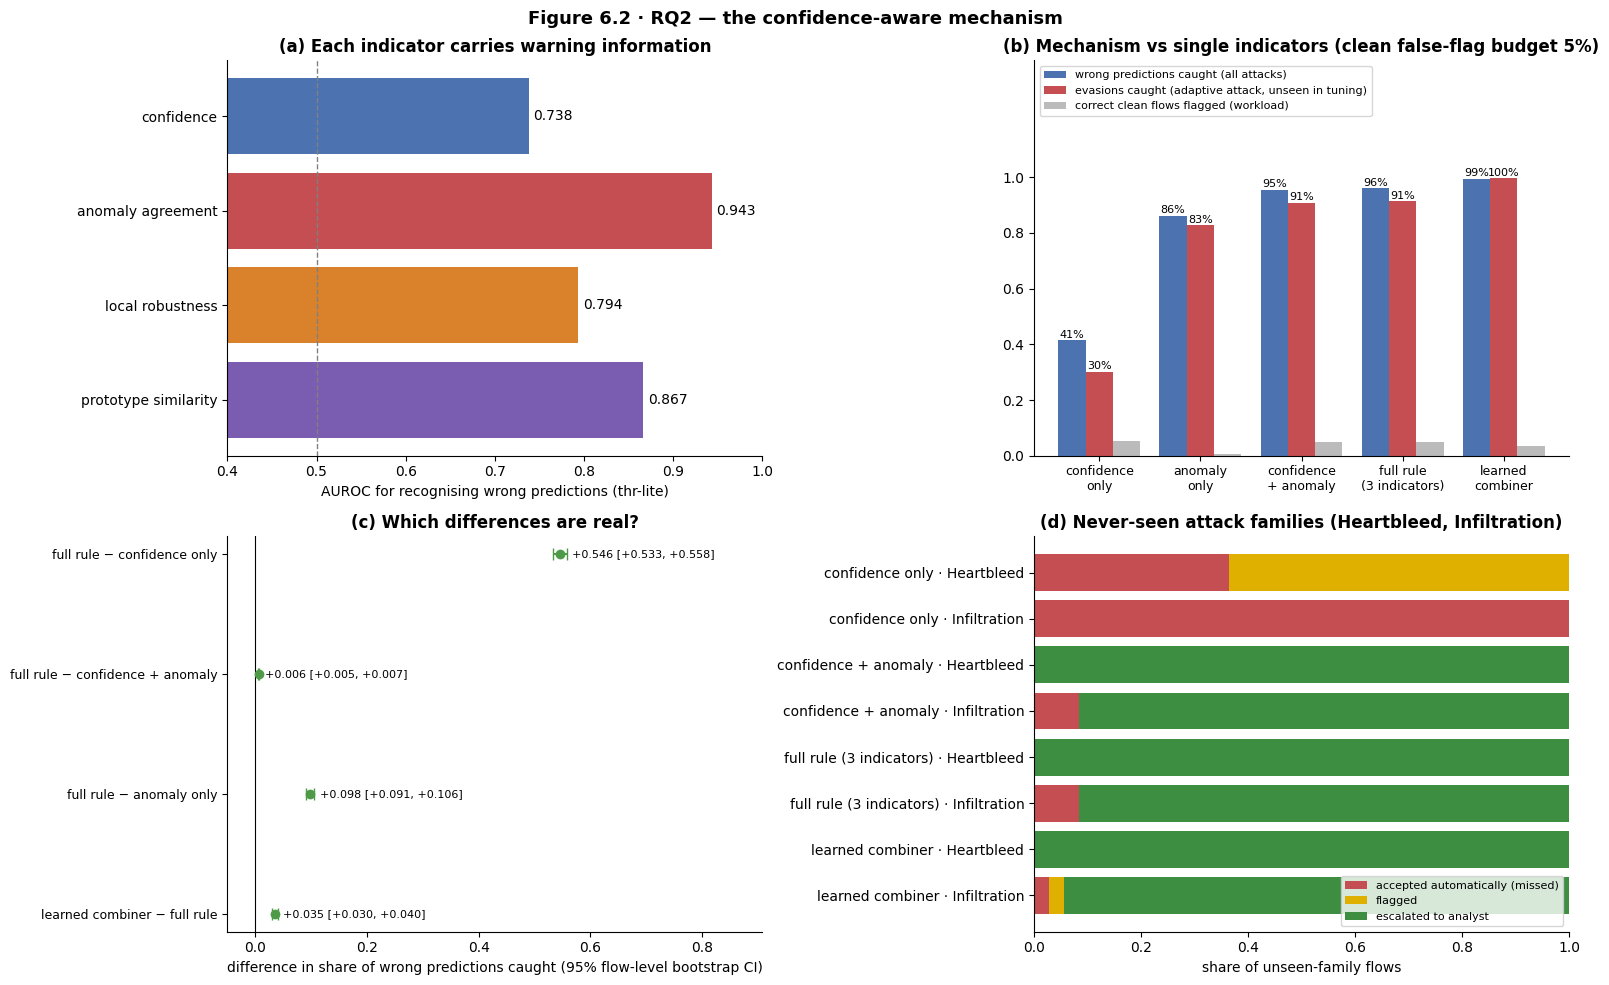

,confidence only,anomaly only,confidence + anomaly,full rule (3 indicators),learned combiner
accepted · clean,0.907,0.991,0.914,0.909,0.921
correct clean flows flagged,0.053,0.007,0.048,0.050,0.036
accepted · attacked,0.671,0.640,0.464,0.461,0.530
errors caught · attacked,0.414,0.862,0.954,0.960,0.995
evasions caught · adaptive ZOO,0.300,0.827,0.909,0.914,0.996
macro-F1 of accepted attacked flows,0.520,0.888,0.835,0.850,0.969


> ### Answer to RQ2
> *Can a confidence-aware decision mechanism identify cases where the classifier, anomaly detector and explanations disagree?*
>
> **Yes.** All three trust indicators carry warning information (AUROC for wrong predictions: confidence 0.738, classifier–anomaly agreement 0.943,
> explanation robustness 0.867). Combined into the accept / flag / escalate rule and tuned so that only 5% of correct clean flows are flagged, the mechanism
> keeps **96.0%** of wrong predictions on attacked traffic away from automatic acceptance (confidence alone 41.4%),
> and catches **91.4%** of successful evasions by an adaptive attack it was never tuned on (confidence alone 30.0%).
> The flows it accepts under attack reach macro-F1 **0.850**, against 0.602 for the detector alone,
> and **94%** of never-seen attack families are flagged or escalated rather than accepted.
>
> **Explanation robustness, the novel indicator,** is a better warning sign of a wrong prediction than the classifier's confidence (AUROC 0.867 vs 0.738).
> Used alone it catches 42.6% of wrong predictions under attack (confidence alone 41.4%), flags 3.6% of correct clean flows
> (confidence alone 5.3%) and reaches macro-F1 0.677 on the attacked flows it accepts (confidence alone 0.520).
> Added to confidence + anomaly evidence, it catches **13% of the errors those two still miss** (+0.006 [+0.005, +0.007], established)
> and changes the macro-F1 of accepted attacked flows by +0.015 [+0.011, +0.018] (established).
>
> **Contribution of each indicator** (flow-level bootstrap, 95% CI): full rule − confidence only +0.546 [+0.533, +0.558]; − anomaly only +0.098 [+0.091, +0.106]; the classifier–anomaly disagreement does most of the work under attack.
> A learned combination of the same indicators adds +0.035 [+0.030, +0.040] (established), at the cost of transparency.
>
> **Cost of the protection.** On clean traffic 90.9% of flows are still accepted automatically; under attack only 46.1% are,
> so the analyst workload rises sharply exactly when the system is attacked (discussed under RQ4).


In [123]:
POL = ["conf", "anom", "conf+anom", FULL, "learned"]
LAB = {"conf": "confidence\nonly", "anom": "anomaly\nonly", "conf+anom": "confidence\n+ anomaly", FULL: "full rule\n(3 indicators)", "learned": "learned\ncombiner"}
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
ax = axes[0, 0]; s = SIG.set_index(next(c for c in ("indicator", "parameter", "signal") if c in SIG.columns)).iloc[:, 0]
SIGC = {"confidence": "#4C72B0", "anomaly agreement": "#C44E52", "local robustness": "#D9822B", "prototype similarity": "#7A5DB0"}
ax.barh(s.index[::-1], s.values[::-1], color=[SIGC.get(i, "#888888") for i in s.index[::-1]])
ax.axvline(0.5, ls="--", c="grey", lw=1); ax.set_xlim(0.4, 1)
for i, v in enumerate(s.values[::-1]): ax.text(v + 0.005, i, f"{v:.3f}", va="center")
ax.set_xlabel("AUROC for recognising wrong predictions (thr-lite)"); ax.set_title("(a) Each indicator carries warning information")

ax = axes[0, 1]; w = 0.27; x = np.arange(len(POL))
e1 = [pev(p, "attacked (all)", "errors_caught") for p in POL]; e2 = [pev(p, "zoo_direct", "evasions_caught") for p in POL]
ff = [pev(p, "clean", "clean_false_flag") for p in POL]
ax.bar(x - w, e1, w, color="#4C72B0", label="wrong predictions caught (all attacks)")
ax.bar(x, e2, w, color="#C44E52", label="evasions caught (adaptive attack, unseen in tuning)")
ax.bar(x + w, ff, w, color="#BBBBBB", label="correct clean flows flagged (workload)")
for xi, v in zip(x, e1): ax.text(xi - w, v + 0.01, f"{v:.0%}", ha="center", fontsize=8)
for xi, v in zip(x, e2): ax.text(xi, v + 0.01, f"{v:.0%}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([LAB[p] for p in POL], fontsize=9); ax.set_ylim(0, 1.42); ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_title(f"(b) Mechanism vs single indicators (clean false-flag budget {BUDGET:.0%})"); ax.legend(fontsize=8, loc="upper left", ncol=1)

ax = axes[1, 0]
b = B4[B4["metric"] == "attacked: errors caught"].reset_index(drop=True)
for i, r in b.iterrows():
    ax.errorbar(r.difference, i, xerr=[[r.difference - r.ci_low], [r.ci_high - r.difference]], fmt="o", color="#4E9A47" if r.established else "grey", capsize=4)
    ax.text(r.ci_high + 0.01, i, f"{r.difference:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}]", va="center", fontsize=8)
PN = {"conf+anom+stab": "full rule", "conf+anom": "confidence + anomaly", "conf": "confidence only", "anom": "anomaly only", "learned": "learned combiner"}
ax.axvline(0, c="black", lw=0.8); ax.set_yticks(range(len(b)))
ax.set_yticklabels([" − ".join(PN.get(x, x) for x in c.split(" minus ")) for c in b["comparison"]], fontsize=9)
ax.set_xlim(min(-0.05, b.ci_low.min() - 0.05), b.ci_high.max() + 0.35); ax.invert_yaxis()
ax.set_xlabel("difference in share of wrong predictions caught (95% flow-level bootstrap CI)"); ax.set_title("(c) Which differences are real?")

ax = axes[1, 1]; u = UNS[UNS["policy"].isin(["conf", "conf+anom", FULL, "learned"])].copy()
u["label"] = u["policy"].map(lambda p: LAB[p].replace("\n", " ")) + " · " + u["family"]
ax.barh(u["label"], u["accepted"], color="#C44E52", label="accepted automatically (missed)")
ax.barh(u["label"], u["flagged"], left=u["accepted"], color="#E0B000", label="flagged")
ax.barh(u["label"], u["escalated"], left=u["accepted"] + u["flagged"], color="#3E8E41", label="escalated to analyst")
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("share of unseen-family flows"); ax.legend(fontsize=8, loc="lower right")
ax.set_title("(d) Never-seen attack families (Heartbleed, Infiltration)")
plt.suptitle("Figure 6.2 · RQ2 — the confidence-aware mechanism", fontsize=13, fontweight="bold"); savefig("6_2_rq2.png")

T2 = pd.DataFrame({LAB[p].replace("\n", " "): {
    "accepted · clean": pev(p, "clean", "coverage"), "correct clean flows flagged": pev(p, "clean", "clean_false_flag"),
    "accepted · attacked": pev(p, "attacked (all)", "coverage"), "errors caught · attacked": pev(p, "attacked (all)", "errors_caught"),
    "evasions caught · adaptive ZOO": pev(p, "zoo_direct", "evasions_caught"),
    "macro-F1 of accepted attacked flows": pev(p, "attacked (all)", "sel_macro_f1")} for p in POL})
display(T2.style.format("{:.3f}").background_gradient(axis=1, cmap="Greens").set_caption("Table 6.1 · Mechanism results on test-lite"))

def bt(comp, metric="attacked: errors caught"):
    r = B4[(B4.comparison == comp) & (B4.metric == metric)].iloc[0]
    return r, f"{r.difference:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}]"
r_conf, s_conf = bt(f"{FULL} minus conf"); r_stab, s_stab = bt(f"{FULL} minus conf+anom")
r_anom, s_anom = bt(f"{FULL} minus anom"); r_lr, s_lr = bt(f"learned minus {FULL}")
un = UNS[UNS.policy == FULL]; un_rate = 1 - (un.accepted * un.flows).sum() / un.flows.sum()
s_auc = SIG.set_index(next(c for c in ("indicator", "parameter", "signal") if c in SIG.columns)).iloc[:, 0]
a_stab = float(s_auc.loc["prototype similarity" if SPEC["stability_variant"] == "proto_sim" else "local robustness"]); a_conf = float(s_auc.iloc[0])
ca_err = pev("conf+anom", "attacked (all)", "errors_caught"); resid = (pev(FULL, "attacked (all)", "errors_caught") - ca_err) / max(1 - ca_err, 1e-9)
r_stab_f1, s_stab_f1 = bt(f"{FULL} minus conf+anom", "attacked: accepted macro-F1")
better = "a better" if a_stab > a_conf else "a weaker"
display(Markdown(f"""> ### Answer to RQ2
> *Can a confidence-aware decision mechanism identify cases where the classifier, anomaly detector and explanations disagree?*
>
> **Yes.** All three trust indicators carry warning information (AUROC for wrong predictions: confidence {s_auc.iloc[0]:.3f}, classifier–anomaly agreement {s_auc.iloc[1]:.3f},
> explanation robustness {s_auc.loc["prototype similarity" if SPEC["stability_variant"] == "proto_sim" else "local robustness"]:.3f}). Combined into the accept / flag / escalate rule and tuned so that only {BUDGET:.0%} of correct clean flows are flagged, the mechanism
> keeps **{pev(FULL, 'attacked (all)', 'errors_caught'):.1%}** of wrong predictions on attacked traffic away from automatic acceptance (confidence alone {pev('conf', 'attacked (all)', 'errors_caught'):.1%}),
> and catches **{pev(FULL, 'zoo_direct', 'evasions_caught'):.1%}** of successful evasions by an adaptive attack it was never tuned on (confidence alone {pev('conf', 'zoo_direct', 'evasions_caught'):.1%}).
> The flows it accepts under attack reach macro-F1 **{pev(FULL, 'attacked (all)', 'sel_macro_f1'):.3f}**, against {pev(FULL, 'attacked (all)', 'full_macro_f1'):.3f} for the detector alone,
> and **{un_rate:.0%}** of never-seen attack families are flagged or escalated rather than accepted.
>
> **Explanation robustness, the novel indicator,** is {better} warning sign of a wrong prediction than the classifier's confidence (AUROC {a_stab:.3f} vs {a_conf:.3f}).
> Used alone it catches {pev('stab', 'attacked (all)', 'errors_caught'):.1%} of wrong predictions under attack (confidence alone {pev('conf', 'attacked (all)', 'errors_caught'):.1%}), flags {pev('stab', 'clean', 'clean_false_flag'):.1%} of correct clean flows
> (confidence alone {pev('conf', 'clean', 'clean_false_flag'):.1%}) and reaches macro-F1 {pev('stab', 'attacked (all)', 'sel_macro_f1'):.3f} on the attacked flows it accepts (confidence alone {pev('conf', 'attacked (all)', 'sel_macro_f1'):.3f}).
> Added to confidence + anomaly evidence, it catches **{resid:.0%} of the errors those two still miss** ({s_stab}, {"established" if r_stab.established else "not established"})
> and changes the macro-F1 of accepted attacked flows by {s_stab_f1} ({"established" if r_stab_f1.established else "not established"}).
>
> **Contribution of each indicator** (flow-level bootstrap, 95% CI): full rule − confidence only {s_conf}; − anomaly only {s_anom}; the classifier–anomaly disagreement does most of the work under attack.
> A learned combination of the same indicators adds {s_lr} ({"established" if r_lr.established else "not established"}), at the cost of transparency.
>
> **Cost of the protection.** On clean traffic {pev(FULL, 'clean', 'coverage'):.1%} of flows are still accepted automatically; under attack only {pev(FULL, 'attacked (all)', 'coverage'):.1%} are,
> so the analyst workload rises sharply exactly when the system is attacked (discussed under RQ4).
"""))

<a id="rq3"></a>
## 6.3 · RQ3 — Does the mechanism improve reliability over individual models and a multi-agent baseline?

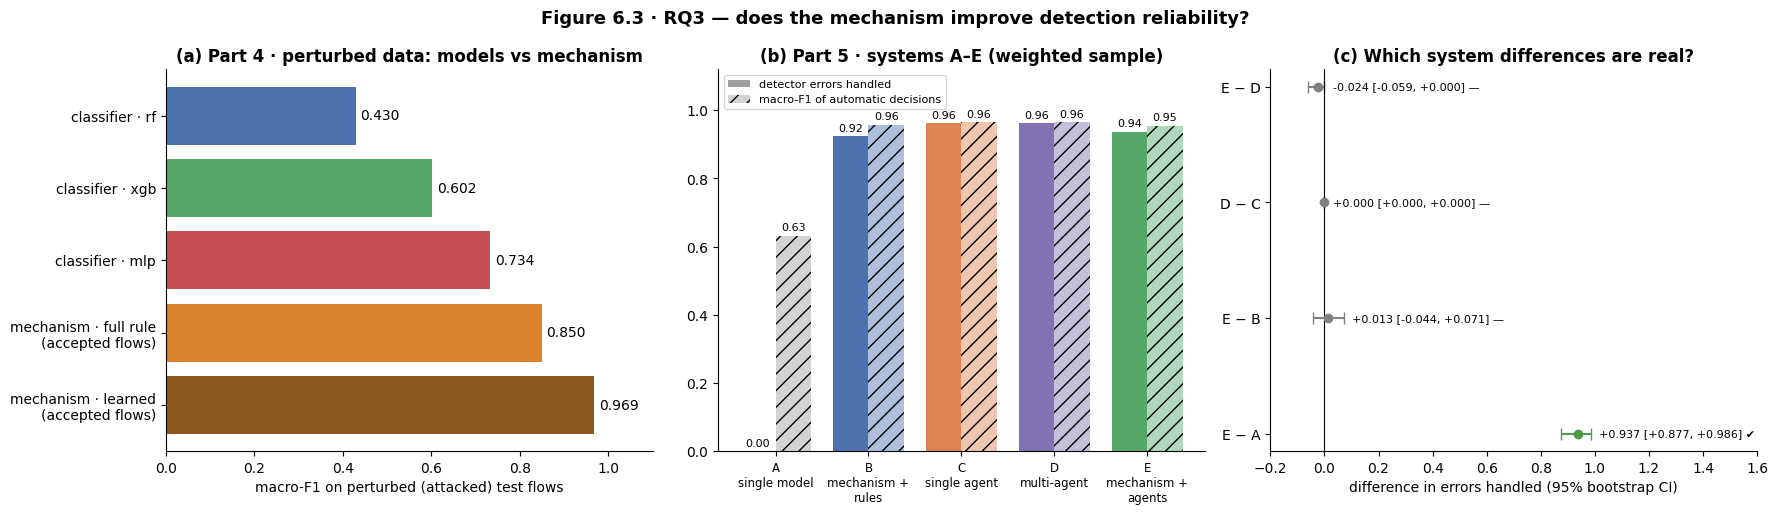

> ### Answer to RQ3
> *Does the proposed mechanism improve detection reliability compared with the individual models and a conventional multi-agent baseline?*
>
> **Against the individual models and the anomaly detector: yes, clearly.** On perturbed test flows the classifiers alone reach macro-F1
> 0.430 (rf), 0.602 (xgb), 0.734 (mlp); the flows the mechanism accepts reach **0.850** (learned variant 0.969).
> The anomaly detector alone separates attacks well (AUROC 0.975) but, used as the only indicator, catches fewer wrong predictions than the full mechanism
> (difference +0.098 [+0.091, +0.106], established). In the agent experiment, system E handles **93.7%** of the detector's errors versus 0% for the single model (+0.937 [+0.877, +0.986], established; the single model cannot flag its own errors, so this comparison mainly shows that routing works).
>
> **Against the conventional multi-agent baseline: no reliability gain.** E vs D: -0.024 [-0.059, +0.000] errors handled (not established);
> multi-agent vs single agent: +0.000 [+0.000, +0.000] (not established); and E vs the non-agentic pipeline B: +0.013 [-0.044, +0.071] (not established).
> The reliability gain therefore comes from the **confidence-aware mechanism**, not from the LLM. The agents contribute **verifiable explanations**: unsupported-claim rates are
> 0.1% (C), 0.0% (D), 0.0% (E), so their reports are grounded in the evidence, but they do not correct more errors.
>
> **Verdict:** RQ3 is **answered**. The mechanism clearly improves reliability over the individual models and the anomaly detector.
> It does **not** improve reliability over the conventional multi-agent system: D handles 96.2% and E 93.7%
> of the detector's errors, and no difference is established on 200 flows ("not established" is not proof of equality).
> E reaches 97% of D's error handling at about half its cost (RQ4);
> the reliability gain comes from the confidence-aware mechanism, not from the LLM agents.


> **Guarded agents (Section 5.12b, post-hoc).** When the agents may only add caution (a flow is decided automatically only if the agents
> and the deterministic check agree), errors handled are **96.4%** (B 92.4%, E 93.7%;
> G − B +0.040 [+0.000, +0.086], not established; G − E +0.026 [+0.000, +0.069], not established), while 41.8% of flows go to an analyst (E 38.1%,
> B 38.6%). Agents are safest when they can raise caution but not lower it; whether that is worth the extra analyst workload is the trade-off of RQ4.

> **Against adversarial training (Part 4b.3).** Retraining the detector on adversarial flows reaches macro-F1 **0.960**
> under the adaptive attack, against 0.465 on the flows the mechanism accepts. On the attack family it was trained on,
> adversarial training is the stronger defence; the mechanism's advantages are that it needs no attack examples, flags never-seen families, and can wrap
> any detector, including an adversarially trained one (not tested here).

In [124]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
ax = axes[0]
items = [(f"classifier · {m}", float(BASE[(BASE.system == f"classifier: {m}") & (BASE.group == "attacked (all)")]["macro_f1"].iloc[0]), MC[m]) for m in MODELS]
items += [("mechanism · full rule\n(accepted flows)", pev(FULL, "attacked (all)", "sel_macro_f1"), "#D9822B"),
          ("mechanism · learned\n(accepted flows)", pev("learned", "attacked (all)", "sel_macro_f1"), "#8C5A1E")]
ax.barh([i[0] for i in items][::-1], [i[1] for i in items][::-1], color=[i[2] for i in items][::-1])
for k, (_, v, _) in enumerate(items[::-1]): ax.text(v + 0.01, k, f"{v:.3f}", va="center")
ax.set_xlim(0, 1.1); ax.set_xlabel("macro-F1 on perturbed (attacked) test flows"); ax.set_title("(a) Part 4 · perturbed data: models vs mechanism")

ax = axes[1]; x = np.arange(5); w = 0.38
eh = [TRADE.loc[SYS[k], "error_handled"] for k in "ABCDE"]; af = [TRADE.loc[SYS[k], "auto_macro_f1"] for k in "ABCDE"]
ax.bar(x - w / 2, eh, w, color=[SC[k] for k in "ABCDE"], label="detector errors handled")
ax.bar(x + w / 2, af, w, color=[SC[k] for k in "ABCDE"], alpha=0.45, hatch="//", label="macro-F1 of automatic decisions")
for xi, v in zip(x, eh): ax.text(xi - w / 2, v + 0.015, f"{v:.2f}", ha="center", fontsize=8)
for xi, v in zip(x, af): ax.text(xi + w / 2, v + 0.015, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(["A\nsingle model", "B\nmechanism +\nrules", "C\nsingle agent", "D\nmulti-agent", "E\nmechanism +\nagents"], fontsize=8.5)
ax.set_ylim(0, 1.12); ax.legend(fontsize=8, loc="upper left"); ax.set_title("(b) Part 5 · systems A–E (weighted sample)")

ax = axes[2]
b = B5[B5["metric"] == "error_handled"].reset_index(drop=True)
lbl = b["comparison"].str.replace(r" \(.*?\)| single model| non-agentic pipeline| single agent| multi-agent| proposed", "", regex=True).str.replace(" minus ", " − ")
for i, r in b.iterrows():
    ax.errorbar(r.difference, i, xerr=[[r.difference - r.ci_low], [r.ci_high - r.difference]], fmt="o", color="#4E9A47" if r.established else "grey", capsize=4)
    ax.text(max(r.ci_high, 0) + 0.03, i, f"{r.difference:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}] {'✔' if r.established else '—'}", va="center", fontsize=8)
ax.axvline(0, c="black", lw=0.8); ax.set_yticks(range(len(b))); ax.set_yticklabels(lbl); ax.invert_yaxis(); ax.set_xlim(-0.2, 1.6)
ax.set_xlabel("difference in errors handled (95% bootstrap CI)"); ax.set_title("(c) Which system differences are real?")
plt.suptitle("Figure 6.3 · RQ3 — does the mechanism improve detection reliability?", fontsize=13, fontweight="bold"); savefig("6_3_rq3.png")

ae = BASE[(BASE.system.str.startswith("anomaly")) & (BASE.group == "attacked (all)")].iloc[0]
def b5(a, c, m="error_handled"):
    r = B5[(B5.comparison == f"{SYS[a]} minus {SYS[c]}") & (B5.metric == m)].iloc[0]
    return r, f"{r.difference:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}]"
rEA, sEA = b5("E", "A"); rED, sED = b5("E", "D"); rDC, sDC = b5("D", "C"); rEB, sEB = b5("E", "B")
gr = {k: SUM5.loc[SYS[k], "unsupported_claim_rate"] for k in "CDE"}
display(Markdown(f"""> ### Answer to RQ3
> *Does the proposed mechanism improve detection reliability compared with the individual models and a conventional multi-agent baseline?*
>
> **Against the individual models and the anomaly detector: yes, clearly.** On perturbed test flows the classifiers alone reach macro-F1
> {", ".join(f"{v:.3f} ({n.split(' · ')[1]})" for n, v, _ in items[:len(MODELS)])}; the flows the mechanism accepts reach **{pev(FULL, 'attacked (all)', 'sel_macro_f1'):.3f}** (learned variant {pev('learned', 'attacked (all)', 'sel_macro_f1'):.3f}).
> The anomaly detector alone separates attacks well (AUROC {ae.auroc_attack_vs_benign:.3f}) but, used as the only indicator, catches fewer wrong predictions than the full mechanism
> (difference {bt(f"{FULL} minus anom")[1]}, established). In the agent experiment, system E handles **{TRADE.loc[SYS['E'], 'error_handled']:.1%}** of the detector's errors versus 0% for the single model ({sEA}, established; the single model cannot flag its own errors, so this comparison mainly shows that routing works).
>
> **Against the conventional multi-agent baseline: no reliability gain.** E vs D: {sED} errors handled ({"established" if rED.established else "not established"});
> multi-agent vs single agent: {sDC} ({"established" if rDC.established else "not established"}); and E vs the non-agentic pipeline B: {sEB} ({"established" if rEB.established else "not established"}).
> The reliability gain therefore comes from the **confidence-aware mechanism**, not from the LLM. The agents contribute **verifiable explanations**: unsupported-claim rates are
> {", ".join(f"{v:.1%} ({k})" for k, v in gr.items())}, so their reports are grounded in the evidence, but they do not correct more errors.
>
> **Verdict:** RQ3 is **answered**. The mechanism clearly improves reliability over the individual models and the anomaly detector.
> It does **not** improve reliability over the conventional multi-agent system: D handles {TRADE.loc[SYS['D'], 'error_handled']:.1%} and E {TRADE.loc[SYS['E'], 'error_handled']:.1%}
> of the detector's errors, and no difference is established on {RUN5['sample_size']} flows ("not established" is not proof of equality).
> E reaches {TRADE.loc[SYS['E'], 'error_handled'] / TRADE.loc[SYS['D'], 'error_handled']:.0%} of D's error handling at about half its cost (RQ4);
> the reliability gain comes from the confidence-aware mechanism, not from the LLM agents.
"""))

# Guarded agents (Part 5, Section 5.12b), if they were evaluated
try:
    _GS = pd.read_csv(find_file("guarded_agents_summary.csv"), index_col=0); _GB = pd.read_csv(find_file("guarded_agents_bootstrap.csv"))
    _g = _GS.index[_GS.index.str.startswith("G ")][0]
    def _gr(k, m="error_handled"):
        r = _GB[(_GB.comparison == f"{_g} minus {SYS[k]}") & (_GB.metric == m)].iloc[0]
        return f"{r.difference:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}], {'established' if r.established else 'not established'}"
    display(Markdown(f"""> **Guarded agents (Section 5.12b, post-hoc).** When the agents may only add caution (a flow is decided automatically only if the agents
> and the deterministic check agree), errors handled are **{_GS.loc[_g, 'error_handled']:.1%}** (B {_GS.loc[SYS['B'], 'error_handled']:.1%}, E {_GS.loc[SYS['E'], 'error_handled']:.1%};
> G − B {_gr('B')}; G − E {_gr('E')}), while {1 - _GS.loc[_g, 'auto_coverage']:.1%} of flows go to an analyst (E {1 - _GS.loc[SYS['E'], 'auto_coverage']:.1%},
> B {1 - _GS.loc[SYS['B'], 'auto_coverage']:.1%}). Agents are safest when they can raise caution but not lower it; whether that is worth the extra analyst workload is the trade-off of RQ4."""))
except FileNotFoundError:
    pass

# Comparison with the standard defence (Part 4b.3), if it was run
try:
    _AT = pd.read_csv(find_file("stress_adversarial_training.csv")).set_index("system"); _c = _AT.columns[2]
    display(Markdown(f"""> **Against adversarial training (Part 4b.3).** Retraining the detector on adversarial flows reaches macro-F1 **{_AT.iloc[1][_c]:.3f}**
> under the adaptive attack, against {_AT.iloc[2][_c]:.3f} on the flows the mechanism accepts. On the attack family it was trained on,
> adversarial training is the stronger defence; the mechanism's advantages are that it needs no attack examples, flags never-seen families, and can wrap
> any detector, including an adversarially trained one (not tested here)."""))
except FileNotFoundError:
    display(Markdown("> Part 4b has not been run: no comparison with adversarial training."))


<a id="rq4"></a>
## 6.4 · RQ4 — Trade-offs between robustness, performance, latency and cost

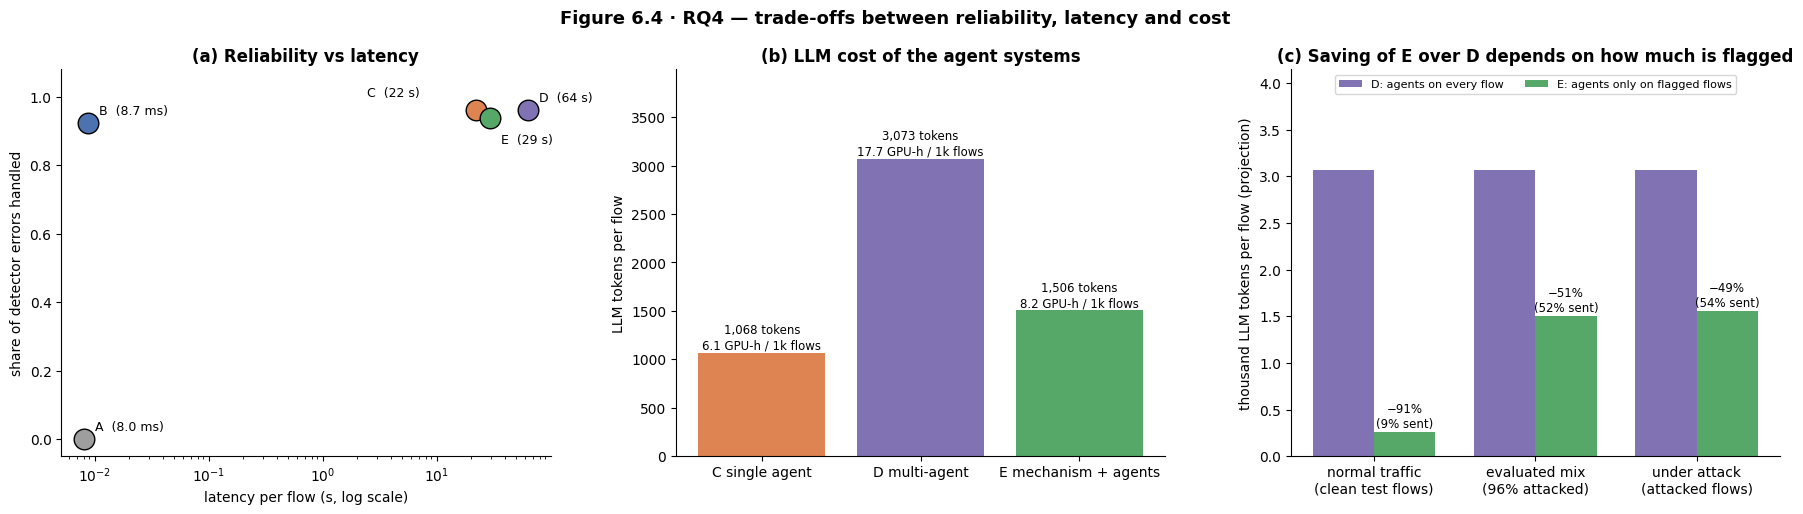

,errors handled,macro-F1 (auto),auto-decided share,LLM calls / flow,tokens / flow,latency / flow (s),"GPU-hours / 1,000 flows"
A · single model,0.000,0.633,1.000,0.00,0,0.008,0.00
B · non-agentic pipeline,0.924,0.958,0.614,0.00,0,0.009,0.00
C · single agent,0.962,0.965,0.620,1.00,"1,068",22.052,6.13
D · multi-agent,0.962,0.965,0.595,3.04,"3,073",63.627,17.67
E · proposed (mechanism + agents),0.937,0.954,0.619,1.58,"1,506",29.392,8.16


component,ms per flow
"classifier xgb + calibration (batched, this part)",0.0141
"classifier xgb, single-flow p50 (Part 2)",8.0000
"anomaly detector autoencoder, single-flow p50 (Part 2)",0.5040
TreeSHAP of the predicted class (batched),0.2440
stability: prototype similarity,0.0003
policy decision (thresholds),0.0002


> ### Answer to RQ4
> *What trade-offs arise between robustness, detection performance, processing latency and computational cost?*
>
> 1. **Robustness is cheap at the mechanism level.** The full mechanism (classifier, anomaly detector, TreeSHAP, prototype similarity and thresholds) costs about
> **8.7 ms per flow**, of which 8.0 ms is the classifier itself, yet raises errors handled from 0 to 92.4% (system B).
> Fast explanation was a design choice: TreeSHAP on XGBoost costs 0.32 ms per flow, against 128 ms (RF) and 101 ms (MLP).
> 2. **LLM agents are three to four orders of magnitude slower.** 22 s (single agent), 64 s (multi-agent) and 29 s (E) per agent-evaluated flow on one T4 GPU:
> suitable for analyst triage and reporting, not for inline detection.
> 3. **The mechanism halves agent cost; no reliability difference is established.** E vs D: tokens per flow -1,566.8 [-1,801.4, -1,328.5], latency -34.2 [-39.6, -28.9] s (both established),
> with no established loss in errors handled. Because E only analyses flagged flows, the saving grows as traffic becomes cleaner: with 9% of clean flows not accepted automatically (the 5% false-flag budget on correct flows plus most of the detector's own errors),
> E would need about 91% fewer tokens than D (projection, Figure 6.4c).
> 4. **The price of robustness is analyst workload under attack.** Catching 96% of wrong predictions means only 46% of attacked flows
> are accepted automatically; a 10% budget or the learned combiner shifts this balance (Sections 4.7–4.8).


In [125]:
mech_rows = COST4[~COST4["component"].str.contains("batched, this")]
mech_ms = float(mech_rows["ms_per_flow"].sum())
lat = {"A": float(COST2.loc["xgb", "latency_ms_p50"]) / 1e3, "B": mech_ms / 1e3}
for k in "CDE": lat[k] = float(TRADE.loc[SYS[k], "latency_s_per_flow"]) + (mech_ms / 1e3 if k == "E" else 0)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
ax = axes[0]
for k in "ABCDE":
    ax.scatter(lat[k], TRADE.loc[SYS[k], "error_handled"], s=220, color=SC[k], edgecolor="black", zorder=3)
    ax.annotate(f"{k}  ({lat[k] * 1e3:.1f} ms)" if lat[k] < 1 else f"{k}  ({lat[k]:.0f} s)", (lat[k], TRADE.loc[SYS[k], "error_handled"]),
                xytext={"C": (-78, 10), "E": (8, -18)}.get(k, (8, 6)), textcoords="offset points", fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("latency per flow (s, log scale)"); ax.set_ylabel("share of detector errors handled")
ax.set_ylim(-0.05, 1.08); ax.set_title("(a) Reliability vs latency")

ax = axes[1]; ks = list("CDE"); x = np.arange(3)
tok = [TRADE.loc[SYS[k], "tokens_per_flow"] for k in ks]; gpu = [TRADE.loc[SYS[k], "gpu_hours_per_1000_flows"] for k in ks]
ax.bar(x, tok, color=[SC[k] for k in ks])
for xi, v, g in zip(x, tok, gpu): ax.text(xi, v + 40, f"{v:,.0f} tokens\n{g:.1f} GPU-h / 1k flows", ha="center", fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels(["C single agent", "D multi-agent", "E mechanism + agents"]); ax.set_ylim(0, max(tok) * 1.3)
ax.set_ylabel("LLM tokens per flow"); ax.set_title("(b) LLM cost of the agent systems")

ax = axes[2]
d_tok = TRADE.loc[SYS["D"], "tokens_per_flow"]; e_tok = TRADE.loc[SYS["E"], "tokens_per_flow"]
per_analysed = e_tok / RUN5["population_flagged_share"]
scen = {"normal traffic\n(clean test flows)": 1 - pev(FULL, "clean", "coverage"),
        "evaluated mix\n(96% attacked)": RUN5["population_flagged_share"],
        "under attack\n(attacked flows)": 1 - pev(FULL, "attacked (all)", "coverage")}
x = np.arange(len(scen)); w = 0.38
ax.bar(x - w / 2, [d_tok / 1e3] * len(scen), w, color=SC["D"], label="D: agents on every flow")
ax.bar(x + w / 2, [per_analysed * s / 1e3 for s in scen.values()], w, color=SC["E"], label="E: agents only on flagged flows")
for xi, s in zip(x, scen.values()):
    ax.text(xi + w / 2, per_analysed * s / 1e3 + 0.05, f"−{1 - per_analysed * s / d_tok:.0%}\n({s:.0%} sent)", ha="center", fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels(list(scen)); ax.set_ylabel("thousand LLM tokens per flow (projection)"); ax.set_ylim(0, d_tok / 1e3 * 1.35)
ax.set_title("(c) Saving of E over D depends on how much is flagged"); ax.legend(fontsize=8, loc="upper center", ncol=2)
plt.suptitle("Figure 6.4 · RQ4 — trade-offs between reliability, latency and cost", fontsize=13, fontweight="bold"); savefig("6_4_rq4.png")

T4 = pd.DataFrame({k + " · " + SYS[k].split(" ", 1)[1]: {
        "errors handled": TRADE.loc[SYS[k], "error_handled"], "macro-F1 (auto)": TRADE.loc[SYS[k], "auto_macro_f1"],
        "auto-decided share": TRADE.loc[SYS[k], "auto_coverage"], "LLM calls / flow": TRADE.loc[SYS[k], "llm_calls_per_flow"],
        "tokens / flow": TRADE.loc[SYS[k], "tokens_per_flow"], "latency / flow (s)": lat[k],
        "GPU-hours / 1,000 flows": TRADE.loc[SYS[k], "gpu_hours_per_1000_flows"]} for k in "ABCDE"}).T
display(T4.style.format({"errors handled": "{:.3f}", "macro-F1 (auto)": "{:.3f}", "auto-decided share": "{:.3f}", "LLM calls / flow": "{:.2f}",
                         "tokens / flow": "{:,.0f}", "latency / flow (s)": "{:.3f}", "GPU-hours / 1,000 flows": "{:.2f}"})
        .set_caption("Table 6.2 · Reliability and cost of systems A–E"))
display(COST4.rename(columns={"ms_per_flow": "ms per flow"}).style.format({"ms per flow": "{:.4f}"}).hide(axis="index")
        .set_caption("Table 6.3 · Per-flow cost of the mechanism's components"))

def b5m(a, c, m):
    r = B5[(B5.comparison == f"{SYS[a]} minus {SYS[c]}") & (B5.metric == m)].iloc[0]
    return f"{r.difference:+,.1f} [{r.ci_low:+,.1f}, {r.ci_high:+,.1f}]"
clean_send = 1 - pev(FULL, "clean", "coverage")
display(Markdown(f"""> ### Answer to RQ4
> *What trade-offs arise between robustness, detection performance, processing latency and computational cost?*
>
> 1. **Robustness is cheap at the mechanism level.** The full mechanism (classifier, anomaly detector, TreeSHAP, prototype similarity and thresholds) costs about
> **{mech_ms:.1f} ms per flow**, of which {float(COST2.loc['xgb', 'latency_ms_p50']):.1f} ms is the classifier itself, yet raises errors handled from 0 to {TRADE.loc[SYS['B'], 'error_handled']:.1%} (system B).
> Fast explanation was a design choice: TreeSHAP on XGBoost costs {float(COST2.loc['xgb', 'shap_ms_per_flow']):.2f} ms per flow, against {float(COST2.loc['rf', 'shap_ms_per_flow']):.0f} ms (RF) and {float(COST2.loc['mlp', 'shap_ms_per_flow']):.0f} ms (MLP).
> 2. **LLM agents are three to four orders of magnitude slower.** {lat['C']:.0f} s (single agent), {lat['D']:.0f} s (multi-agent) and {lat['E']:.0f} s (E) per agent-evaluated flow on one T4 GPU:
> suitable for analyst triage and reporting, not for inline detection.
> 3. **The mechanism halves agent cost; no reliability difference is established.** E vs D: tokens per flow {b5m('E', 'D', 'tokens_per_flow')}, latency {b5m('E', 'D', 'latency_s_per_flow')} s (both established),
> with no established loss in errors handled. Because E only analyses flagged flows, the saving grows as traffic becomes cleaner: with {clean_send:.0%} of clean flows not accepted automatically (the {BUDGET:.0%} false-flag budget on correct flows plus most of the detector's own errors),
> E would need about {1 - per_analysed * clean_send / d_tok:.0%} fewer tokens than D (projection, Figure 6.4c).
> 4. **The price of robustness is analyst workload under attack.** Catching {pev(FULL, 'attacked (all)', 'errors_caught'):.0%} of wrong predictions means only {pev(FULL, 'attacked (all)', 'coverage'):.0%} of attacked flows
> are accepted automatically; a 10% budget or the learned combiner shifts this balance (Sections 4.7–4.8).
"""))

<a id="mainrq"></a>
## 6.5 · Main research question and objectives

In [126]:
obj = pd.DataFrame([
    ["O1 · threat model; macro-F1 decline and SHAP-ranking stability", "RQ1", "✔ fulfilled", "Parts 1 & 3 · Figure 6.1"],
    ["O2 · decision strategy combining confidence, anomaly score and SHAP stability to detect disagreement", "RQ2", "✔ fulfilled", "Part 4 · Figure 6.2"],
    ["O3 · compare with classifiers, anomaly detector and multi-agent system (macro-F1 on perturbed data, errors identified)", "RQ3",
     "✔ answered: better than single detectors; no reliability gain over multi-agent (difference not established), at about half its cost", "Parts 4 & 5 · Figure 6.3"],
    ["O4 · robustness, detection, latency and cost (incl. LLM tokens) of each configuration", "RQ4", "✔ fulfilled", "Parts 2, 4 & 5 · Figure 6.4"]],
    columns=["Objective (PDM)", "RQ", "Status", "Evidence"])
display(obj.style.hide(axis="index").set_properties(**{"text-align": "left"}).set_caption("Table 6.4 · Objectives of the project plan"))
display(Markdown(f"""> ### Answer to the main research question
> *Is there a confidence-based decision-making algorithm which includes the confidence of classifiers, anomaly and explanation robustness which will make the intrusion detection system more robust to attacks?*
>
> **Yes.** The accept / flag / escalate mechanism of Part 4 combines exactly these three trust indicators and makes the intrusion-detection system substantially more robust:
> under realistic adversarial perturbation the detector alone is wrong on about half of the attacked flows, while the mechanism keeps **{pev(FULL, 'attacked (all)', 'errors_caught'):.0%}** of those
> wrong decisions — and **{pev(FULL, 'zoo_direct', 'evasions_caught'):.0%}** of evasions by an adaptive attacker it was never tuned on — away from automatic acceptance, at a {BUDGET:.0%} false-flag cost on normal traffic
> and about {mech_ms:.0f} ms per flow. Explanation robustness, the novel indicator, is {better} warning sign than the classifier's own confidence (AUROC {a_stab:.3f} vs {a_conf:.3f}) and catches {resid:.0%} of the errors that confidence and anomaly evidence still miss; the disagreement between classifier and anomaly detector does most of the work under attack.
> LLM agents built on top of the mechanism produce grounded, verifiable reports at half the cost of a conventional multi-agent system, but do not make the decisions more reliable.
"""))

_lim = []
try:
    _DA = pd.read_csv(find_file("stress_defence_aware.csv")); _e = _DA.eps.max()
    _d = _DA[(_DA.eps == _e) & _DA.attack.str.startswith("defence")].iloc[0]
    _lim.append(f"an attacker who knows the thresholds lowers the share of evasions caught to **{_d['evasions caught by mechanism']:.0%}** (Part 4b.2)")
except FileNotFoundError:
    pass
try:
    _AT = pd.read_csv(find_file("stress_adversarial_training.csv")).set_index("system")
    _lim.append(f"adversarial training reaches **{_AT.iloc[1, 2]:.3f}** macro-F1 against the attack family it was trained on, above the mechanism (Part 4b.3)")
except FileNotFoundError:
    pass
if _lim:
    display(Markdown("> **Limits of this answer.** " + "; ".join(_lim) + ". The mechanism is therefore a robust *safety net*, "
                     "not a replacement for a hardened detector; the two are complementary."))


Objective (PDM),RQ,Status,Evidence
O1 · threat model; macro-F1 decline and SHAP-ranking stability,RQ1,✔ fulfilled,Parts 1 & 3 · Figure 6.1
"O2 · decision strategy combining confidence, anomaly score and SHAP stability to detect disagreement",RQ2,✔ fulfilled,Part 4 · Figure 6.2
"O3 · compare with classifiers, anomaly detector and multi-agent system (macro-F1 on perturbed data, errors identified)",RQ3,"✔ answered: better than single detectors; no reliability gain over multi-agent (difference not established), at about half its cost",Parts 4 & 5 · Figure 6.3
"O4 · robustness, detection, latency and cost (incl. LLM tokens) of each configuration",RQ4,✔ fulfilled,"Parts 2, 4 & 5 · Figure 6.4"


> ### Answer to the main research question
> *Is there a confidence-based decision-making algorithm which includes the confidence of classifiers, anomaly and explanation robustness which will make the intrusion detection system more robust to attacks?*
>
> **Yes.** The accept / flag / escalate mechanism of Part 4 combines exactly these three trust indicators and makes the intrusion-detection system substantially more robust:
> under realistic adversarial perturbation the detector alone is wrong on about half of the attacked flows, while the mechanism keeps **96%** of those
> wrong decisions — and **91%** of evasions by an adaptive attacker it was never tuned on — away from automatic acceptance, at a 5% false-flag cost on normal traffic
> and about 9 ms per flow. Explanation robustness, the novel indicator, is a better warning sign than the classifier's own confidence (AUROC 0.867 vs 0.738) and catches 13% of the errors that confidence and anomaly evidence still miss; the disagreement between classifier and anomaly detector does most of the work under attack.
> LLM agents built on top of the mechanism produce grounded, verifiable reports at half the cost of a conventional multi-agent system, but do not make the decisions more reliable.


> **Limits of this answer.** an attacker who knows the thresholds lowers the share of evasions caught to **56%** (Part 4b.2); adversarial training reaches **0.960** macro-F1 against the attack family it was trained on, above the mechanism (Part 4b.3). The mechanism is therefore a robust *safety net*, not a replacement for a hardened detector; the two are complementary.

<a id="best"></a>
## 6.6 · Best-performing model and per-class evaluation
The supervisor's evaluation design asks for macro-F1, **per-class recall and precision**, and the **false-positive rate**. Table 6.5 compares the three classifiers on the full clean test set and on every attacked test-lite version; Table 6.6 and Figure 6.5 break the best model down per attack family — on clean traffic, under attack, and on the attacked flows the mechanism accepts (the *recovery after the defence*).

,rf,xgb,mlp
clean · macro-F1,0.9461,0.9559,0.9355
clean · macro precision,0.9855,0.9643,0.9581
clean · macro recall,0.9237,0.9488,0.9177
clean · attack detection rate,0.9962,0.9980,0.9897
clean · false-positive rate (benign → attack),0.0003,0.0004,0.0014
attacked · macro-F1,0.4296,0.6023,0.7336
attacked · macro precision,0.8856,0.8786,0.9021
attacked · macro recall,0.4706,0.5877,0.7183
attacked · attack detection rate,0.3884,0.5410,0.6782
attacked · false-positive rate (benign → attack),0.0000,0.0000,0.0000


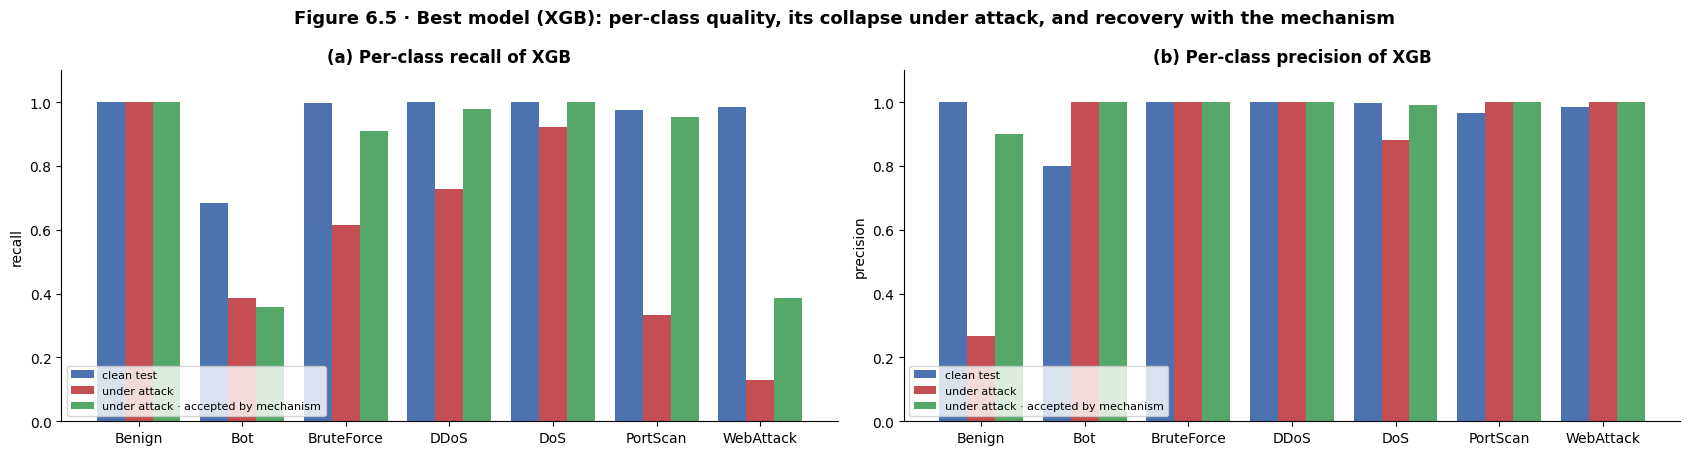

> ### Best-performing model
> **XGB** is the best model on clean traffic: macro-F1 **0.9559**, macro precision 0.9643,
> macro recall 0.9488, attack detection rate 0.9980 and false-positive rate
> 0.00042. It is also the cheapest model to explain (TreeSHAP 0.32 ms per flow), which is why it is the mechanism's policy detector.
> Its weakest family is **Bot** (precision 0.802, recall 0.686); every other family reaches F1 ≥ 0.972.
>
> **No model is robust on its own.** Over all attacked versions the most robust model is **MLP** (macro-F1 0.734, against 0.602 for XGB); for XGB attack detection falls to 54.1%
> and macro-F1 drops by 0.697 under the strongest adaptive attack.
> The **best-performing system** is therefore XGB **with the confidence-aware mechanism**: on the attacked flows it accepts, macro precision is
> 0.984 and macro recall 0.798, against 0.879 and 0.588 without it.


In [127]:
# Uses the tables loaded in 6.0 (run that cell first)
CLASSES = SPEC["class_names"]; K = len(CLASSES); B_ID = int(SPEC["benign_id"])
PC = pd.read_parquet(find_file("predictions_clean.parquet"), columns=["split", "label_id"] + [f"{m}_pred" for m in MODELS])
AP = pd.read_parquet(find_file("attack_predictions.parquet"))
FL = pd.read_parquet(find_file("policy_flags_test.parquet"))

def per_class(y, p):
    y, p = np.asarray(y, int), np.asarray(p, int); rows = []
    for k, cname in enumerate(CLASSES):
        tp = int(((y == k) & (p == k)).sum()); fp = int(((y != k) & (p == k)).sum())
        fn = int(((y == k) & (p != k)).sum()); tn = int(((y != k) & (p != k)).sum())
        pr = tp / (tp + fp) if tp + fp else np.nan; rc = tp / (tp + fn) if tp + fn else np.nan
        rows.append({"family": cname, "support": tp + fn, "precision": pr, "recall": rc,
                     "F1": 2 * pr * rc / (pr + rc) if pr == pr and rc == rc and pr + rc > 0 else (0.0 if tp + fn else np.nan),
                     "FPR": fp / (fp + tn) if fp + tn else np.nan})
    return pd.DataFrame(rows).set_index("family")

def summary(y, p):
    t = per_class(y, p); t = t[t["support"] > 0]; y, p = np.asarray(y), np.asarray(p)
    ben = y == B_ID
    return {"macro-F1": t["F1"].mean(), "macro precision": t["precision"].mean(), "macro recall": t["recall"].mean(),
            "attack detection rate": float((p[~ben] != B_ID).mean()) if (~ben).any() else np.nan,
            "false-positive rate (benign → attack)": float((p[ben] != B_ID).mean()) if ben.any() else np.nan}

clean = PC[PC["split"].astype(str) == "test"]
att = AP[(AP["set"].astype(str) == "test_lite") & (AP["attack"].astype(str) != "clean")]
att_pred = {m: att[[f"{m}_p_{c}" for c in CLASSES]].to_numpy().argmax(1) for m in MODELS}
CMP = pd.DataFrame({m: {**{f"clean · {k}": v for k, v in summary(clean["label_id"], clean[f"{m}_pred"]).items()},
                        **{f"attacked · {k}": v for k, v in summary(att["label_id"], att_pred[m]).items()},
                        f"macro-F1 drop at ε = {EMAX:.1f} (adaptive ZOO)": DECLINE.loc[m, "clean"] - DECLINE.loc[m, EMAX],
                        "latency p50 (ms / flow)": float(COST2.loc[m, "latency_ms_p50"]),
                        "SHAP cost (ms / flow)": float(COST2.loc[m, "shap_ms_per_flow"])} for m in MODELS})
best_clean = CMP.loc["clean · macro-F1"].idxmax(); best_att = CMP.loc["attacked · macro-F1"].idxmax()
display(CMP.style.format("{:.4f}").highlight_max(axis=1, subset=pd.IndexSlice[[i for i in CMP.index if "macro" in i or "detection" in i], :], color="#d7efd7")
        .set_caption(f"Table 6.5 · Model comparison: clean test ({len(clean):,} flows) and all attacked test-lite versions ({len(att):,})"))

FA = FL[(FL["set"].astype(str) == "test") & (FL["variant"].astype(str) == "attacked")]
acc = FA[FA["decision"] == "accept"]
P = SPEC["policy_detector"]
T6 = pd.concat({"clean test": per_class(clean["label_id"], clean[f"{P}_pred"]),
                "under attack": per_class(att["label_id"], att_pred[P]),
                "under attack · accepted by mechanism": per_class(acc["y"], acc["pred"])}, axis=1)
display(T6.style.format({c: ("{:,.0f}" if c[1] == "support" else "{:.3f}") for c in T6.columns})
        .background_gradient(subset=[c for c in T6.columns if c[1] in ("recall", "F1")], cmap="RdYlGn", vmin=0, vmax=1)
        .set_caption(f"Table 6.6 · {P.upper()} per-class precision, recall, F1 and false-positive rate"))

fig, axes = plt.subplots(1, 2, figsize=(17, 4.6)); x = np.arange(K); w = 0.27
for ax, metric in zip(axes, ["recall", "precision"]):
    for j, (lab, col) in enumerate([("clean test", "#4C72B0"), ("under attack", "#C44E52"), ("under attack · accepted by mechanism", "#55A868")]):
        ax.bar(x + (j - 1) * w, T6[(lab, metric)].to_numpy(), w, color=col, label=lab)
    ax.set_xticks(x); ax.set_xticklabels(CLASSES); ax.set_ylim(0, 1.1); ax.set_ylabel(metric)
    ax.set_title(f"({'ab'[metric == 'precision']}) Per-class {metric} of {P.upper()}"); ax.legend(fontsize=8, loc="lower left")
plt.suptitle(f"Figure 6.5 · Best model ({P.upper()}): per-class quality, its collapse under attack, and recovery with the mechanism",
             fontsize=13, fontweight="bold"); savefig("6_5_best_model.png")

pcs = T6["clean test"]; pca = T6["under attack"]; pcm = T6["under attack · accepted by mechanism"]
worst = pcs["F1"].idxmin(); f3 = lambda v: "—" if pd.isna(v) else f"{v:.3f}"
why = (f"It is also the cheapest model to explain (TreeSHAP {CMP.loc['SHAP cost (ms / flow)', P]:.2f} ms per flow), which is why it is the mechanism's policy detector."
       if best_clean == P else f"The mechanism uses {P.upper()} as its policy detector because its SHAP explanations are the cheapest to compute "
       f"({CMP.loc['SHAP cost (ms / flow)', P]:.2f} ms per flow).")
rob = (f"Over all attacked versions {best_att.upper()} also stays best (macro-F1 {CMP.loc['attacked · macro-F1', best_att]:.3f})"
       if best_att == best_clean else
       f"Over all attacked versions the most robust model is **{best_att.upper()}** (macro-F1 {CMP.loc['attacked · macro-F1', best_att]:.3f}, against "
       f"{CMP.loc['attacked · macro-F1', best_clean]:.3f} for {best_clean.upper()})")
display(Markdown(f"""> ### Best-performing model
> **{best_clean.upper()}** is the best model on clean traffic: macro-F1 **{CMP.loc['clean · macro-F1', best_clean]:.4f}**, macro precision {CMP.loc['clean · macro precision', best_clean]:.4f},
> macro recall {CMP.loc['clean · macro recall', best_clean]:.4f}, attack detection rate {CMP.loc['clean · attack detection rate', best_clean]:.4f} and false-positive rate
> {CMP.loc['clean · false-positive rate (benign → attack)', best_clean]:.5f}. {why}
> Its weakest family is **{worst}** (precision {f3(pcs.loc[worst, 'precision'])}, recall {f3(pcs.loc[worst, 'recall'])}); every other family reaches F1 ≥ {pcs.drop(worst)['F1'].min():.3f}.
>
> **No model is robust on its own.** {rob}; for {P.upper()} attack detection falls to {CMP.loc['attacked · attack detection rate', P]:.1%}
> and macro-F1 drops by {CMP.loc[f'macro-F1 drop at ε = {EMAX:.1f} (adaptive ZOO)', P]:.3f} under the strongest adaptive attack.
> The **best-performing system** is therefore {P.upper()} **with the confidence-aware mechanism**: on the attacked flows it accepts, macro precision is
> {pcm['precision'].mean():.3f} and macro recall {pcm['recall'].mean():.3f}, against {pca['precision'].mean():.3f} and {pca['recall'].mean():.3f} without it.
"""))


<a id="checklist"></a>
## 6.7 · Supervisor's evaluation checklist: RAG quality, faithfulness and throughput
Three measures complete the recommended design:

| Measure | How it is computed |
|---|---|
| **Faithfulness** of agent reports | automatic checks on every report: the stated label matches the final decision, the text names no attack family absent from the evidence, and the wording agrees with the decision (trust vs escalate) |
| **Retrieval quality** (RAG) | the threat-intelligence query of Part 5 is re-run; *hit@3* = the knowledge entry of the flow's family is among the 3 retrieved entries. The *true*-family hit shows whether retrieval still supplies the right context when the classifiers are wrong (true labels are used for evaluation only) |
| **Throughput** | flows per second and per hour on one T4 GPU, from the measured latencies |

The section ends with Table 6.10, which maps every row of the supervisor's evaluation design to the measured result.

In [128]:
from sklearn.feature_extraction.text import TfidfVectorizer
RES5 = pd.read_parquet(find_file("system_results.parquet")); SAMP = pd.read_parquet(find_file("evaluation_sample.parquet")).set_index("sample_id")
KB = json.load(open(find_file("knowledge_base.json")))
OTHERS = SPEC["other_models"]
name = lambda k: CLASSES[int(k)]
def labels_in(text):
    return {c for c in CLASSES if re.search(rf"(?<![A-Za-z]){re.escape(c)}(?![A-Za-z])", text, re.I)}
import re

# ---- (1) faithfulness of the agent reports
FAITH = []
for sysname, g in RES5[RES5["system"].str[0].isin(list("CDE"))].groupby("system"):
    g = g[g["report"].fillna("").str.strip().astype(bool)]
    ok_label, ok_foreign, ok_dec = [], [], []
    for r in g.itertuples():
        s = SAMP.loc[r.sample_id]; rep = str(r.report)
        evid = {name(s.pred)} | {name(s[f"pred_{m}"]) for m in OTHERS} | set(str(s.knn_families).split(","))
        said = labels_in(rep)
        esc_words = re.search(r"escalat|analyst|uncertain|insufficient|conflict|inconclusive", rep, re.I) is not None
        ok_label.append(name(r.final) in said or (r.decision == "escalate" and esc_words))
        ok_foreign.append(said <= (evid | {name(r.final)}))
        ok_dec.append(esc_words if r.decision == "escalate" else not re.search(r"\bescalat", rep, re.I))
    a, b, c = map(np.array, (ok_label, ok_foreign, ok_dec))
    FAITH.append({"system": sysname, "reports": len(g), "label consistent with decision": a.mean(),
                  "no label outside the evidence": b.mean(), "decision consistent with text": c.mean(), "faithful (all three)": (a & b & c).mean()})
FAITH = pd.DataFrame(FAITH).set_index("system")

# ---- (2) retrieval quality of the RAG step (threat-intelligence query, as in Part 5)
FAMKB = {"DoS": "K-DOS", "DDoS": "K-DDOS", "PortScan": "K-PORTSCAN", "BruteForce": "K-BRUTE", "WebAttack": "K-WEB", "Bot": "K-BOT", "Benign": "K-BENIGN"}
KB_TEXT = [f"{k['title']}. {k['text']}" for k in KB]
TF = TfidfVectorizer(stop_words="english", ngram_range=(1, 2)).fit(KB_TEXT); KM = TF.transform(KB_TEXT)
hits, hits_pred, rr = [], [], []
for sid, s in SAMP.iterrows():
    cand = {name(s.pred)} | {name(s[f"pred_{m}"]) for m in OTHERS}
    q = " ".join(sorted(cand)) + " " + str(s.top_feature_1) + (" evasion" if bool(s.flagged) else "")
    order = [KB[i]["id"] for i in np.argsort(-(KM @ TF.transform([q]).T).toarray().ravel(), kind="stable")]
    true_id, pred_id = FAMKB.get(name(s.y)), FAMKB.get(name(s.pred))
    hits.append(true_id in order[:3]); hits_pred.append(pred_id in order[:3])
    rr.append(1 / (order.index(true_id) + 1) if true_id in order else 0)
RETR = pd.Series({"hit@3: entry of the TRUE family retrieved": np.mean(hits), "hit@3: entry of the PREDICTED family retrieved": np.mean(hits_pred),
                  "mean reciprocal rank (true family)": np.mean(rr), "citation correctness (1 − bad citations per flow)":
                  1 - float(SUM5.loc[SYS["E"], "bad_citations_per_flow"]) if "bad_citations_per_flow" in SUM5 else np.nan})

# ---- (3) throughput
batched_ms = float(COST4.loc[COST4["component"].str.contains("batched|stability|policy decision"), "ms_per_flow"].sum()
                   + COST2.loc[SPEC["anomaly_detector"], "latency_ms_p50"])
THR = pd.DataFrame({"latency per flow (s)": {k: lat[k] for k in "ABCDE"}})
THR["throughput (flows / s, one stream)"] = 1 / THR["latency per flow (s)"]
THR["flows per hour (one T4)"] = 3600 * THR["throughput (flows / s, one stream)"]
THR.index = [SYS[k] for k in THR.index]

display(FAITH.style.format({c: "{:.3f}" for c in FAITH.columns if c != "reports"}).set_caption("Table 6.7 · Faithfulness of agent reports (automatic checks)"))
display(RETR.to_frame("value").style.format("{:.3f}").set_caption("Table 6.8 · Retrieval (RAG) quality on the evaluation sample"))
display(THR.style.format({"latency per flow (s)": "{:.4f}", "throughput (flows / s, one stream)": "{:,.2f}", "flows per hour (one T4)": "{:,.0f}"})
        .set_caption(f"Table 6.9 · Throughput (mechanism batched: ≈ {1000 / batched_ms:,.0f} flows / s)"))

fe = FAITH.loc[SYS["E"]]
CHECK = pd.DataFrame([
    ["Detection performance", "macro-F1, per-class recall, precision, FPR",
     f"{P.upper()} macro-F1 {CMP.loc['clean · macro-F1', P]:.3f}, recall {CMP.loc['clean · macro recall', P]:.3f}, precision {CMP.loc['clean · macro precision', P]:.3f}, FPR {CMP.loc['clean · false-positive rate (benign → attack)', P]:.5f} · Tables 6.5–6.6"],
    ["Adversarial robustness", "degradation and recovery with the defence",
     f"macro-F1 {DECLINE.loc[P, 'clean']:.3f} → {DECLINE.loc[P, EMAX]:.3f} (ZOO ε = {EMAX:.1f}); accepted attacked macro-F1 {pev(FULL, 'attacked (all)', 'full_macro_f1'):.3f} → {pev(FULL, 'attacked (all)', 'sel_macro_f1'):.3f} · Fig. 6.1, 6.2, 6.5"],
    ["Explanation reliability", "stability of SHAP rankings", f"Kendall τ {TESTS[TESTS.eps == EMAX].set_index('model').loc[P, 'tau_zoo']:.2f} under ZOO vs {TESTS[TESTS.eps == EMAX].set_index('model').loc[P, 'tau_noise']:.2f} under noise · Fig. 6.1"],
    ["RAG quality", "groundedness, faithfulness, citation correctness, unsupported claims",
     f"unsupported claims {SUM5.loc[SYS['E'], 'unsupported_claim_rate']:.1%}; faithful reports {fe['faithful (all three)']:.1%}; true-family hit@3 {RETR.iloc[0]:.1%}; citation correctness {RETR.iloc[3]:.1%} · Tables 6.7–6.8"],
    ["Multi-agent benefit", "vs single agent and non-agentic pipeline", f"D − C {B5[(B5.comparison == SYS['D'] + ' minus ' + SYS['C']) & (B5.metric == 'error_handled')].difference.iloc[0]:+.3f}, E − B {B5[(B5.comparison == SYS['E'] + ' minus ' + SYS['B']) & (B5.metric == 'error_handled')].difference.iloc[0]:+.3f} (not established) · Fig. 6.3"],
    ["Efficiency", "latency, tokens, compute cost, throughput", f"mechanism {mech_ms:.1f} ms/flow (≈ {1000 / batched_ms:,.0f} flows/s batched); agents E {lat['E']:.0f} s/flow, {TRADE.loc[SYS['E'], 'tokens_per_flow']:,.0f} tokens, {TRADE.loc[SYS['E'], 'gpu_hours_per_1000_flows']:.1f} GPU-h/1k flows · Fig. 6.4, Table 6.9"],
    ["Generalisation", "unseen attack categories or another dataset", f"{1 - (UNS[UNS.policy == FULL].accepted * UNS[UNS.policy == FULL].flows).sum() / UNS[UNS.policy == FULL].flows.sum():.0%} of Heartbleed / Infiltration flows not accepted · Fig. 6.2d; second dataset: future work"]],
    columns=["Evaluation area", "Recommended measures", "Measured in this project"])
CHECK.insert(2, "Status", "✔")
display(CHECK.style.hide(axis="index").set_properties(**{"text-align": "left"}).set_caption("Table 6.10 · Supervisor's evaluation design: every recommended measure"))


,reports,label consistent with decision,no label outside the evidence,decision consistent with text,faithful (all three)
system,,,,,
C single agent,200,1.000,0.975,0.990,0.965
D multi-agent,190,1.000,0.974,1.000,0.974
E proposed (mechanism + agents),95,1.000,0.979,1.000,0.979


,value
hit@3: entry of the TRUE family retrieved,0.300
hit@3: entry of the PREDICTED family retrieved,0.570
mean reciprocal rank (true family),0.356
citation correctness (1 − bad citations per flow),1.000


,latency per flow (s),"throughput (flows / s, one stream)",flows per hour (one T4)
A single model,0.0080,125.00,"450,000"
B non-agentic pipeline,0.0087,114.31,"411,499"
C single agent,22.0515,0.05,163
D multi-agent,63.6267,0.02,57
E proposed (mechanism + agents),29.3919,0.03,122


Evaluation area,Recommended measures,Status,Measured in this project
Detection performance,"macro-F1, per-class recall, precision, FPR",✔,"XGB macro-F1 0.956, recall 0.949, precision 0.964, FPR 0.00042 · Tables 6.5–6.6"
Adversarial robustness,degradation and recovery with the defence,✔,"macro-F1 0.950 → 0.253 (ZOO ε = 1.0); accepted attacked macro-F1 0.602 → 0.850 · Fig. 6.1, 6.2, 6.5"
Explanation reliability,stability of SHAP rankings,✔,Kendall τ 0.55 under ZOO vs 0.65 under noise · Fig. 6.1
RAG quality,"groundedness, faithfulness, citation correctness, unsupported claims",✔,unsupported claims 0.0%; faithful reports 97.9%; true-family hit@3 30.0%; citation correctness 100.0% · Tables 6.7–6.8
Multi-agent benefit,vs single agent and non-agentic pipeline,✔,"D − C +0.000, E − B +0.013 (not established) · Fig. 6.3"
Efficiency,"latency, tokens, compute cost, throughput",✔,"mechanism 8.7 ms/flow (≈ 1,311 flows/s batched); agents E 29 s/flow, 1,506 tokens, 8.2 GPU-h/1k flows · Fig. 6.4, Table 6.9"
Generalisation,unseen attack categories or another dataset,✔,94% of Heartbleed / Infiltration flows not accepted · Fig. 6.2d; second dataset: future work


<a id="llm68"></a>
## 6.8 · Does a larger or a security-specialised LLM change the answer to RQ3?
This section reads the comparison saved by Section 5.16. If that section has not been run, it says so and the rest of Part 6 is unaffected.

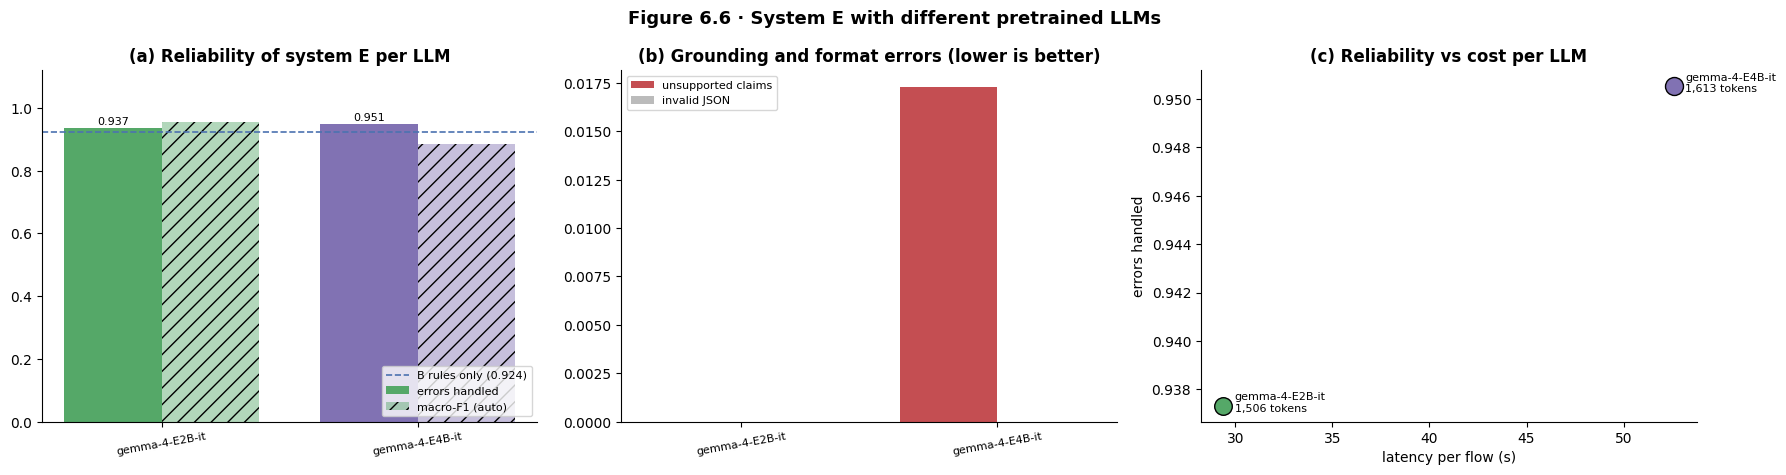

LLM,errors handled,vs B (rules only),vs primary (gemma-4-E2B-it),unsupported claims,tokens / flow,latency / flow (s)
google/gemma-4-E2B-it,0.937,"+0.013 [-0.044, +0.071] (n.s.)",—,0.000,"1,506",29.4
google/gemma-4-E4B-it,0.951,"+0.026 [-0.024, +0.081] (n.s.)","+0.013 [-0.030, +0.064] (n.s.)",0.017,"1,613",52.6


> ### LLM comparison
> Highest share of errors handled by system E: **gemma-4-E4B-it** (0.951; rules-only pipeline B 0.924).
> No LLM makes system E significantly more reliable than the rules-only pipeline B: the conclusion of RQ3 (reliability comes from the mechanism, the agents add evidence-cited explanations) holds across model size within the Gemma 4 family (no cybersecurity-specialised LLM was run, so specialisation is untested).
> No compared LLM is significantly better than the primary gemma-4-E2B-it on errors handled.
> Cost per flow: gemma-4-E2B-it 1,506 tokens and 29 s per flow, gemma-4-E4B-it 1,613 tokens and 53 s per flow.


In [129]:
try:
    LC = pd.read_csv(find_file("llm_comparison_summary.csv")); LB = pd.read_csv(find_file("llm_comparison_bootstrap.csv"))
except FileNotFoundError:
    LC = None
    display(Markdown("> Section 5.16 has not been run yet: no LLM comparison available."))
if LC is not None:
    E = LC[LC.system.str.startswith("E")].set_index("llm"); Bsys = LC[LC.system.str.startswith("B")].iloc[0]
    short = {m: m.split("/")[-1] for m in E.index}
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8)); cols = ["#55A868", "#8172B3", "#DD8452", "#4C72B0"]
    ax = axes[0]; x = np.arange(len(E)); w = 0.38
    ax.bar(x - w / 2, E["error_handled"], w, color=cols[:len(E)], label="errors handled")
    ax.bar(x + w / 2, E["auto_macro_f1"], w, color=cols[:len(E)], alpha=0.45, hatch="//", label="macro-F1 (auto)")
    ax.axhline(Bsys["error_handled"], ls="--", c="#4C72B0", lw=1.2, label=f"B rules only ({Bsys['error_handled']:.3f})")
    for xi, v in zip(x, E["error_handled"]): ax.text(xi - w / 2, v + 0.01, f"{v:.3f}", ha="center", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels([short[m] for m in E.index], fontsize=8, rotation=10); ax.set_ylim(0, 1.12)
    ax.set_title("(a) Reliability of system E per LLM"); ax.legend(fontsize=8, loc="lower right")
    ax = axes[1]
    ax.bar(x - w / 2, E["unsupported_claim_rate"].fillna(0), w, color="#C44E52", label="unsupported claims")
    ax.bar(x + w / 2, E["invalid_json_rate"].fillna(0), w, color="#BBBBBB", label="invalid JSON")
    ax.set_xticks(x); ax.set_xticklabels([short[m] for m in E.index], fontsize=8, rotation=10)
    ax.set_title("(b) Grounding and format errors (lower is better)"); ax.legend(fontsize=8)
    ax = axes[2]
    for (m, r), c in zip(E.iterrows(), cols):
        ax.scatter(r["latency_s_per_flow"], r["error_handled"], s=60 + r["tokens_per_flow"] / 15, color=c, edgecolor="black", zorder=3)
        ax.annotate(f"{short[m]}\n{r['tokens_per_flow']:,.0f} tokens", (r["latency_s_per_flow"], r["error_handled"]), xytext=(8, -4),
                    textcoords="offset points", fontsize=8)
    ax.set_xlabel("latency per flow (s)"); ax.set_ylabel("errors handled"); ax.set_title("(c) Reliability vs cost per LLM")
    plt.suptitle("Figure 6.6 · System E with different pretrained LLMs", fontsize=13, fontweight="bold"); savefig("6_6_llm_comparison.png")

    rows = []
    for m in E.index:
        rb = LB[(LB.comparison == f"E[{m}] minus B") & (LB.metric == "error_handled")]
        rp = LB[(LB.comparison.str.startswith(f"E[{m}] minus E[")) & (LB.metric == "error_handled")]
        f = lambda r: "—" if not len(r) else f"{r.difference.iloc[0]:+.3f} [{r.ci_low.iloc[0]:+.3f}, {r.ci_high.iloc[0]:+.3f}] {'✔' if r.established.iloc[0] else '(n.s.)'}"
        rows.append({"LLM": m, "errors handled": E.loc[m, "error_handled"], "vs B (rules only)": f(rb), f"vs primary ({short[E.index[0]]})": f(rp),
                     "unsupported claims": E.loc[m, "unsupported_claim_rate"], "tokens / flow": E.loc[m, "tokens_per_flow"], "latency / flow (s)": E.loc[m, "latency_s_per_flow"]})
    T7 = pd.DataFrame(rows)
    display(T7.style.format({"errors handled": "{:.3f}", "unsupported claims": "{:.3f}", "tokens / flow": "{:,.0f}", "latency / flow (s)": "{:.1f}"})
            .hide(axis="index").set_caption("Table 6.11 · LLM comparison for the proposed system E (flow-level bootstrap, 95% CI)"))
    better_B = [m for m in E.index if len(LB[(LB.comparison == f"E[{m}] minus B") & (LB.metric == "error_handled") & LB.established & (LB.difference > 0)])]
    better_P = [m for m in E.index if len(LB[(LB.comparison.str.startswith(f"E[{m}] minus E[")) & (LB.metric == "error_handled") & LB.established & (LB.difference > 0)])]
    best = E["error_handled"].idxmax()
    spec = [m for m in E.index if "sec" in m.lower()]
    scope = ("model size and cybersecurity specialisation" if spec else
             "model size within the Gemma 4 family (no cybersecurity-specialised LLM was run, so specialisation is untested)")
    display(Markdown(f"""> ### LLM comparison
> Highest share of errors handled by system E: **{short[best]}** ({E.loc[best, 'error_handled']:.3f}; rules-only pipeline B {Bsys['error_handled']:.3f}).
> {"An LLM that significantly beats the rules-only pipeline: **" + ", ".join(short[m] for m in better_B) + "** — the agents then add reliability, not only explanation." if better_B else
   "No LLM makes system E significantly more reliable than the rules-only pipeline B: the conclusion of RQ3 (reliability comes from the mechanism, the agents add evidence-cited explanations) holds across " + scope + "."}
> {"Significantly better than the primary Gemma 4 E2B: **" + ", ".join(short[m] for m in better_P) + "**." if better_P else f"No compared LLM is significantly better than the primary {short[E.index[0]]} on errors handled."}
> Cost per flow: {", ".join(f"{short[m]} {E.loc[m, 'tokens_per_flow']:,.0f} tokens and {E.loc[m, 'latency_s_per_flow']:.0f} s per flow" for m in E.index)}.
"""))


<a id="stress"></a>
## 6.9 · Robustness of the conclusions and energy cost
This section collects the stress tests of Part 4b and the agent ablation of Section 5.17, and adds an energy estimate to RQ4. The seed row compares uncalibrated outputs, so its clean macro-F1 is not directly comparable with Part 2 (see the note in 4b.4).

In [130]:
def opt(name):
    try: return pd.read_csv(find_file(name))
    except FileNotFoundError: return None
DAR, ATR, SDR, SWR, ABR = (opt(n) for n in ["stress_defence_aware.csv", "stress_adversarial_training.csv", "stress_seeds.csv",
                                             "stress_workload_sweep.csv", "agent_ablation_summary.csv"])
lines = []
if DAR is not None:
    e = DAR.eps.max(); a = DAR[(DAR.eps == e) & DAR.attack.str.startswith("classifier")].iloc[0]; d = DAR[(DAR.eps == e) & DAR.attack.str.startswith("defence")].iloc[0]
    lines.append(f"| Defence-aware attacker (ε = {e}) | attacker wins on {a['evaded AND accepted (attacker wins)']:.1%} → **{d['evaded AND accepted (attacker wins)']:.1%}** of attack flows; mechanism still catches {d['evasions caught by mechanism']:.1%} of evasions | Part 4b.2 |")
if ATR is not None:
    ATR = ATR.set_index("system"); c = ATR.columns[2]
    lines.append(f"| Adversarial training (standard defence) | adaptive-attack macro-F1 {ATR.iloc[0][c]:.3f} → {ATR.iloc[1][c]:.3f}; mechanism (accepted flows) {ATR.iloc[2][c]:.3f} | Part 4b.3 |")
if SDR is not None:
    g = SDR.groupby("model")["clean test macro-F1"].agg(["mean", "std"])
    lines.append("| Training seeds | " + ", ".join(f"{m} {r['mean']:.4f} ± {r['std']:.4f}" for m, r in g.iterrows()) + " (clean macro-F1) | Part 4b.4 |")
if SWR is not None:
    r1 = SWR.iloc[0]; lines.append(f"| Smaller analyst budget ({r1.budget:.0%}) | {r1['errors caught (attacked)']:.1%} of errors still caught with {r1['attacked flows flagged']:.1%} of attacked flows flagged | Part 4b.5 |")
if ABR is not None:
    ABR = ABR.set_index("variant")
    lines.append("| Agent ablation | unsupported claims " + ", ".join(f"{k} {v:.1%}" for k, v in ABR["unsupported_claim_rate"].items()) + " | Section 5.17 |")
VST = opt("verifier_stress_test.csv")
if VST is not None:
    _k = VST[VST.expected == "should be caught"]; _b = VST[VST.expected == "known blind spot"]; _c = VST[VST.expected == "should pass"]
    lines.append(f"| Verifier stress test | catches {_k.caught.mean():.0%} of injected citation / number / label errors; "
                 f"{_c.caught.mean():.0%} false alarms on correct claims; catches {_b.caught.mean():.0%} of semantic errors (known blind spot) | Section 5.18 |")
display(Markdown("> #### Robustness of the conclusions\n> | Test | Result | Where |\n> |---|---|---|\n" + "\n".join("> " + l for l in lines)
                 if lines else "> Part 4b and Section 5.17 have not been run yet."))

# Energy and carbon (RQ4): upper-bound estimate from measured GPU time and the T4's rated power
T4_WATTS = 70            # NVIDIA T4 thermal design power (W)
GRID_KG_PER_KWH = 0.4    # assumed grid carbon intensity (kg CO2e / kWh); replace with the figure for the data-centre region and cite it
EN = TRADE[["gpu_hours_per_1000_flows"]].copy()
EN["gpu_hours_per_1000_flows"] = EN["gpu_hours_per_1000_flows"].fillna(TRADE["latency_s_per_flow"] * 1000 / 3600)   # from measured latency
EN["energy (kWh / 1,000 flows)"] = EN["gpu_hours_per_1000_flows"] * T4_WATTS / 1000
EN["CO2e (g / 1,000 flows)"] = EN["energy (kWh / 1,000 flows)"] * GRID_KG_PER_KWH * 1000
EN.loc[SYS["B"], "energy (kWh / 1,000 flows)"] = mech_ms / 3.6e6 * 1000 * T4_WATTS / 1000; EN.loc[SYS["B"], "CO2e (g / 1,000 flows)"] = EN.loc[SYS["B"], "energy (kWh / 1,000 flows)"] * GRID_KG_PER_KWH * 1000
display(EN.style.format({"gpu_hours_per_1000_flows": "{:.2f}", "energy (kWh / 1,000 flows)": "{:.5f}", "CO2e (g / 1,000 flows)": "{:.3f}"})
        .set_caption(f"Table 6.12 · Energy and carbon per 1,000 flows (upper bound: {T4_WATTS} W per T4, {GRID_KG_PER_KWH} kg CO2e/kWh)"))
display(Markdown(f"> #### Findings · energy\n> The agents of system D use ≈ {EN.loc[SYS['D'], 'energy (kWh / 1,000 flows)']:.2f} kWh per 1,000 flows; routing with the mechanism (E) cuts this to "
                 f"{EN.loc[SYS['E'], 'energy (kWh / 1,000 flows)']:.2f} kWh, while the mechanism itself needs about {EN.loc[SYS['B'], 'energy (kWh / 1,000 flows)'] * 1000:.3f} Wh. "
                 "Energy is an upper bound (rated power, one GPU); the carbon factor is an assumption to be replaced by the figure for the actual region."))

> #### Robustness of the conclusions
> | Test | Result | Where |
> |---|---|---|
> | Defence-aware attacker (ε = 1.0) | attacker wins on 6.3% → **31.4%** of attack flows; mechanism still catches 55.6% of evasions | Part 4b.2 |
> | Adversarial training (standard defence) | adaptive-attack macro-F1 0.253 → 0.960; mechanism (accepted flows) 0.465 | Part 4b.3 |
> | Training seeds | rf 0.9530 ± 0.0004, xgb 0.9408 ± 0.0005 (clean macro-F1) | Part 4b.4 |
> | Smaller analyst budget (1%) | 90.0% of errors still caught with 37.8% of attacked flows flagged | Part 4b.5 |
> | Agent ablation | unsupported claims full 0.0%, no_revision 0.9%, no_rag 0.3% | Section 5.17 |
> | Verifier stress test | catches 100% of injected citation / number / label errors; 0% false alarms on correct claims; catches 0% of semantic errors (known blind spot) | Section 5.18 |

,gpu_hours_per_1000_flows,"energy (kWh / 1,000 flows)","CO2e (g / 1,000 flows)"
A single model,0.00,0.00000,0.000
B non-agentic pipeline,0.00,0.00017,0.068
C single agent,6.13,0.42878,171.512
D multi-agent,17.67,1.23719,494.874
E proposed (mechanism + agents),8.16,0.57134,228.536


> #### Findings · energy
> The agents of system D use ≈ 1.24 kWh per 1,000 flows; routing with the mechanism (E) cuts this to 0.57 kWh, while the mechanism itself needs about 0.170 Wh. Energy is an upper bound (rated power, one GPU); the carbon factor is an assumption to be replaced by the figure for the actual region.

<a id="part7"></a>
# Part 7 · HTML Threat Report

The last step turns the mechanism's decisions and the agents' evidence-cited analyses into a report an analyst could act on. For every flow that was flagged or escalated, the report shows:

| Element | Source |
|---|---|
| severity and status | mechanism decision (Part 4): *Critical* = possible evasion (classifier says Benign, anomaly detector strongly disagrees) |
| MITRE ATT&CK techniques | family of the final label, mapped to the techniques in the knowledge base (Part 5) |
| why it was raised, meters for the three trust indicators, classifier votes | the four checks and three trust indicators of Part 4 |
| influential features, similar training flows | TreeSHAP + feature dictionary, nearest training flows (Part 4) |
| agent narrative and verification badge | Gemma 4 multi-agent report and the programmatic verifier (Part 5) |
| suggested first response | a fixed, generic playbook per family (not generated by the model) |

**What this Part produces**

| Output | What it is |
|---|---|
| Executive summary (shown below 7.1) | key figures for the whole evaluation sample |
| `threat_report/threat_report.html` | printable full report: summary + selected incident cards |
| `threat_report/incidents/INC-001.html …` | **one separate report per flow**, numbered from most to least severe |
| `threat_report/incident_explorer.html` | **searchable explorer** (7.2): type an incident number, sample ID or keyword; one report at a time |
| Live generator (7.3) | type an incident number or sample ID in the notebook and the report is generated from the data on the spot |

**Running Part 7 on its own (≈ 1 minute, no GPU needed), e.g. live in the viva:** attach the outputs of **Notebook 4** and of **this notebook** (Notebook 5) as inputs, run the *Setup · presentation helpers* cell at the top, then run the cells of Part 7 from here to the end of 7.3. Part 7 starts from a clean memory state and reads only saved files, so Part 5 does not need to be re-run.

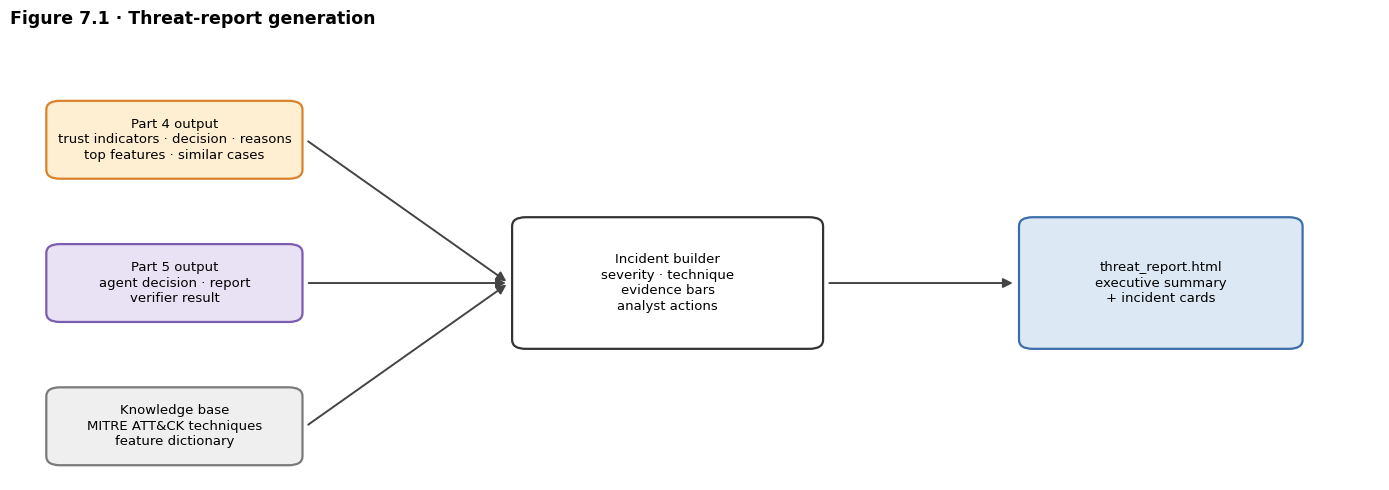

In [131]:
import os, sys
from pathlib import Path
sys.path.insert(0, str(Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"))
import matplotlib.pyplot as plt
from present_lib import flowchart

nodes = {
    "p4": (12, 38, 18, 8, "Part 4 output\ntrust indicators · decision · reasons\ntop features · similar cases", "policy"),
    "p5": (12, 22, 18, 8, "Part 5 output\nagent decision · report\nverifier result", "agent"),
    "kb": (12, 6, 18, 8, "Knowledge base\nMITRE ATT&CK techniques\nfeature dictionary", "out"),
    "inc": (48, 22, 22, 14, "Incident builder\nseverity · technique\nevidence bars\nanalyst actions", "rq"),
    "html": (84, 22, 20, 14, "threat_report.html\nexecutive summary\n+ incident cards", "data"),
}
edges = [("p4", "inc"), ("p5", "inc"), ("kb", "inc"), ("inc", "html")]
flowchart(nodes, edges, size=(14, 5), title="Figure 7.1 · Threat-report generation")
plt.show()

In [132]:
%reset -f
# Part 7 · HTML threat report — self-contained: reads the outputs of Parts 4 and 5
import os, json, html, datetime as dt
import numpy as np, pandas as pd
from pathlib import Path
from IPython.display import display, HTML, Markdown
INPUT_ROOT = Path(os.environ.get("IDS_INPUT_ROOT", "/kaggle/input"))
WORK_ROOT  = Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working"))
OUT7 = WORK_ROOT / "threat_report"; OUT7.mkdir(parents=True, exist_ok=True)
MAX_INCIDENTS = 12

def find_file(name):
    for root in (WORK_ROOT, INPUT_ROOT):
        hits = sorted(root.rglob(name)) if root.exists() else []
        if hits: return hits[0]
    raise FileNotFoundError(f"{name} not found: run Parts 4–5 first, or attach their saved outputs")

SAMPLE = pd.read_parquet(find_file("evaluation_sample.parquet"))
RES5 = pd.read_parquet(find_file("system_results.parquet"))
SPEC = json.load(open(find_file("policy_spec.json")))
RUN5 = json.load(open(find_file("run_record_nb5.json")))
FDICT = pd.read_csv(find_file("agent_feature_dictionary.csv"))
CLASSES, BENIGN = SPEC["class_names"], int(SPEC["benign_id"])
DESC = {r.feature: (str(r.description), str(r.unit)) for r in FDICT.itertuples()}
E = RES5[RES5["system"].str.startswith("E")].set_index("sample_id")
keep = [c for c in ["decision", "final", "report", "n_claims", "n_unsupported", "calls", "latency_s"] if c in E.columns]
D = SAMPLE.set_index("sample_id").join(E[keep].add_prefix("agent_"), how="left")

In [133]:
from collections import Counter
import re
MITRE = {"DoS": [("T1498", "Network Denial of Service"), ("T1499", "Endpoint Denial of Service")],
         "DDoS": [("T1498", "Network Denial of Service")], "PortScan": [("T1046", "Network Service Discovery")],
         "BruteForce": [("T1110", "Brute Force"), ("T1110.001", "Password Guessing")],
         "WebAttack": [("T1190", "Exploit Public-Facing Application")], "Bot": [("T1071", "Application Layer Protocol")], "Benign": []}
ACTIONS = {  # generic first-response playbook (fixed text, not generated by the model)
    "DoS": ["Apply rate limiting / connection limits on the targeted service", "Check server resource usage and slow-connection timeouts"],
    "DDoS": ["Engage upstream filtering or DDoS protection", "Rate-limit by source and confirm service availability"],
    "PortScan": ["Identify the scanning source and block it at the perimeter", "Review which exposed services responded"],
    "BruteForce": ["Review authentication logs for the targeted FTP/SSH accounts", "Enforce lockout / MFA and block the source"],
    "WebAttack": ["Inspect web-server and WAF logs for the request payloads", "Patch or virtual-patch the targeted application"],
    "Bot": ["Isolate the host and check for command-and-control traffic", "Run endpoint malware scanning"],
    "Benign": ["Verify the flow manually: the detector says Benign but the mechanism doubts it"],
}
SEV = {"critical": ("Critical", "#B3261E"), "high": ("High", "#E8590C"), "medium": ("Medium", "#C99100"), "low": ("Low", "#2F7D32"), "info": ("Info", "#607D8B")}
OTHERS = SPEC["other_models"]

def final_label(r):
    f = r.get("agent_final", np.nan)
    return int(r.pred) if pd.isna(f) else int(f)

def severity(r):
    if r.decision == "escalate" and bool(r.get("reason_possible_evasion", False)): return "critical"
    if r.decision == "escalate" or r.get("agent_decision") == "escalate": return "high"
    if r.decision == "flag": return "medium"
    return "info" if final_label(r) == BENIGN else "low"

def suspected_family(r):
    """Attack family the other evidence points to when the verdict is Benign but the mechanism doubts it.
    One vote per dissenting classifier, one vote for the majority family of the similar training flows.
    Uses only information available in operation (never the ground truth)."""
    if final_label(r) != BENIGN or r.decision == "accept":
        return None, ""
    votes, src = Counter(), []
    dis = {m: CLASSES[int(r[f"pred_{m}"])] for m in OTHERS if int(r[f"pred_{m}"]) != BENIGN}
    for f in dis.values(): votes[f] += 1
    nn = [f.strip() for f in str(r.get("knn_families", "")).split(",") if f.strip()]
    nn_att = Counter(f for f in nn if f != CLASSES[BENIGN])
    if nn_att:
        top, k = nn_att.most_common(1)[0]
        if k >= len(nn) / 2: votes[top] += 1
    if not votes:
        return None, ""
    fam = max(votes, key=lambda f: (votes[f], f in dis.values()))      # ties: prefer a classifier's vote
    by = [m for m, f in dis.items() if f == fam]
    if by: src.append(" and ".join(by) + " classifier")
    k = sum(f == fam for f in nn)
    if k: src.append(f"{k}/{len(nn)} similar training flows")
    return fam, ", ".join(src)

def fmt3(v):
    """Three decimals, but never print a rounded 1.000 / 0.000 for values that are only close to it."""
    v = float(v)
    if 0.9995 <= v < 1: return "&gt;0.999"
    if 0 < v < 0.0005: return "&lt;0.001"
    return f"{v:.3f}"

def labels_in(text):
    return {c for c in CLASSES if re.search(rf"(?<![A-Za-z]){re.escape(c)}(?![A-Za-z])", str(text), re.I)}

def meter(label, value, good_high=True):
    v = float(np.clip(value, 0, 1)); col = "#2F7D32" if (v >= 0.66 if good_high else v < 0.34) else ("#C99100" if 0.34 <= v < 0.66 else "#B3261E")
    return (f'<div class="tr-m"><span>{html.escape(label)}</span><div class="tr-bar"><div style="width:{v * 100:.0f}%;background:{col}"></div></div>'
            f'<b>{fmt3(value)}</b></div>')

def card(i, r):
    sev = severity(r); sname, scol = SEV[sev]
    final = final_label(r); fam = CLASSES[final]
    sus, sus_src = suspected_family(r)
    ad = r.get("agent_decision", np.nan)
    status = {"accept": "Accepted automatically", "flag": "Flagged → agents", "escalate": "Escalated → analyst"}[r.decision] + \
             (f" · agents: {ad}" if isinstance(ad, str) and r.decision != "accept" else "")
    label_html = (f'<span class="tr-label">Detector: {html.escape(fam)}</span><span class="tr-sus">suspected: {html.escape(sus)}</span>'
                  if sus else f'<span class="tr-label">{html.escape(fam)}</span>')
    reasons = [t for c, t in [("reason_low_confidence", "low classifier confidence"),
                              ("reason_possible_evasion", "classifier says Benign, anomaly detector disagrees (possible evasion)"),
                              ("reason_unsupported_alarm", "alarm not supported by the anomaly detector"),
                              ("reason_unstable_explanation", "explanation unlike the typical explanation of this family")] if bool(r.get(c, False))]
    votes = "".join(f"<tr><td>{m}</td><td>{CLASSES[int(r[f'pred_{m}'] if m != SPEC['policy_detector'] else r.pred)]}</td>"
                    f"<td>{fmt3(r.conf if m == SPEC['policy_detector'] else r[f'conf_{m}'])}</td></tr>" for m in [SPEC["policy_detector"]] + OTHERS)
    feats = "".join(f"<li><code>{html.escape(str(r[f'top_feature_{k}']))}</code> — {html.escape(DESC.get(str(r[f'top_feature_{k}']).replace('__missing', ''), ('', ''))[0])}"
                    f" <i>({'supports' if r[f'top_feature_{k}_supports'] else 'opposes'} the verdict)</i></li>" for k in (1, 2, 3))
    if sus:
        tech = (f'<span class="tr-muted" style="font-size:12px">if the suspected family is confirmed:</span> '
                + "".join(f'<span class="tr-chip">{t} · {html.escape(n)}</span>' for t, n in MITRE.get(sus, [])))
        sus_html = f"<h4>Suspected family</h4><p><b>{html.escape(sus)}</b> <span class='tr-muted'>(evidence: {html.escape(sus_src)})</span></p>"
    else:
        tech = "".join(f'<span class="tr-chip">{t} · {html.escape(n)}</span>' for t, n in MITRE.get(fam, [])) or \
               '<span class="tr-chip tr-grey">no ATT&amp;CK technique (benign verdict)</span>'
        sus_html = ""
    rep = r.get("agent_report", None)
    narrative = (f"<p>{html.escape(str(rep))}</p>" if isinstance(rep, str) and rep.strip() else
                 "<p class='tr-muted'>Accepted by the mechanism without agent review.</p>")
    named = labels_in(rep) - {fam} if isinstance(rep, str) else set()
    if named and r.get("agent_decision") == "escalate":
        narrative += (f'<span class="tr-chip tr-grey">narrative names {html.escape(", ".join(sorted(named)))}; the label stays '
                      f'{html.escape(fam)} because escalated flows keep the detector\'s label until an analyst decides</span>')
    nc, nu = r.get("agent_n_claims", np.nan), r.get("agent_n_unsupported", np.nan)
    verify = ("" if pd.isna(nc) else
              f'<span class="tr-chip {"tr-ok" if nu == 0 else "tr-bad"}" title="checks citations, decimal values and attack labels of the cited claims; '
              f'not the meaning of the free-text report">automatic checks: {int(nc) - int(nu)}/{int(nc)} cited claims pass</span>')
    truth = ("" if r.y < 0 else f'<div class="tr-foot">Evaluation only — ground truth: <b>{CLASSES[int(r.y)]}</b>; detector was '
             f'{"correct" if not r.is_error else "<b>wrong</b>"}; final label {"correct" if final == r.y else "<b>wrong</b>"}'
             + (f'; suspected family {"correct" if CLASSES[int(r.y)] == sus else "<b>wrong</b>"}' if sus else "") + ".</div>")
    acts = "".join(f"<li>{html.escape(a)}</li>" for a in (ACTIONS.get(sus, []) + ACTIONS["Benign"] if sus else ACTIONS.get(fam, [])))
    return f"""<div class="tr-card" style="border-left:6px solid {scol}">
  <div class="tr-head"><span class="tr-sev" style="background:{scol}">{sname}</span>
    <span class="tr-id">INC-{i:03d}</span>{label_html}<span class="tr-status">{status}</span></div>
  <div>{tech}</div>
  <div class="tr-grid">
    <div><h4>Why the mechanism raised it</h4><ul>{"".join(f"<li>{html.escape(x)}</li>" for x in reasons) or "<li>all checks passed</li>"}</ul>
      {sus_html}
      <h4>Indicators</h4>{meter("classifier confidence", r.conf)}{meter("anomaly strength (1 − p)", 1 - r.anomaly_p, good_high=False)}
      {meter("explanation robustness", r.stability)}
      <h4>Classifier votes</h4><table class="tr-t"><tr><th>model</th><th>verdict</th><th>conf.</th></tr>{votes}</table></div>
    <div><h4>Most influential features (SHAP)</h4><ul>{feats}</ul>
      <h4>Similar training flows</h4><p>{html.escape(str(r.knn_families))} <span class="tr-muted">(agreement {r.knn_agree:.0%})</span></p>
      <h4>Agent analysis</h4>{narrative}{verify}
      <h4>Suggested first response</h4><ul>{acts}</ul></div>
  </div>{truth}
</div>"""

CSS = """<style>
.tr-wrap{font-family:Segoe UI,Helvetica,Arial,sans-serif;color:#1d2433;background:#f4f6fa;padding:18px;border-radius:10px;max-width:1150px}
.tr-wrap h1{margin:0 0 4px 0;font-size:24px}.tr-wrap h2{font-size:18px;margin:22px 0 8px}.tr-wrap h4{font-size:13px;margin:10px 0 4px;color:#3a4a66}
.tr-sub{color:#5b6b85;font-size:13px}.tr-kpis{display:flex;gap:10px;flex-wrap:wrap;margin:12px 0}
.tr-kpi{background:white;border-radius:8px;padding:10px 14px;min-width:120px;box-shadow:0 1px 3px rgba(0,0,0,.08)}
.tr-kpi b{display:block;font-size:22px}.tr-kpi span{font-size:12px;color:#5b6b85}
.tr-card{background:white;border-radius:8px;padding:12px 16px;margin:12px 0;box-shadow:0 1px 3px rgba(0,0,0,.08)}
.tr-head{display:flex;align-items:center;gap:10px;flex-wrap:wrap;margin-bottom:6px}.tr-sev{color:white;font-weight:700;border-radius:4px;padding:2px 8px;font-size:12px}
.tr-id{font-family:monospace;color:#5b6b85}.tr-label{font-weight:700;font-size:16px}.tr-status{margin-left:auto;font-size:12px;color:#3a4a66}
.tr-chip{display:inline-block;background:#e8eefc;color:#25408f;border-radius:12px;padding:2px 9px;margin:2px 4px 2px 0;font-size:12px}
.tr-grey{background:#eceff1;color:#555}.tr-ok{background:#e3f4e4;color:#1e6b25}.tr-bad{background:#fde3e1;color:#9b1c14}
.tr-grid{display:flex;gap:22px;flex-wrap:wrap}.tr-grid>div{flex:1 1 380px;min-width:300px}.tr-grid ul{margin:2px 0 4px 18px;padding:0;font-size:13px}.tr-grid p{font-size:13px;margin:2px 0}
.tr-m{display:flex;align-items:center;gap:8px;font-size:12px;margin:4px 0}.tr-m span{width:170px;flex:none}.tr-m b{width:52px;flex:none;text-align:right}
.tr-bar{flex:1;background:#e6e9ef;height:9px;border-radius:5px;overflow:hidden}.tr-bar div{height:9px}
.tr-t{border-collapse:collapse;font-size:12px}.tr-t td,.tr-t th{border-bottom:1px solid #e6e9ef;padding:2px 10px 2px 0;text-align:left}
.tr-muted{color:#7a879c}.tr-foot{margin-top:8px;font-size:12px;color:#5b6b85;border-top:1px dashed #d5dbe5;padding-top:6px}
.tr-dist{display:flex;height:22px;border-radius:5px;overflow:hidden;margin:6px 0}.tr-dist div{color:white;font-size:11px;text-align:center;line-height:22px}
</style>"""

## 7.1 · Executive summary
The notebook shows the summary only; every incident has its own report (7.2) and can be generated on demand (7.3).

In [134]:
w = D["weight"].to_numpy(); dec = D["decision"]
share = {d: float(w[(dec == d).to_numpy()].sum() / w.sum()) for d in ["accept", "flag", "escalate"]}
D["severity"] = [severity(r) for _, r in D.iterrows()]
order = {"critical": 0, "high": 1, "medium": 2, "low": 3, "info": 4}
# ---- one incident number per flow, shared by the summary, the separate reports (7.2) and the live generator (7.3)
_reg = D.assign(_o=D["severity"].map(order)).sort_values(["_o", "anomaly_p", "stability"], kind="stable")
INC_NO = {sid: k + 1 for k, sid in enumerate(_reg.index)}

# ---- choose the incident cards: by severity, varied by family, without near-duplicates (never uses the ground truth)
QUOTA = {"critical": 5, "high": 4, "medium": 3}                 # cards per severity before the remaining slots are filled
def _theme(r):
    s, _ = suspected_family(r)
    return s or CLASSES[final_label(r)]
def _signature(r):                                               # flows that would produce the same card
    return (int(r.pred), tuple(int(r[f"pred_{m}"]) for m in OTHERS), str(r.top_feature_1), str(r.top_feature_2),
            str(r.top_feature_3), str(r.knn_families), r.decision)
pool = D[D["decision"] != "accept"].copy()
pool["_o"] = pool["severity"].map(order); pool["_theme"] = [_theme(r) for _, r in pool.iterrows()]
pool["_sig"] = [_signature(r) for _, r in pool.iterrows()]
pool = pool.sort_values(["_o", "anomaly_p", "stability"])       # most severe, most anomalous, least robust explanation first
n_dupes = int(pool["_sig"].duplicated().sum()); pool = pool[~pool["_sig"].duplicated()]

def round_robin(df, n):
    groups = [g.index.tolist() for _, g in df.groupby("_theme", sort=False)]
    out, k = [], 0
    while len(out) < n and any(k < len(g) for g in groups):
        out += [g[k] for g in groups if k < len(g)][: n - len(out)]; k += 1
    return out
picked = []
for sev, q in QUOTA.items():
    picked += round_robin(pool[pool["severity"] == sev], q)
rest = [i for i in pool.index if i not in picked]
picked += rest[: max(0, MAX_INCIDENTS - len(picked))]
inc = pool.loc[picked].sort_values(["_o", "anomaly_p", "stability"])

# ---- two accepted flows for contrast: what the mechanism lets through without review
acc = D[D["decision"] == "accept"].sort_values("conf", ascending=False)
contrast = pd.concat([acc[acc["pred"] != BENIGN].head(1), acc[acc["pred"] == BENIGN].head(1)])

final = np.where(D["agent_final"].notna(), D["agent_final"].fillna(-1).astype(int), D["pred"]) if "agent_final" in D else D["pred"].to_numpy()
fam_counts = pd.Series([CLASSES[int(f)] for f in final]).value_counts()
techs = sorted({f"{t} {n}" for f in fam_counts.index for t, n in MITRE.get(f, [])})
claims = D["agent_n_claims"].sum() if "agent_n_claims" in D else 0; unsup = D["agent_n_unsupported"].sum() if "agent_n_unsupported" in D else 0
sev_counts = D.loc[D["decision"] != "accept", "severity"].value_counts()
susp = pd.Series([suspected_family(r)[0] for _, r in D.iterrows()]).dropna().value_counts()
p_floor = float(D["anomaly_p"].min()); n_floor = int((D.loc[D["severity"] == "critical", "anomaly_p"] <= p_floor * 1.5).sum())
try:
    _V = pd.read_csv(find_file("verifier_stress_test.csv"))
    vtxt = (f" In a stress test with injected errors (Section 5.18) the checks caught {_V[_V.expected == 'should be caught'].caught.mean():.0%} of invented "
            f"sources, decimal values and attack labels, but only {_V[_V.expected == 'known blind spot'].caught.mean():.0%} of semantic errors.")
except FileNotFoundError:
    vtxt = ""

dist = "".join(f'<div style="width:{share[d] * 100:.1f}%;background:{c}">{lab} {share[d]:.0%}</div>'
               for d, lab, c in [("accept", "accepted", "#2F7D32"), ("flag", "flagged", "#C99100"), ("escalate", "escalated", "#B3261E")] if share[d] > 0)
kpi = lambda v, l: f'<div class="tr-kpi"><b>{v}</b><span>{l}</span></div>'
page = f"""<div class="tr-wrap">
<h1>🛡️ Cyber Threat Analysis Report</h1>
<div class="tr-sub">Confidence-aware IDS · detector {SPEC['policy_detector'].upper()} + {SPEC['anomaly_detector']} · explanation robustness ({SPEC['stability_variant']}) ·
agents {html.escape(str(RUN5.get('model')))} · generated {dt.datetime.now(dt.timezone.utc).strftime('%Y-%m-%d %H:%M UTC')}</div>
<h2>Executive summary</h2>
<div class="tr-kpis">{kpi(len(D), "flows analysed")}{kpi(int(sev_counts.get('critical', 0)), "critical: possible evasions")}
{kpi(int(sev_counts.get('high', 0)), "high: escalated")}{kpi(int(sev_counts.get('medium', 0)), "medium: flagged")}
{kpi(f"{share['accept']:.0%}", "accepted automatically (weighted)")}{kpi(f"{(1 - unsup / claims) if claims else float('nan'):.0%}", "cited agent claims passing automatic checks")}</div>
<div class="tr-dist">{dist}</div>
<p style="font-size:13px"><b>Activity observed (final labels):</b> {", ".join(f"{k} ({v})" for k, v in fam_counts.items())}<br>
<b>Suspected behind a doubted Benign verdict:</b> {", ".join(f"{k} ({v})" for k, v in susp.items()) or "none"}<br>
<b>MITRE ATT&amp;CK techniques:</b> {", ".join(techs) or "none"}</p>
<h2>Incidents requiring attention ({len(inc)} shown of {int((D["decision"] != "accept").sum())} not accepted)</h2>
<p style="font-size:12px" class="tr-muted">Cards are chosen by severity and spread across suspected families; {n_dupes} near-identical flows were folded into the cards shown.</p>
{"".join(card(INC_NO[sid], r) for sid, r in inc.iterrows())}
<h2>For contrast: flows accepted automatically</h2>
{"".join(card(INC_NO[sid], r) for sid, r in contrast.iterrows())}
<h2>About this report</h2>
<p style="font-size:12px" class="tr-muted"><b>Sample.</b> The {len(D)} flows are the stratified evaluation sample of Part 5: about half were not accepted by the mechanism,
and many are adversarially perturbed versions of test flows. Critical incidents are therefore far more frequent here than on normal traffic,
where most flows are accepted automatically (Part 4). Percentages marked "weighted" are re-weighted to the test-set proportions.<br>
<b>Severity.</b> <b>Critical</b> = the classifier says Benign but the anomaly detector strongly disagrees (possible evasion); <b>High</b> = escalated; <b>Medium</b> = flagged and reviewed by agents.
Escalated flows keep the detector's label until an analyst decides; the <i>suspected family</i> is the attack family named by the dissenting classifiers and the most similar training flows.<br>
<b>Reading the indicators.</b> Values are shown as &gt;0.999 rather than rounded to 1.000. Anomaly p-values cannot fall below the resolution of the benign calibration set:
the smallest p-value in this sample is {p_floor:.4f}, and {n_floor} critical flows sit at or near it, so cards are ordered by explanation robustness next.<br>
<b>Agent text.</b> Narratives were produced by {html.escape(str(RUN5.get('model')))} from the listed evidence only. The automatic checks cover the citations, decimal values and
attack labels of the agent's cited claims, not the meaning of the free-text report.{vtxt} Response suggestions are a fixed generic playbook.<br>
Ground truth is shown only for evaluation and would not be available in operation; it is never used to select or order the cards.</p>
</div>"""
CSS = CSS.replace("</style>", ".tr-sus{font-weight:700;font-size:13px;color:#B3261E;background:#fde3e1;border-radius:4px;padding:2px 8px}\n</style>") \
    if ".tr-sus" not in CSS else CSS
(OUT7 / "threat_report.html").write_text("<!doctype html><html><head><meta charset='utf-8'><title>Cyber Threat Analysis Report</title></head><body>"
                                         + CSS + page + "</body></html>", encoding="utf-8")
SUMMARY = page.split("<h2>Incidents requiring attention")[0] + "</div>"   # the notebook shows the summary; each report is separate (7.2, 7.3)
display(HTML(CSS + SUMMARY))
display(Markdown(f"**Saved:** `{OUT7 / 'threat_report.html'}` (printable full report: summary + {len(inc)} selected incident cards + {len(contrast)} contrast cards). "
                 f"Every one of the {len(D)} flows also gets its own report below (7.2), and any report can be generated on demand (7.3)."))


**Saved:** `/kaggle/working/threat_report/threat_report.html` (printable full report: summary + 12 selected incident cards + 2 contrast cards). Every one of the 200 flows also gets its own report below (7.2), and any report can be generated on demand (7.3).

## 7.2 · One separate report per flow, and a searchable explorer
Every flow of the evaluation sample gets **its own report** (`incidents/INC-001.html`, `INC-002.html`, …), numbered from most to least severe (critical → info; within a severity: most anomalous and least robust explanation first). The explorer below collects them in one page: **type an incident number (`7`, `INC-007`), a sample ID (`s120`) or keywords (`critical`, `DoS`, `escalated`, `T1498`)**, press Enter, and only that report is shown. *Previous / Next* step through the current list; *Print* and *Download* act on the open report only. `incident_explorer.html` also works when opened directly in a browser.
*Run the cells of Part 7 to build it; GitHub cannot display interactive pages, so this cell's output appears after running.*

In [ ]:
# 7.2a · Template of the incident explorer (one self-contained HTML page: search box, incident list, one report at a time)
import json

APP_CSS = r"""
:root{--bg:#EEF2F7;--panel:#FFFFFF;--ink:#16233A;--muted:#5A6A84;--line:#D6DDE8;--accent:#2C5F9E;--accent-ink:#FFFFFF;
--paper:#FFFFFF;--paper-ink:#1D2433;--paper-muted:#5B6B85;--paper-line:#E6E9EF;--chip:#E8EEFC;--chip-ink:#25408F;--track:#E6E9EF;
color-scheme:light;box-sizing:border-box;padding-top:env(safe-area-inset-top,0px);padding-bottom:env(safe-area-inset-bottom,0px)}
@media (prefers-color-scheme:dark){:root:not([data-theme="light"]){--bg:#0F1726;--panel:#172238;--ink:#E4EAF4;--muted:#9AA8BF;--line:#2A3955;--accent:#7FA9E6;--accent-ink:#0F1726;
--paper:#1B2740;--paper-ink:#E4EAF4;--paper-muted:#A3B1C8;--paper-line:#2E3D5C;--chip:#22345A;--chip-ink:#C9D8FA;--track:#2E3D5C;color-scheme:dark}}
:root[data-theme="dark"]{--bg:#0F1726;--panel:#172238;--ink:#E4EAF4;--muted:#9AA8BF;--line:#2A3955;--accent:#7FA9E6;--accent-ink:#0F1726;
--paper:#1B2740;--paper-ink:#E4EAF4;--paper-muted:#A3B1C8;--paper-line:#2E3D5C;--chip:#22345A;--chip-ink:#C9D8FA;--track:#2E3D5C;color-scheme:dark}
*,*::before,*::after{box-sizing:inherit}
html{scroll-padding-top:env(safe-area-inset-top,0px)}
body{margin:0;background:var(--bg);color:var(--ink);font:15px/1.5 "IBM Plex Sans",-apple-system,"Segoe UI",Helvetica,Arial,sans-serif;font-variant-numeric:tabular-nums}
.app{max-width:1320px;margin:0 auto;padding:20px 20px 40px}
.top{display:flex;align-items:baseline;gap:16px;flex-wrap:wrap;margin-bottom:14px}
.top h1{font-size:22px;font-weight:600;margin:0;letter-spacing:-.01em}
.top .meta{color:var(--muted);font-size:13px}
.tabs{margin-left:auto;display:flex;gap:4px}
.tabs button{font:inherit;font-size:14px;border:1px solid var(--line);background:var(--panel);color:var(--ink);padding:6px 14px;border-radius:6px;cursor:pointer}
.tabs button[aria-selected="true"]{background:var(--accent);color:var(--accent-ink);border-color:var(--accent)}
.search{display:flex;align-items:center;gap:12px;background:var(--panel);border:2px solid var(--accent);border-radius:10px;padding:10px 14px;margin-bottom:16px}
.search label{font-weight:600;white-space:nowrap}
.search input{flex:1;min-width:0;font:inherit;font-size:20px;border:0;outline:0;background:transparent;color:var(--ink);padding:4px 0}
.search input::placeholder{color:var(--muted);font-size:16px}
.search .count{color:var(--muted);font-size:13px;white-space:nowrap}
.layout{display:grid;grid-template-columns:330px 1fr;gap:16px;align-items:start}
.list{background:var(--panel);border:1px solid var(--line);border-radius:10px;max-height:calc(100vh - 210px);overflow:auto;position:sticky;top:12px}
.filters{display:flex;flex-wrap:wrap;gap:6px;padding:10px;border-bottom:1px solid var(--line)}
.filters button{font:inherit;font-size:12px;border:1px solid var(--line);background:transparent;color:var(--ink);border-radius:14px;padding:2px 10px;cursor:pointer}
.filters button[aria-pressed="true"]{background:var(--ink);color:var(--bg);border-color:var(--ink)}
.item{display:grid;grid-template-columns:6px 1fr;gap:10px;width:100%;text-align:left;font:inherit;color:inherit;background:transparent;border:0;border-bottom:1px solid var(--line);padding:9px 12px 9px 0;cursor:pointer}
.item:hover{background:var(--bg)}
.item[aria-current="true"]{background:var(--chip)}
.item .stripe{border-radius:0 3px 3px 0}
.item .l1{display:flex;gap:8px;align-items:baseline}
.item .id{font-weight:600}
.item .sev{font-size:12px;color:var(--muted)}
.item .l2{font-size:13px;color:var(--muted)}
.empty{padding:18px;color:var(--muted);font-size:14px}
.view{min-width:0}
.bar{display:flex;gap:8px;align-items:center;flex-wrap:wrap;margin-bottom:10px}
.bar button{font:inherit;font-size:14px;border:1px solid var(--line);background:var(--panel);color:var(--ink);border-radius:6px;padding:6px 12px;cursor:pointer}
.bar button:disabled{opacity:.45;cursor:default}
.bar .pos{color:var(--muted);font-size:13px;margin-left:auto}
button:focus-visible{outline:3px solid var(--accent);outline-offset:2px}
.search input:focus-visible{outline:none}
.search:focus-within{box-shadow:0 0 0 3px var(--chip)}
.hint{background:var(--panel);border:1px dashed var(--line);border-radius:10px;padding:18px;color:var(--muted)}
.hint code{background:var(--chip);color:var(--chip-ink);border-radius:4px;padding:1px 6px}
/* report paper: the card styles of the notebook, mapped to the theme */
.tr-card{background:var(--paper)!important;color:var(--paper-ink);box-shadow:none!important;border:1px solid var(--paper-line);margin:0!important}
.tr-card h4{color:var(--paper-muted)!important}
.tr-wrap{background:transparent!important;color:var(--paper-ink)!important;padding:0!important;max-width:none!important}
.tr-id{color:var(--paper-muted)!important;font-size:15px}
.tr-status{color:var(--paper-muted)!important}
.tr-chip{background:var(--chip)!important;color:var(--chip-ink)!important}
.tr-bar{background:var(--track)!important}
.tr-t td,.tr-t th{border-bottom-color:var(--paper-line)!important}
.tr-muted,.tr-foot,.tr-sub{color:var(--paper-muted)!important}
.tr-foot{border-top-color:var(--paper-line)!important}
.tr-kpi{background:var(--paper)!important;box-shadow:none!important;border:1px solid var(--paper-line)}
.tr-kpi span{color:var(--paper-muted)!important}
.overview{background:var(--panel);border:1px solid var(--line);border-radius:10px;padding:18px}
@media (max-width:860px){.search label{position:absolute;width:1px;height:1px;overflow:hidden;clip:rect(0 0 0 0)}.layout{grid-template-columns:1fr}.list{position:static;max-height:300px}.search input{font-size:17px}}
@media print{body{background:#fff;color:#000}.top,.search,.list,.bar,.tabs{display:none!important}.layout{display:block}
.tr-card{border:0!important}.app{padding:0}}
@media (prefers-reduced-motion:reduce){*{transition:none!important}}
"""

APP_JS = r"""
const DATA = __DATA__;
DATA.forEach(r=>{ r.words = r.search.toLowerCase().split(/[^a-z0-9.]+/).filter(Boolean); });
const SEV_ORDER = ["Critical","High","Medium","Low","Info"];
const $ = s => document.querySelector(s);
let filtered = DATA.slice(), current = null, sevFilter = null;
const q = $("#q"), list = $("#list"), view = $("#view"), count = $("#count");

function norm(s){return (s||"").toLowerCase();}
function resolve(text){
  const t = norm(text).trim();
  if(!t) return {exact:null, rows:DATA.filter(r=>!sevFilter||r.sev===sevFilter)};
  let m = t.match(/^(?:inc[-\s#]*|#)?0*(\d+)$/);
  if(m){const n=+m[1]; const hit=DATA.find(r=>r.inc===n); return {exact:hit||null, rows:hit?[hit]:[]};}
  m = t.match(/^(?:s|sample)[-\s#:]*(\d+)$/);
  if(m){const hit=DATA.find(r=>String(r.sid)===m[1]); return {exact:hit||null, rows:hit?[hit]:[]};}
  const words = t.split(/\s+/);
  const rows = DATA.filter(r=>(!sevFilter||r.sev===sevFilter) && words.every(w=>r.words.some(x=>x.startsWith(w))));
  return {exact:null, rows};
}
function renderList(){
  count.textContent = filtered.length === DATA.length ? `${DATA.length} reports` : `${filtered.length} of ${DATA.length} reports`;
  if(!filtered.length){list.innerHTML = `<div class="empty">No report matches “${escapeHtml(q.value)}”. Try an incident number such as 3, a sample ID such as s120, or a word such as critical, DoS or escalated.</div>`; return;}
  list.innerHTML = filtered.map(r=>`<button class="item" data-inc="${r.inc}" ${current&&current.inc===r.inc?'aria-current="true"':''}>
     <span class="stripe" style="background:${r.color}"></span>
     <span><span class="l1"><span class="id">INC-${String(r.inc).padStart(3,"0")}</span><span class="sev">${r.sev}</span></span>
     <span class="l2">${escapeHtml(r.title)} · ${escapeHtml(r.status)}</span></span></button>`).join("");
}
function escapeHtml(s){return String(s).replace(/[&<>"']/g,c=>({"&":"&amp;","<":"&lt;",">":"&gt;",'"':"&quot;","'":"&#39;"}[c]));}
function open(r, push){
  current = r;
  const i = filtered.indexOf(r);
  view.innerHTML = `<div class="bar">
      <button id="prev" ${i<=0?"disabled":""}>Previous</button>
      <button id="next" ${i<0||i>=filtered.length-1?"disabled":""}>Next</button>
      <button id="print">Print this report</button>
      __DOWNLOAD_BUTTON__
      <span class="pos">${r.sid!==null&&r.sid!==undefined?`sample ${escapeHtml(r.sid)} · `:""}${i>=0?`${i+1} of ${filtered.length} in this list`:""}</span></div>
    <div class="tr-wrap">${r.html}</div>`;
  $("#prev").onclick=()=>{const j=filtered.indexOf(current); if(j>0) open(filtered[j-1], true);};
  $("#next").onclick=()=>{const j=filtered.indexOf(current); if(j<filtered.length-1) open(filtered[j+1], true);};
  $("#print").onclick=()=>window.print();
  const dl = $("#download"); if(dl) dl.onclick=()=>download(r);
  if(push){ try{ history.replaceState(null,"","#INC-"+String(r.inc).padStart(3,"0")); }catch(e){} }
  renderList();
  const el = list.querySelector(`[data-inc="${r.inc}"]`); if(el) el.scrollIntoView({block:"nearest"});
}
function download(r){
  const page = "<!doctype html><html><head><meta charset='utf-8'><title>INC-"+String(r.inc).padStart(3,"0")+"</title>"+document.getElementById("cardcss").outerHTML+"</head><body><div class='tr-wrap'>"+r.html+"</div></body></html>";
  const a=document.createElement("a"); a.href=URL.createObjectURL(new Blob([page],{type:"text/html"}));
  a.download="INC-"+String(r.inc).padStart(3,"0")+".html"; a.click(); setTimeout(()=>URL.revokeObjectURL(a.href),1000);
}
function showHint(){
  view.innerHTML = `<div class="hint"><p><b>Type to find a report.</b> Each flow has its own incident report.</p>
   <p>Examples: <code>7</code> or <code>INC-007</code> (incident number) · <code>s120</code> (sample ID) · <code>critical</code> · <code>DoS escalated</code> · <code>T1498</code></p>
   <p>Press Enter to open the first match, or pick one from the list.</p></div>`;
}
function update(){
  const {exact, rows} = resolve(q.value);
  filtered = rows;
  if(exact){ open(exact, true); return; }
  renderList();
  if(current && !filtered.includes(current)) { if(filtered.length) open(filtered[0], false); else showHint(); }
}
q.addEventListener("input", update);
q.addEventListener("keydown", e=>{ if(e.key==="Enter" && filtered.length) open(filtered[0], true); });
list.addEventListener("click", e=>{ const b=e.target.closest(".item"); if(b) open(DATA.find(r=>r.inc===+b.dataset.inc), true); });
document.querySelectorAll(".filters button").forEach(b=>b.addEventListener("click",()=>{
  const v=b.dataset.sev||null; sevFilter = (sevFilter===v)?null:v;
  document.querySelectorAll(".filters button").forEach(x=>x.setAttribute("aria-pressed", String(!!sevFilter && x.dataset.sev===sevFilter)));
  update();
}));
function setTab(name){
  document.querySelectorAll(".tabs button").forEach(b=>b.setAttribute("aria-selected", String(b.dataset.tab===name)));
  $("#reports").hidden = name!=="reports"; $("#overview").hidden = name!=="overview";
}
document.querySelectorAll(".tabs button").forEach(b=>b.addEventListener("click",()=>setTab(b.dataset.tab)));
function fromHash(){
  const h = decodeURIComponent((location.hash||"").slice(1));
  if(h==="overview"){ setTab("overview"); return true; }
  const m = h.match(/^INC-0*(\d+)$/i);
  if(m){ const r=DATA.find(x=>x.inc===+m[1]); if(r){ setTab("reports"); open(r,false); return true; } }
  return false;
}
window.addEventListener("hashchange", fromHash);
renderList();
if(!fromHash()){ if(DATA.length) open(DATA[0], false); else showHint(); }
q.focus();
"""

def build_app(records, card_css, summary_html, title="Incident reports", subtitle="", allow_download=True, font_link=True):
    """records: list of dicts {inc, sid, sev, color, title, status, search, html}. Returns one self-contained HTML page."""
    sev_buttons = "".join(f'<button data-sev="{s}" aria-pressed="false">{s}</button>' for s in ["Critical", "High", "Medium", "Low", "Info"]
                          if any(r["sev"] == s for r in records))
    data = json.dumps(records, ensure_ascii=False).replace("</", "<\\/")
    js = APP_JS.replace("__DATA__", data).replace(
        "__DOWNLOAD_BUTTON__", '<button id="download">Download this report</button>' if allow_download else "")
    fonts = ('<link rel="preconnect" href="https://fonts.googleapis.com"><link rel="preconnect" href="https://fonts.gstatic.com" crossorigin>'
             '<link href="https://fonts.googleapis.com/css2?family=IBM+Plex+Sans:wght@400;600&display=swap" rel="stylesheet">') if font_link else ""
    card_css_tag = card_css.replace("<style>", '<style id="cardcss">', 1)
    return f"""<!doctype html><html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1, viewport-fit=cover">
<title>{title}</title>{fonts}{card_css_tag}<style>{APP_CSS}</style></head>
<body><div class="app">
<div class="top"><h1>{title}</h1><span class="meta">{subtitle}</span>
<div class="tabs" role="tablist"><button data-tab="reports" aria-selected="true">Reports</button><button data-tab="overview" aria-selected="false">Executive summary</button></div></div>
<section id="reports">
<div class="search"><label for="q">Find a report</label>
<input id="q" type="search" autocomplete="off" spellcheck="false" placeholder="Incident number, sample ID, family or severity, e.g. 7, s120, critical, DoS">
<span class="count" id="count"></span></div>
<div class="layout"><nav class="list" aria-label="Incident reports"><div class="filters">{sev_buttons}</div><div id="list"></div></nav>
<main class="view" id="view" aria-live="polite"></main></div>
</section>
<section id="overview" hidden><div class="overview tr-wrap">{summary_html}</div></section>
</div><script>{js}</script></body></html>"""


In [ ]:
# 7.2b · One separate report per flow: saved as its own file, and collected in a searchable explorer
INC_DIR = OUT7 / "incidents"; INC_DIR.mkdir(parents=True, exist_ok=True)
STATUS = {"accept": "Accepted automatically", "flag": "Flagged → agents", "escalate": "Escalated → analyst"}
REPORTS, SID_OF = {}, {}
for sid, r in _reg.iterrows():                                   # same numbering as the summary: most severe first
    n = INC_NO[sid]; SID_OF[n] = sid
    sname, scol = SEV[severity(r)]
    fam = CLASSES[final_label(r)]; sus, _ = suspected_family(r)
    title = f"{fam} → suspected {sus}" if sus else fam
    body = card(n, r)
    techs = " ".join(t for t, _ in MITRE.get(sus or fam, []))
    REPORTS[n] = dict(inc=n, sid=str(sid), sev=sname, color=scol, title=title, status=STATUS[r.decision],
                      search=" ".join([sname, title, STATUS[r.decision], r.decision, str(r.get("agent_decision") or ""), techs]).lower(),   # the incident's own facts only
                      html=body)
    (INC_DIR / f"INC-{n:03d}.html").write_text(
        f"<!doctype html><html><head><meta charset='utf-8'><title>INC-{n:03d} · {html.escape(title)}</title></head><body>"
        + CSS + f'<div class="tr-wrap">{body}</div></body></html>', encoding="utf-8")

SUMMARY_BODY = page.split('<div class="tr-wrap">', 1)[1].split("<h2>Incidents requiring attention")[0]
APP = build_app(list(REPORTS.values()), CSS, SUMMARY_BODY, title="Incident reports",
                subtitle=f"Confidence-aware IDS · {len(REPORTS)} flows, one report each", allow_download=True)
(OUT7 / "incident_explorer.html").write_text(APP, encoding="utf-8")
import warnings
with warnings.catch_warnings():                                  # IPython suggests IFrame; srcdoc keeps the page self-contained
    warnings.simplefilter("ignore")
    display(HTML(f'<iframe srcdoc="{html.escape(APP, quote=True)}" style="width:100%;height:900px;border:1px solid #D6DDE8;border-radius:8px"></iframe>'))
display(Markdown(f"**Saved:** `{OUT7 / 'incident_explorer.html'}` (open in any browser: type an incident number, sample ID or keyword) "
                 f"and {len(REPORTS)} separate reports in `{INC_DIR}/` (`INC-001.html` … `INC-{len(REPORTS):03d}.html`)."))


## 7.3 · Live report generator
Type an incident number, sample ID or keywords in the box and press Enter (or *Show report*): the report is **generated from the data at that moment** with the same `card()` function as above. If several reports match a keyword, the matching incident numbers are listed and the first is shown. Without the input box (for example in a saved, non-interactive notebook) use `show_incident(...)` in the next cell.

In [ ]:
# 7.3 · Live report generator: type an incident number, a sample ID or keywords, and the report is generated from the data
def find_reports(query):
    """7, 007, INC-007 or #7 = incident number; s120 or sample 120 = sample ID; otherwise words (critical, DoS, escalated, T1498)."""
    q = str(query).strip().lower()
    m = re.fullmatch(r"(?:inc[-\s#]*|#)?0*(\d+)", q)
    if m:
        return [int(m.group(1))] if int(m.group(1)) in REPORTS else []
    m = re.fullmatch(r"(?:s|sample)[-\s#:]*(\d+)", q)
    if m:
        return [k for k, v in REPORTS.items() if v["sid"] == m.group(1)]
    words = q.split()
    return [k for k, v in REPORTS.items()
            if words and all(any(t.startswith(w) for t in re.split(r"[^a-z0-9.]+", v["search"])) for w in words)]

def show_incident(query):
    hits = find_reports(query)
    if not hits:
        display(Markdown(f"No report matches `{query}`. Try an incident number (1–{len(REPORTS)}), a sample ID such as "
                         f"`s{REPORTS[1]['sid']}`, or a word such as `critical`, `DoS` or `escalated`."))
        return
    if len(hits) > 1:
        display(Markdown(f"**{len(hits)} reports match `{query}`:** "
                         + ", ".join(f"INC-{k:03d} ({REPORTS[k]['sev']}, {REPORTS[k]['title']})" for k in hits[:25])
                         + (" …" if len(hits) > 25 else "") + "  \nShowing the first; type its number to open another."))
    n = hits[0]
    display(HTML(CSS + '<div class="tr-wrap">' + card(n, D.loc[SID_OF[n]]) + "</div>"))   # generated from the data now

try:
    import ipywidgets as W
    _box = W.Text(placeholder="e.g. 7, INC-007, s120, critical, DoS", description="Find report:", continuous_update=False,
                  layout=W.Layout(width="60%"), style={"description_width": "initial"})
    _btn = W.Button(description="Show report", button_style="primary"); _out = W.Output()
    def _go(_=None):
        with _out:
            _out.clear_output(); show_incident(_box.value)
    _box.observe(_go, names="value"); _btn.on_click(_go)
    display(W.VBox([W.HBox([_box, _btn]), _out]))
except ImportError:
    print("ipywidgets is not installed: use show_incident(...) in the next cell.")


In [ ]:
# Without the input box (e.g. in a saved notebook): type the incident number, sample ID or keywords here and run the cell
show_incident("INC-001")


<a id="part7b"></a>
# Part 7b · Deployment: REST API (FastAPI) and Container

| | |
|---|---|
| **Goal** | Turn the confidence-aware mechanism of Part 4 into a service that scores new flows over HTTP, and package it so it can run outside Kaggle. |
| **Answers** | **RQ4** in deployed form: end-to-end latency and throughput of the mechanism behind an API; shows that the inline part of Figure 8.1 is implementable |
| **Inputs** | Parts 1, 2 and 4 outputs (Part 3 optional: attacked flows for the parity test) |
| **Outputs** | `nb7b_deployment/ids_service_deploy/` (service code, model bundle, tests, `Dockerfile`, `docker-compose.yml`, `README.md`) and `ids_service_deploy.zip` to download |
| **Run time** | ≈ 5 min (CPU) |

#### What is deployed, and what is not
| Component | In the service? | Why |
|---|---|---|
| Part 1 row rules, engineered features and transformation | ✔ | a client sends raw CICFlowMeter features, exactly as in the CIC-IDS2017 CSV files |
| XGBoost + Dirichlet calibration (policy detector) | ✔ | first indicator |
| Autoencoder + conformal p-value | ✔ (as a NumPy network) | second indicator; no PyTorch needed in the container |
| TreeSHAP explanation robustness | ✔ (XGBoost's built-in TreeSHAP) | third indicator; same values as the `shap` library, checked below |
| Accept / flag / escalate rule with Part 4's thresholds | ✔ | the decision |
| RF and MLP second opinions, top features, similar training cases | ✔ (optional) | the evidence the agents and the analyst use |
| LLM agents (Part 5) | ✘ | 22–64 s per flow on a GPU; they belong behind a queue that consumes the `agent_queue` route, not inline (Figure 8.1) |
| Learned combiner | ✘ | `policy_spec.json` does not store its feature scaling, and the transparent rule is the reported mechanism |

#### How correctness is checked
1. **Fidelity**: the NumPy networks and XGBoost's TreeSHAP must reproduce PyTorch and `shap` on the same inputs.
2. **Parity**: the running service must give the same class and decision as Part 4 for test flows (clean, adaptive attack, unseen families), from raw features.
3. **API tests** (`pytest`): health, model information, parity, CSV upload, malformed input, size limits, API key, metrics.

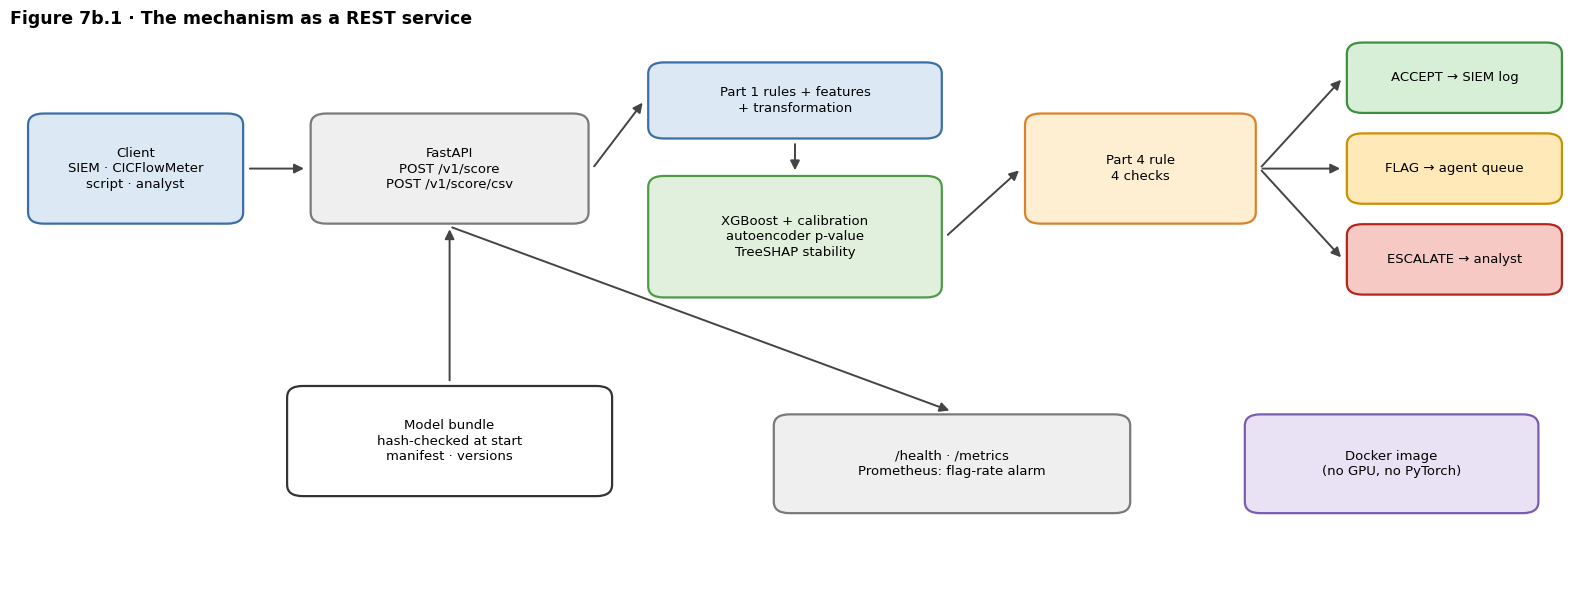

In [136]:
import os, sys
from pathlib import Path
sys.path.insert(0, str(Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"))
import matplotlib.pyplot as plt
from present_lib import flowchart

nodes = {
    "cli": (8, 38, 13, 9, "Client\nSIEM · CICFlowMeter\nscript · analyst", "data"),
    "api": (28, 38, 17, 9, "FastAPI\nPOST /v1/score\nPOST /v1/score/csv", "out"),
    "prep": (50, 44, 18, 6, "Part 1 rules + features\n+ transformation", "data"),
    "sig": (50, 32, 18, 10, "XGBoost + calibration\nautoencoder p-value\nTreeSHAP stability", "model"),
    "rule": (72, 38, 14, 9, "Part 4 rule\n4 checks", "policy"),
    "acc": (92, 46, 13, 5.5, "ACCEPT → SIEM log", "accept"),
    "flg": (92, 38, 13, 5.5, "FLAG → agent queue", "flag"),
    "esc": (92, 30, 13, 5.5, "ESCALATE → analyst", "escalate"),
    "bun": (28, 14, 20, 9, "Model bundle\nhash-checked at start\nmanifest · versions", "rq"),
    "mon": (60, 12, 22, 8, "/health · /metrics\nPrometheus: flag-rate alarm", "out"),
    "dock": (88, 12, 18, 8, "Docker image\n(no GPU, no PyTorch)", "agent"),
}
edges = [("cli", "api"), ("api", "prep"), ("prep", "sig"), ("sig", "rule"), ("rule", "acc"), ("rule", "flg"), ("rule", "esc"),
         ("bun", "api"), ("api", "mon")]
flowchart(nodes, edges, size=(16, 6.2), title="Figure 7b.1 · The mechanism as a REST service")
plt.show()

## 7b.1 · Setup and decisions

In [137]:
%reset -f
# Part 7b · Deployment — self-contained: reads the saved outputs of Parts 1, 2 and 4 (Part 3 optional)
%pip install -q fastapi "uvicorn[standard]" python-multipart httpx pytest
import os, sys, json, time, shutil, hashlib, subprocess, platform, warnings, importlib, importlib.metadata as md
from pathlib import Path
from datetime import datetime, timezone
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

INPUT_ROOT = Path(os.environ.get("IDS_INPUT_ROOT", "/kaggle/input"))
WORK_ROOT  = Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working"))
OUT = WORK_ROOT / "nb7b_deployment"; FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
BUNDLE = OUT / "ids_service_deploy"          # becomes the Docker build context
ART, SVC, TESTS = BUNDLE / "artifacts", BUNDLE / "ids_service", BUNDLE / "tests"
SEED = 42

# ---------------- Decisions ----------------
SECOND_OPINIONS  = ["rf", "mlp"]   # classifiers served as second opinions ([] = smaller image, faster requests)
PARITY_PER_GROUP = 150             # flows per group (clean / adaptive attack / unseen) in the parity test
LATENCY_REQUESTS = 200             # single-flow requests in the latency benchmark
BATCH_SIZES      = [1, 10, 100, 1000]
PORT             = 8000            # live-server demo (7b.8)

def findings(rows, meaning=""):
    text = "> #### Findings\n> | Check | Result |\n> |---|---|\n" + "".join(f"> | {a} | {b} |\n" for a, b in rows)
    if meaning: text += f">\n> **Meaning:** {meaning}\n"
    display(Markdown(text))

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=200, bbox_inches="tight"); plt.show()

def find_dir(marker, local, required=True):
    hits = sorted((WORK_ROOT / local).glob(marker)) + sorted(INPUT_ROOT.rglob(marker))  # this run first, then attached outputs
    if not hits:
        assert not required, f"{marker} not found: run the earlier Part or attach its output with 'Add Input'."
        return None
    return hits[0].parent

NB1 = find_dir("threat_model.json", "nb1_data_foundation")
NB2 = find_dir("detectors_config.json", "nb2_detectors")
NB3 = find_dir("attack_config.json", "nb3_attacks", required=False)
NB4 = find_dir("policy_spec.json", "nb4_decision_policy")
findings([("Part 1 / 2 / 4 outputs", f"{NB1} / {NB2} / {NB4}"),
          ("Part 3 output (attacked flows for the parity test)", str(NB3) if NB3 else "not found: parity on clean and unseen flows only"),
          ("Bundle folder", str(BUNDLE)), ("Python", platform.python_version())])

Note: you may need to restart the kernel to use updated packages.


> #### Findings
> | Check | Result |
> |---|---|
> | Part 1 / 2 / 4 outputs | /kaggle/working/nb1_data_foundation / /kaggle/working/nb2_detectors / /kaggle/working/nb4_decision_policy |
> | Part 3 output (attacked flows for the parity test) | /kaggle/working/nb3_attacks |
> | Bundle folder | /kaggle/working/nb7b_deployment/ids_service_deploy |
> | Python | 3.13.15 |


## 7b.2 · Model bundle
Everything the service needs is copied into one `artifacts/` folder. The two PyTorch networks are exported to plain NumPy weights, so the container needs neither PyTorch nor a GPU. The bundle is described by a `manifest.json` with the SHA-256 hash of every file and the package versions used in training; the service refuses to start if a file was changed.

| File | Content | From |
|---|---|---|
| `policy_spec.json` | thresholds τ_c, α, β, τ_s, stability measure, classes | Part 4 |
| `preprocessing_params.json`, `preprocessing_config.json`, `feature_sets.json` | training statistics, row rules, feature lists | Part 1 |
| `detectors_config.json`, `xgb.json`, `calibrator_xgb.joblib` | policy detector and its calibrator | Part 2 |
| `autoencoder.npz`, `anomaly_reference.npz` | anomaly detector (NumPy) and benign calibration scores for the p-value | Part 2 |
| `explain_reference.npz` | SHAP class prototypes and the prototype training flows for similar cases | Parts 2, 4 |
| `rf.joblib`, `mlp.npz`, `calibrator_rf/mlp.joblib` | second opinions (optional) | Part 2 |
| `feature_dictionary.csv` | readable feature descriptions | Part 1 |

In [138]:
t0 = time.time()
if BUNDLE.exists(): shutil.rmtree(BUNDLE)
for d in (ART, SVC, TESTS / "data"): d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(NB1)); sys.path.insert(0, str(NB2))
import torch, torch.nn as nn
import preprocess_lib as pl_train, models_lib as ml_train      # training versions (models_lib needs PyTorch)
SPEC = json.load(open(NB4 / "policy_spec.json")); CFG = json.load(open(NB2 / "detectors_config.json"))
POLICY, ANOMALY, COLS = SPEC["policy_detector"], SPEC["anomaly_detector"], CFG["model_cols"]
assert POLICY == "xgb", "the service explains the policy detector with XGBoost's TreeSHAP"
assert ANOMALY == "autoencoder", "the service runs the autoencoder as a NumPy network"
MD_ = NB2 / "models"
SECOND = [m for m in SECOND_OPINIONS if m in CFG["classifiers"] and m != POLICY]

# 1. files copied unchanged
COPY = {NB4 / "policy_spec.json": "policy_spec.json", NB1 / "preprocessing_params.json": "preprocessing_params.json",
        NB1 / "preprocessing_config.json": "preprocessing_config.json", NB1 / "feature_sets.json": "feature_sets.json",
        NB2 / "detectors_config.json": "detectors_config.json", NB2 / "anomaly_reference.npz": "anomaly_reference.npz",
        NB1 / "feature_dictionary.csv": "feature_dictionary.csv",
        MD_ / "xgb.json": "xgb.json", MD_ / "calibrator_xgb.joblib": "calibrator_xgb.joblib"}
for m in SECOND:
    COPY[MD_ / f"calibrator_{m}.joblib"] = f"calibrator_{m}.joblib"
    if m == "rf": COPY[MD_ / "rf.joblib"] = "rf.joblib"
for src, dst in COPY.items():
    shutil.copy2(src, ART / dst)

# 2. PyTorch networks -> NumPy operation lists (linear, relu, batchnorm in eval mode; dropout is a no-op at inference)
def export_net(modules, path):
    ops, arr = [], {}
    for i, m in enumerate(modules):
        if isinstance(m, nn.Linear):
            arr[f"w{i}"] = m.weight.detach().cpu().numpy().astype("float32"); arr[f"b{i}"] = m.bias.detach().cpu().numpy().astype("float32")
            ops.append({"type": "linear", "w": f"w{i}", "b": f"b{i}"})
        elif isinstance(m, nn.ReLU):
            ops.append({"type": "relu"})
        elif isinstance(m, nn.BatchNorm1d):
            for k, v in {"m": m.running_mean, "v": m.running_var, "g": m.weight, "h": m.bias}.items():
                arr[f"{k}{i}"] = v.detach().cpu().numpy().astype("float32")
            ops.append({"type": "batchnorm", "mean": f"m{i}", "var": f"v{i}", "w": f"g{i}", "b": f"h{i}", "eps": float(m.eps)})
        elif isinstance(m, nn.Dropout):
            continue
        else:
            raise TypeError(f"cannot export layer {type(m).__name__}")
    np.savez(path, ops=np.array(json.dumps(ops)), **arr)

ck = torch.load(MD_ / "autoencoder.pt", map_location="cpu")
AE_T = ml_train.AE(ck["d_in"]); AE_T.load_state_dict(ck["state_dict"]); AE_T.eval()
export_net(list(AE_T.encoder) + list(AE_T.decoder), ART / "autoencoder.npz")
MLP_T = None
if "mlp" in SECOND:
    ck = torch.load(MD_ / "mlp.pt", map_location="cpu")
    MLP_T = ml_train.MLP(ck["d_in"], ck["n_out"], tuple(ck["hidden"]), ck["dropout"]); MLP_T.load_state_dict(ck["state_dict"]); MLP_T.eval()
    export_net(list(MLP_T.net), ART / "mlp.npz")

# 3. explanation reference: SHAP class prototypes (Part 2) and the prototype training flows (similar cases, Part 4.14)
SH = np.load(NB2 / "shap_clean.npz", allow_pickle=True)
assert list(SH["columns"]) == COLS
CLEANP = pd.read_parquet(NB2 / "predictions_clean.parquet", columns=["row_id", "label_id", "in_proto"])
PROTO = CLEANP[CLEANP["in_proto"].astype(bool)]
MR = pd.read_parquet(NB1 / "cicids2017_model_ready.parquet", columns=COLS)
np.savez_compressed(ART / "explain_reference.npz", prototypes=SH[f"{POLICY}_prototypes"].astype("float32"),
                    knn_X=MR.iloc[PROTO["row_id"].to_numpy()].to_numpy("float32"), knn_y=PROTO["label_id"].to_numpy().astype("int16"))
del MR, CLEANP

# 4. manifest: versions and hashes
def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
TRAIN_VERSIONS = {p: md.version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "xgboost", "joblib", "torch"]}
TRAIN_VERSIONS["python"] = platform.python_version()
MANIFEST = {"bundle_version": datetime.now(timezone.utc).strftime("%Y%m%d-%H%M"),
            "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
            "policy_detector": POLICY, "anomaly_detector": ANOMALY, "second_opinions": SECOND,
            "thresholds": {k: SPEC[k] for k in ["tau_conf", "alpha", "beta", "tau_stab"]},
            "false_flag_budget": SPEC["false_flag_budget"], "source_runs": {"part1": str(NB1), "part2": str(NB2), "part4": str(NB4)},
            "training_environment": TRAIN_VERSIONS,
            "sha256": {p.name: sha256(p) for p in sorted(ART.iterdir()) if p.is_file()}}
(ART / "manifest.json").write_text(json.dumps(MANIFEST, indent=2, default=str))

BUNDLE_FILES = pd.DataFrame([(p.name, round(p.stat().st_size / 1e6, 2)) for p in sorted(ART.iterdir())], columns=["file", "size_mb"])
display(BUNDLE_FILES)
findings([("Bundle version", MANIFEST["bundle_version"]), ("Files / total size", f"{len(BUNDLE_FILES)} / {BUNDLE_FILES.size_mb.sum():.1f} MB"),
          ("Second opinions", ", ".join(SECOND) or "none"), ("Took", f"{time.time() - t0:.0f} s")])

,file,size_mb
0,anomaly_reference.npz,0.78
1,autoencoder.npz,0.06
2,calibrator_mlp.joblib,0.00
3,calibrator_rf.joblib,0.00
4,calibrator_xgb.joblib,0.00
5,detectors_config.json,0.00
6,explain_reference.npz,0.14
7,feature_dictionary.csv,0.01
8,feature_sets.json,0.01
9,manifest.json,0.00


> #### Findings
> | Check | Result |
> |---|---|
> | Bundle version | 20261025-0312 |
> | Files / total size | 16 / 18.1 MB |
> | Second opinions | rf, mlp |
> | Took | 1 s |


## 7b.3 · Service code
Three modules are written into `ids_service/` (Part 1's `preprocess_lib.py` is copied next to them unchanged):

| Module | Role |
|---|---|
| `models_lib.py` | PyTorch-free counterpart of Part 2's library: the calibrator classes under their original names (so the pickled calibrators load), conformal p-values, and the NumPy network runner |
| `engine.py` | `Mechanism`: raw flow → Part 1 rules and transformation → three trust indicators → Part 4 rule, plus the evidence (top SHAP features, second opinions, similar training cases). Malformed flows (impossible negative values, or more than half the features missing) are **escalated, never accepted** (fail closed) |
| `main.py` | FastAPI app: `/health`, `/v1/model-info`, `/v1/score`, `/v1/score/csv`, `/metrics`; optional API key (`X-API-Key`), batch and upload size limits |

In [139]:
(SVC / "__init__.py").write_text('"""Confidence-aware IDS service (Part 7b)."""\n')
shutil.copy2(NB1 / "preprocess_lib.py", SVC / "preprocess_lib.py")

(SVC / "models_lib.py").write_text(r'''"""Inference-only, PyTorch-free counterpart of Part 2's models_lib.py.

* The calibrator classes keep their original names and code, so the calibrators pickled in Part 2
  (module "models_lib") load unchanged.
* The autoencoder and MLP run as plain NumPy networks exported from their PyTorch weights in Part 7b;
  the notebook checks that both give the same outputs as PyTorch before the bundle is written.
"""
import json
import numpy as np
from scipy.special import softmax, log_softmax


# ------------------------------------------------------------------ calibration (identical to Part 2)
class TemperatureScaler:
    def predict_proba(self, logits):
        return softmax(np.asarray(logits, dtype="float64") / self.T, axis=1)


class DirichletCalibrator:
    def __init__(self, C=1.0):
        self.C = C

    def predict_proba(self, logits):
        p = np.zeros((len(logits), self.n))
        p[:, self.m.classes_] = self.m.predict_proba(log_softmax(np.asarray(logits, "float64"), axis=1))
        return p


# ------------------------------------------------------------------ conformal anomaly p-values (identical to Part 2)
def conformal_pvalues(cal_scores, scores):
    c = np.sort(np.asarray(cal_scores)); s = np.asarray(scores)
    ge = len(c) - np.searchsorted(c, s, side="left")
    return (1 + ge) / (len(c) + 1)


# ------------------------------------------------------------------ exported networks
class NumpyNet:
    """Feed-forward network stored as a list of operations: linear, relu, batchnorm (eval mode)."""

    def __init__(self, path):
        z = np.load(path, allow_pickle=False)
        self.ops = json.loads(str(z["ops"]))
        self.arr = {k: z[k] for k in z.files if k != "ops"}
        self.d_in = int(self.arr[self.ops[0]["w"]].shape[1])

    def forward(self, X):
        h = np.asarray(X, dtype="float32")
        for op in self.ops:
            t = op["type"]
            if t == "linear":
                h = h @ self.arr[op["w"]].T + self.arr[op["b"]]
            elif t == "relu":
                h = np.maximum(h, 0)
            elif t == "batchnorm":
                a = self.arr
                h = (h - a[op["mean"]]) / np.sqrt(a[op["var"]] + op["eps"]) * a[op["w"]] + a[op["b"]]
            else:
                raise ValueError(f"unknown operation {t}")
        return h.astype("float32")


def ae_score(net, X):
    """Reconstruction error of the autoencoder (same definition as Part 2)."""
    X = np.asarray(X, dtype="float32")
    return ((net.forward(X) - X) ** 2).mean(1)
''')

(SVC / "engine.py").write_text(r'''"""Confidence-aware decision mechanism for one or many network flows (inference only).

Reproduces Part 4 of the notebook for a *new* flow:
raw CICFlowMeter features -> Part 1 row rules + engineered features -> Part 1 transformation
-> calibrated XGBoost confidence + autoencoder conformal p-value + SHAP explanation robustness
-> accept / flag / escalate with the thresholds tuned in Part 4 (policy_spec.json).
"""
from __future__ import annotations

import hashlib
import json
import sys
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import xgboost as xgb
from scipy.stats import rankdata
from sklearn.neighbors import NearestNeighbors

from . import models_lib as ml
from . import preprocess_lib as pl

sys.modules.setdefault("models_lib", ml)   # the calibrators were pickled from a module named models_lib

ROUTES = {"accept": "siem_log", "flag": "agent_queue", "escalate": "analyst"}
CHECKS = ["low_confidence", "possible_evasion", "unsupported_alarm", "unstable_explanation"]
NON_FEATURE_KEYS = {"flow_id", "Label", "label", "label_family"}


def _num(v, off):
    """Threshold from policy_spec.json; a disabled check (None) gets its 'off' value."""
    return float(off) if v is None else float(v)


def _sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()


class Mechanism:
    def __init__(self, artifact_dir, verify_hashes=True):
        A = Path(artifact_dir)
        self.dir = A
        self.manifest = json.loads((A / "manifest.json").read_text())
        if verify_hashes:
            bad = [f for f, h in self.manifest["sha256"].items() if _sha256(A / f) != h]
            if bad:
                raise RuntimeError(f"artifact files changed since the bundle was built: {bad}")
        J = lambda n: json.loads((A / n).read_text())
        self.spec, self.params = J("policy_spec.json"), J("preprocessing_params.json")
        self.fsets, self.pcfg, self.dcfg = J("feature_sets.json"), J("preprocessing_config.json"), J("detectors_config.json")

        self.classes = list(self.spec["class_names"]); self.K = len(self.classes)
        self.benign = int(self.spec["benign_id"]); self.cols = list(self.dcfg["model_cols"])
        excluded = set(self.fsets.get("excluded_features", []))
        self.raw_features = [c for c in self.fsets["features_raw"] if c not in excluded]
        self.eng_features = list(self.fsets["features_engineered"])
        self.neg_drop = [c for c in self.pcfg.get("neg_drop_row_cols", []) if c in self.raw_features]
        self.neg_clip = [c for c in self.pcfg.get("neg_clip_cols", []) if c in self.raw_features]
        self.cont = np.array([(c not in set(self.params["binary_cols"])) and not c.endswith("__missing") for c in self.cols])

        s = self.spec
        self.thr = {"tau_conf": _num(s["tau_conf"], -np.inf), "alpha": _num(s["alpha"], 0.0),
                    "beta": _num(s["beta"], 1.01), "tau_stab": _num(s["tau_stab"], -np.inf)}
        self.stab_variant = s["stability_variant"]

        # classifiers: the policy detector and the second opinions
        self.policy = s["policy_detector"]
        self.models, self.calib = {}, {}
        for name in [self.policy] + list(self.manifest.get("second_opinions", [])):
            self._load_classifier(name)
        self.booster = self.models[self.policy].get_booster()

        # anomaly detector (autoencoder as a NumPy network) and its benign calibration scores
        self.ae = ml.NumpyNet(A / "autoencoder.npz")
        self.aref = np.load(A / "anomaly_reference.npz")[f"{s['anomaly_detector']}_cal_benign_scores"]

        # explanation reference: class prototypes and the similar-case index
        E = np.load(A / "explain_reference.npz")
        self.prototypes = E["prototypes"]
        self.knn_y = E["knn_y"].astype(int)
        self.knn = NearestNeighbors(n_neighbors=int(s.get("knn_k", 5))).fit(E["knn_X"])

        fd = pd.read_csv(A / "feature_dictionary.csv")
        self.describe = {r.feature: str(r.description) for r in fd.itertuples() if isinstance(r.description, str)}

    # ------------------------------------------------------------------ models
    def _load_classifier(self, name):
        A = self.dir
        if name == "xgb":
            m = xgb.XGBClassifier(); m.load_model(A / "xgb.json")
            try: m.set_params(device="cpu", n_jobs=1)
            except Exception: pass
        elif name == "rf":
            m = joblib.load(A / "rf.joblib")
            try: m.set_params(n_jobs=1)
            except Exception: pass
        elif name == "mlp":
            m = ml.NumpyNet(A / "mlp.npz")
        else:
            raise ValueError(f"unknown classifier {name}")
        self.models[name] = m
        self.calib[name] = joblib.load(A / f"calibrator_{name}.joblib")

    def proba(self, name, X):
        m = self.models[name]
        Z = m.forward(X) if name == "mlp" else np.log(np.clip(m.predict_proba(X), 1e-12, 1))
        P = self.calib[name].predict_proba(Z)
        return P / P.sum(1, keepdims=True)

    def shap_for_class(self, X, cls):
        """Exact TreeSHAP of the policy detector (XGBoost's own implementation) for one class per flow."""
        d = xgb.DMatrix(np.asarray(X, dtype="float32"), feature_names=self.booster.feature_names)
        c = self.booster.predict(d, pred_contribs=True)
        c = c.reshape(len(X), self.K, -1) if c.ndim == 2 else c          # (flows, classes, features + bias)
        return c[np.arange(len(X)), cls, :-1].astype("float32")

    # ------------------------------------------------------------------ input
    def prepare(self, frame):
        """Raw flow features -> model input, with Part 1's row rules. Returns X and per-flow notes."""
        df = frame.copy()
        df.columns = [str(c).strip() for c in df.columns]
        df = df.loc[:, ~df.columns.duplicated()]
        n = len(df)
        given = set(df.columns)
        missing_raw = [c for c in self.raw_features if c not in given]
        for c in set(self.raw_features + self.eng_features) - given:
            df[c] = np.nan
        for c in self.raw_features + [e for e in self.eng_features if e in given]:
            df[c] = pd.to_numeric(df[c], errors="coerce").astype("float64")
        raw = df[self.raw_features].replace([np.inf, -np.inf], np.nan)
        df[self.raw_features] = raw

        nan_share = raw.isna().mean(axis=1).to_numpy()
        invalid = np.zeros(n, dtype=bool)
        for c in self.neg_drop:
            invalid |= (df[c] < 0).to_numpy()
        for c in self.neg_clip:
            df[c] = df[c].clip(lower=0)

        eng = pl.engineer_features(df[self.raw_features])                # only for engineered features not sent
        for c in self.eng_features:
            if c not in given and c in eng.columns:
                df[c] = eng[c].to_numpy()
        X = pl.apply_preprocessing(df, self.params)[self.cols].to_numpy("float32")
        return X, {"missing_raw": missing_raw, "nan_share": nan_share, "invalid": invalid}

    # ------------------------------------------------------------------ decision
    def decide(self, conf, pred, pv, stab):
        t = self.thr
        reasons = {"low_confidence": conf < t["tau_conf"],
                   "possible_evasion": (pred == self.benign) & (pv < t["alpha"]),
                   "unsupported_alarm": (pred != self.benign) & (pv > t["beta"]),
                   "unstable_explanation": stab < t["tau_stab"]}
        nfail = sum(v.astype(int) for v in reasons.values())
        dec = np.full(len(conf), "accept", dtype=object)
        dec[nfail == 1] = "flag"
        dec[(nfail >= 2) | reasons["possible_evasion"]] = "escalate"
        return dec, reasons

    def stability(self, X, pred, S):
        if self.stab_variant == "proto_sim":
            P = self.prototypes[pred]
            den = np.linalg.norm(S, axis=1) * np.linalg.norm(P, axis=1)
            return np.where(den > 0, (S * P).sum(1) / np.maximum(den, 1e-12), 0.0)
        # local robustness: rank correlation of |SHAP| under small input noise (Part 4, Section 4.5)
        rng = np.random.default_rng(int(self.spec.get("seed", 42)))
        A0, out = np.abs(S), np.zeros(len(X))
        for _ in range(int(self.spec["stability_repeats"])):
            Xn = X.copy()
            Xn[:, self.cont] += rng.normal(0, float(self.spec["stability_noise_sd"]), (len(X), int(self.cont.sum()))).astype("float32")
            a, b = rankdata(A0, axis=1), rankdata(np.abs(self.shap_for_class(Xn, pred)), axis=1)
            a -= a.mean(1, keepdims=True); b -= b.mean(1, keepdims=True)
            den = np.sqrt((a ** 2).sum(1) * (b ** 2).sum(1))
            out += np.where(den > 0, (a * b).sum(1) / np.maximum(den, 1e-12), 1.0)
        return out / int(self.spec["stability_repeats"])

    def score(self, frame, include_evidence=True, include_probabilities=False):
        t0 = time.perf_counter()
        ids = ([None if pd.isna(v) else str(v) for v in frame["flow_id"]] if "flow_id" in frame.columns else [None] * len(frame))
        X, note = self.prepare(frame.drop(columns=[c for c in NON_FEATURE_KEYS if c in frame.columns]))
        P = self.proba(self.policy, X)
        pred, conf = P.argmax(1), P.max(1)
        pv = ml.conformal_pvalues(self.aref, ml.ae_score(self.ae, X))
        S = self.shap_for_class(X, pred)
        stab = self.stability(X, pred, S)
        dec, reasons = self.decide(conf, pred, pv, stab)

        insufficient = note["nan_share"] > 0.5
        forced = note["invalid"] | insufficient
        dec[forced] = "escalate"                                      # fail closed: never accept a malformed flow

        second = {m: self.proba(m, X) for m in self.models if m != self.policy}
        if include_evidence:
            top = np.argsort(-np.abs(S), axis=1)[:, :3]
            dist, nb = self.knn.kneighbors(X)
            labs = self.knn_y[nb]

        out = []
        for i in range(len(X)):
            failed = [c for c in CHECKS if reasons[c][i]]
            if note["invalid"][i]: failed.append("invalid_input")
            if insufficient[i]: failed.append("insufficient_features")
            r = {"flow_id": ids[i], "decision": dec[i], "route": ROUTES[dec[i]],
                 "predicted_family": self.classes[pred[i]], "confidence": float(conf[i]),
                 "anomaly_p_value": float(pv[i]), "explanation_stability": float(stab[i]),
                 "failed_checks": failed,
                 "second_opinions": {m: {"family": self.classes[int(Q[i].argmax())], "confidence": float(Q[i].max())}
                                     for m, Q in second.items()}}
            if include_probabilities:
                r["class_probabilities"] = {c: float(P[i, k]) for k, c in enumerate(self.classes)}
            if include_evidence:
                r["top_features"] = [{"feature": self.cols[j], "shap": float(S[i, j]), "supports_prediction": bool(S[i, j] > 0),
                                      "description": self.describe.get(self.cols[j].replace("__missing", ""))} for j in top[i]]
                fam = [self.classes[k] for k in labs[i]]
                maj = max(set(fam), key=fam.count)
                r["similar_training_cases"] = {"families": fam, "majority": maj, "agreement": fam.count(maj) / len(fam),
                                               "median_distance": float(np.median(dist[i]))}
            out.append(r)
        ms = 1e3 * (time.perf_counter() - t0)
        return out, {"flows": len(X), "latency_ms": ms, "missing_features": note["missing_raw"]}

    def info(self):
        return {"bundle_version": self.manifest["bundle_version"], "created_utc": self.manifest["created_utc"],
                "policy_detector": self.policy, "anomaly_detector": self.spec["anomaly_detector"],
                "second_opinions": [m for m in self.models if m != self.policy], "classes": self.classes,
                "stability_measure": self.stab_variant, "thresholds": {k: (None if not np.isfinite(v) else v) for k, v in self.thr.items()},
                "false_flag_budget": self.spec["false_flag_budget"], "rule": self.spec["rule"],
                "expected_features": self.raw_features, "model_inputs": len(self.cols)}
''')

(SVC / "main.py").write_text(r'''"""REST API for the confidence-aware intrusion-detection mechanism.

Run:  uvicorn ids_service.main:app --host 0.0.0.0 --port 8000
Docs: http://localhost:8000/docs
"""
from __future__ import annotations

import io
import os
import secrets
import threading
from contextlib import asynccontextmanager
from pathlib import Path
from typing import Literal, Optional, Union

import pandas as pd
from fastapi import Depends, FastAPI, File, HTTPException, Query, Security, UploadFile
from fastapi.responses import PlainTextResponse, StreamingResponse
from fastapi.security import APIKeyHeader
from pydantic import BaseModel, Field

from .engine import Mechanism

ARTIFACT_DIR = Path(os.environ.get("IDS_ARTIFACT_DIR", Path(__file__).resolve().parent.parent / "artifacts"))
API_KEY = os.environ.get("IDS_API_KEY") or None          # if set, every /v1 call needs the header X-API-Key
MAX_BATCH = int(os.environ.get("IDS_MAX_BATCH", "5000"))
MAX_CSV_MB = float(os.environ.get("IDS_MAX_CSV_MB", "50"))

STATE = {"engine": None}
STATS = {"requests": 0, "flows": 0, "latency_ms_sum": 0.0,
         "decisions": {"accept": 0, "flag": 0, "escalate": 0}, "lock": threading.Lock()}


@asynccontextmanager
async def lifespan(app: FastAPI):
    STATE["engine"] = Mechanism(ARTIFACT_DIR, verify_hashes=os.environ.get("IDS_VERIFY_HASHES", "1") == "1")
    yield
    STATE["engine"] = None


app = FastAPI(title="Confidence-aware IDS",
              description="Accept / flag / escalate decisions for network flows from calibrated XGBoost confidence, "
                          "autoencoder anomaly evidence and SHAP explanation robustness (MSc project, Part 7b).",
              version="1.0.0", lifespan=lifespan)

_key_header = APIKeyHeader(name="X-API-Key", auto_error=False)


def require_key(key: Optional[str] = Security(_key_header)):
    if API_KEY and not (key and secrets.compare_digest(key, API_KEY)):
        raise HTTPException(status_code=401, detail="missing or wrong X-API-Key")


def engine() -> Mechanism:
    if STATE["engine"] is None:
        raise HTTPException(status_code=503, detail="model not loaded")
    return STATE["engine"]


# ------------------------------------------------------------------ schemas
Value = Union[float, int, str, None]


class ScoreRequest(BaseModel):
    flows: list[dict[str, Value]] = Field(..., min_length=1, description="CICFlowMeter features per flow (names as in "
                                          "CIC-IDS2017, e.g. 'Flow Duration'); an optional 'flow_id' is echoed back")
    include_evidence: bool = Field(True, description="add top SHAP features and similar training cases")
    include_probabilities: bool = Field(False, description="add calibrated probabilities of every class")


class TopFeature(BaseModel):
    feature: str
    shap: float
    supports_prediction: bool
    description: Optional[str] = None


class SimilarCases(BaseModel):
    families: list[str]
    majority: str
    agreement: float
    median_distance: float


class Opinion(BaseModel):
    family: str
    confidence: float


class FlowResult(BaseModel):
    flow_id: Optional[str] = None
    decision: Literal["accept", "flag", "escalate"]
    route: Literal["siem_log", "agent_queue", "analyst"]
    predicted_family: str
    confidence: float
    anomaly_p_value: float
    explanation_stability: float
    failed_checks: list[str]
    second_opinions: dict[str, Opinion] = {}
    class_probabilities: Optional[dict[str, float]] = None
    top_features: Optional[list[TopFeature]] = None
    similar_training_cases: Optional[SimilarCases] = None


class ScoreResponse(BaseModel):
    flows: int
    latency_ms: float
    decisions: dict[str, int]
    missing_features: list[str]
    results: list[FlowResult]


def _record(results, meta):
    with STATS["lock"]:
        STATS["requests"] += 1; STATS["flows"] += meta["flows"]; STATS["latency_ms_sum"] += meta["latency_ms"]
        for r in results:
            STATS["decisions"][r["decision"]] += 1


def _run(frame, include_evidence, include_probabilities):
    if len(frame) == 0:
        raise HTTPException(status_code=422, detail="no flows")
    if len(frame) > MAX_BATCH:
        raise HTTPException(status_code=413, detail=f"at most {MAX_BATCH} flows per request")
    results, meta = engine().score(frame, include_evidence, include_probabilities)
    _record(results, meta)
    counts = {d: sum(r["decision"] == d for r in results) for d in ("accept", "flag", "escalate")}
    return results, meta, counts


# ------------------------------------------------------------------ endpoints
@app.get("/health", tags=["service"])
def health():
    """Liveness and readiness: 200 once the models are loaded."""
    e = engine()
    return {"status": "ok", "bundle_version": e.manifest["bundle_version"]}


@app.get("/v1/model-info", tags=["service"], dependencies=[Depends(require_key)])
def model_info():
    """Model versions, classes, thresholds and the features a flow should contain."""
    return engine().info()


@app.post("/v1/score", response_model=ScoreResponse, response_model_exclude_none=True,
          tags=["detection"], dependencies=[Depends(require_key)])
def score(req: ScoreRequest):
    """Score one or more flows. Flows routed to `agent_queue` (flag) or `analyst` (escalate) need review."""
    results, meta, counts = _run(pd.DataFrame(req.flows), req.include_evidence, req.include_probabilities)
    return {"flows": meta["flows"], "latency_ms": meta["latency_ms"], "decisions": counts,
            "missing_features": meta["missing_features"], "results": results}


@app.post("/v1/score/csv", tags=["detection"], dependencies=[Depends(require_key)])
def score_csv(file: UploadFile = File(..., description="CICFlowMeter CSV export"),
              output: Literal["json", "csv"] = Query("csv", description="csv: the input rows with the decision columns added")):
    """Score a CICFlowMeter CSV file (e.g. one of the CIC-IDS2017 MachineLearningCVE files)."""
    data = file.file.read(int(MAX_CSV_MB * 1e6) + 1)
    if len(data) > MAX_CSV_MB * 1e6:
        raise HTTPException(status_code=413, detail=f"file larger than {MAX_CSV_MB} MB")
    try:
        frame = pd.read_csv(io.BytesIO(data), encoding="latin-1", low_memory=False)
    except Exception as exc:
        raise HTTPException(status_code=422, detail=f"cannot read CSV: {exc}")
    results, meta, counts = _run(frame, include_evidence=(output == "json"), include_probabilities=False)
    if output == "json":
        return {"flows": meta["flows"], "latency_ms": meta["latency_ms"], "decisions": counts,
                "missing_features": meta["missing_features"], "results": results}
    frame.columns = [str(c).strip() for c in frame.columns]
    for col in ["decision", "route", "predicted_family", "confidence", "anomaly_p_value", "explanation_stability"]:
        frame[f"ids_{col}"] = [r[col] for r in results]
    frame["ids_failed_checks"] = [";".join(r["failed_checks"]) for r in results]
    buf = io.StringIO(); frame.to_csv(buf, index=False); buf.seek(0)
    return StreamingResponse(iter([buf.getvalue()]), media_type="text/csv",
                             headers={"Content-Disposition": f'attachment; filename="scored_{file.filename or "flows.csv"}"'})


@app.get("/metrics", response_class=PlainTextResponse, tags=["service"])
def metrics():
    """Prometheus metrics. A sudden rise of the flag / escalate share is the first sign of an attack or of drift."""
    with STATS["lock"]:
        s = {k: (dict(v) if isinstance(v, dict) else v) for k, v in STATS.items() if k != "lock"}
    lines = ["# HELP ids_requests_total Scoring requests.", "# TYPE ids_requests_total counter",
             f"ids_requests_total {s['requests']}",
             "# HELP ids_flows_total Flows scored, by decision.", "# TYPE ids_flows_total counter"]
    lines += [f'ids_flows_total{{decision="{d}"}} {n}' for d, n in s["decisions"].items()]
    lines += ["# HELP ids_request_latency_ms_sum Total request latency in ms.", "# TYPE ids_request_latency_ms_sum counter",
              f"ids_request_latency_ms_sum {s['latency_ms_sum']:.3f}"]
    return "\n".join(lines) + "\n"
''')

print("service code written:", ", ".join(sorted(p.name for p in SVC.glob('*.py'))))

service code written: __init__.py, engine.py, main.py, models_lib.py, preprocess_lib.py


## 7b.4 · Fidelity and parity with Part 4
The parity sample takes test flows of three groups from Part 4's `policy_flags_test.parquet`:

* **clean**: test-lite flows without attack;
* **adaptive attack**: ZOO flows crafted against XGBoost at the largest budget (Part 3), rebuilt as the attacker sends them (the clean original with the attacker-controlled features replaced);
* **unseen**: Heartbleed and Infiltration flows, never seen in training.

Each flow is sent to the service as **raw features**, and the service's class and decision are compared with Part 4's. The flows and Part 4's answers are saved in `tests/data/`, so the same check runs again inside the container (`pytest`).

In [140]:
t0 = time.time()
sys.path.insert(0, str(BUNDLE))
for m in [k for k in sys.modules if k == "ids_service" or k.startswith("ids_service.")]: del sys.modules[m]
from ids_service.engine import Mechanism
import ids_service.models_lib as ml_srv
ENG = Mechanism(ART)
CLASSES = ENG.classes; BENIGN_ID = ENG.benign

# ---- parity sample from Part 4's decisions
fs = json.load(open(NB1 / "feature_sets.json"))
FEATS = list(dict.fromkeys(fs["features_raw"] + fs["features_engineered"]))
PF = pd.read_parquet(NB4 / "policy_flags_test.parquet")
for c in ["set", "group", "attack", "target"]: PF[c] = PF[c].astype(str)
PF["eps"] = PF["eps"].astype(float).round(6)
rs = np.random.default_rng(SEED)
def take(d, n): return d.sample(min(n, len(d)), random_state=SEED) if len(d) else d
G = {"clean": take(PF[(PF.set == "test") & (PF.group == "clean")], PARITY_PER_GROUP),
     "unseen": take(PF[PF.set == "unseen"], PARITY_PER_GROUP)}
if NB3 is not None:
    zd = PF[(PF.set == "test") & (PF.group == "zoo_direct") & (PF.y != BENIGN_ID)]
    G["adaptive attack"] = take(zd[zd.eps == zd.eps.max()], PARITY_PER_GROUP)

need = np.unique(np.concatenate([g["row_id"].to_numpy() for g in G.values()]))
CLEAN = pd.read_parquet(NB1 / "cicids2017_clean.parquet", columns=FEATS).iloc[need]
CLEAN.index = need
parts = []
for name, g in G.items():
    rows = CLEAN.loc[g["row_id"].to_numpy()].reset_index(drop=True)
    if name == "adaptive attack":                    # the attacker changes only the controllable features
        A = pd.read_parquet(NB3 / "adversarial_flows.parquet")
        A["set"] = A["set"].astype(str).map({"test_lite": "test", "thr_lite": "thr"})
        for c in ["attack", "target"]: A[c] = A[c].astype(str)
        A["eps"] = A["eps"].astype(float).round(6)
        KEY = ["set", "attack", "target", "eps", "row_id"]
        Am = g[KEY].reset_index(drop=True).merge(A, on=KEY, how="left")
        assert Am[[c for c in A.columns if c not in KEY][0]].notna().all(), "adversarial flows not found"
        for c in [c for c in FEATS if c in A.columns]: rows[c] = Am[c].to_numpy()
        del A
    rows.insert(0, "flow_id", [f"{name.split()[-1]}-{i}" for i in g["row_id"].to_numpy()])
    exp = pd.DataFrame({"flow_id": rows["flow_id"], "group": name, "family": g["family"].astype(str).to_numpy(),
                        "decision": g["decision"].astype(str).to_numpy(),
                        "predicted_family": np.array(CLASSES)[g["pred"].astype(int).to_numpy()],
                        "confidence": g["conf"].to_numpy(), "anomaly_p_value": g["anomaly_p"].to_numpy(),
                        "explanation_stability": g["stability"].to_numpy(), "is_evasion": g["is_evasion"].astype(bool).to_numpy()})
    parts.append((rows, exp))
FLOWS = pd.concat([p[0] for p in parts], ignore_index=True); EXP = pd.concat([p[1] for p in parts], ignore_index=True)
del CLEAN

# ---- the service on raw features
RES, META = ENG.score(FLOWS, include_evidence=False)
GOT = pd.DataFrame(RES)
assert (GOT["flow_id"] == EXP["flow_id"]).all()
EXP["svc_decision"], EXP["svc_family"] = GOT["decision"], GOT["predicted_family"]
for c in ["confidence", "anomaly_p_value", "explanation_stability"]: EXP[f"d_{c}"] = (GOT[c] - EXP[c]).abs()
# raw-feature path: drop the engineered features, the service recomputes them
RES_RAW, _ = ENG.score(FLOWS.drop(columns=[c for c in fs["features_engineered"] if c in FLOWS]), include_evidence=False)
EXP["svc_decision_raw"] = [r["decision"] for r in RES_RAW]

PAR = EXP.groupby("group", sort=False).apply(lambda d: pd.Series({
    "flows": len(d), "same class": (d.svc_family == d.predicted_family).mean(), "same decision": (d.svc_decision == d.decision).mean(),
    "same decision (engineered recomputed)": (d.svc_decision_raw == d.decision).mean(),
    "max |Δ confidence|": d.d_confidence.max(), "max |Δ p-value|": d.d_anomaly_p_value.max(),
    "max |Δ stability|": d.d_explanation_stability.max(),
    "not accepted by service": (d.svc_decision != "accept").mean(),
    "evasions not accepted": (d.loc[d.is_evasion, "svc_decision"] != "accept").mean() if d.is_evasion.any() else np.nan}))
display(PAR.round(4))

# ---- fidelity of the exported networks and of XGBoost's TreeSHAP
X, _ = ENG.prepare(FLOWS)
with torch.no_grad():
    rec_t = ml_train.ae_score(AE_T, X, "cpu"); rec_n = ml_srv.ae_score(ENG.ae, X)
AE_REL = float(np.max(np.abs(rec_t - rec_n) / np.maximum(np.abs(rec_t), 1e-8)))
MLP_DIFF = float(np.abs(ml_train.torch_logits(MLP_T, X, "cpu") - ENG.models["mlp"].forward(X)).max()) if MLP_T is not None else np.nan
import shap
pred = ENG.proba(POLICY, X).argmax(1)
sv = shap.TreeExplainer(ENG.models[POLICY]).shap_values(X[:300], check_additivity=False)
sv = np.stack(sv, -1) if isinstance(sv, list) else np.asarray(sv)
sv = sv if sv.shape[0] == len(X[:300]) else np.transpose(sv, (1, 2, 0))
SHAP_DIFF = float(np.abs(sv[np.arange(300), :, pred[:300]] - ENG.shap_for_class(X[:300], pred[:300])).max())

clean_ok = float(PAR.loc["clean", "same decision"])
FIDELITY_OK = AE_REL < 1e-3 and (np.isnan(MLP_DIFF) or MLP_DIFF < 1e-3) and SHAP_DIFF < 1e-3
findings([("Autoencoder: NumPy vs PyTorch, max relative difference of the anomaly score", f"{AE_REL:.1e} {'✔' if AE_REL < 1e-3 else '✘'}"),
          ("MLP: NumPy vs PyTorch, max logit difference", "not served" if np.isnan(MLP_DIFF) else f"{MLP_DIFF:.1e} {'✔' if MLP_DIFF < 1e-3 else '✘'}"),
          ("TreeSHAP: XGBoost built-in vs shap library, max difference", f"{SHAP_DIFF:.1e} {'✔' if SHAP_DIFF < 1e-3 else '✘'}")] +
         [(f"{g}: same class / same decision as Part 4", f"{r['same class']:.1%} / {r['same decision']:.1%}") for g, r in PAR.iterrows()] +
         [("Clean flows, engineered features recomputed by the service: same decision", f"{PAR.loc['clean', 'same decision (engineered recomputed)']:.1%}")] +
         ([("Adaptive-attack evasions the service does not accept", f"{PAR.loc['adaptive attack', 'evasions not accepted']:.1%}")] if "adaptive attack" in PAR.index else []) +
         [("Unseen-family flows the service does not accept", f"{PAR.loc['unseen', 'not accepted by service']:.1%}"), ("Took", f"{time.time() - t0:.0f} s")],
         "the deployed service makes the same decisions as the evaluated mechanism; rare differences come from float32 rounding at a threshold.")
assert FIDELITY_OK and clean_ok >= 0.98, "the service does not reproduce Part 4: check the bundle"

FLOWS.to_csv(TESTS / "data" / "parity_flows.csv", index=False)
EXP[["flow_id", "group", "family", "decision", "predicted_family"]].to_csv(TESTS / "data" / "parity_expected.csv", index=False)
PAR.to_csv(OUT / "parity_with_part4.csv")

,flows,same class,same decision,same decision (engineered recomputed),max |Δ confidence|,max |Δ p-value|,max |Δ stability|,not accepted by service,evasions not accepted
group,,,,,,,,,
clean,150.0,1.0,1.0,1.0000,0.0000,0.0,0.0,0.0600,1.0000
unseen,47.0,1.0,1.0,1.0000,0.0000,0.0,0.0,0.9362,NaN
adaptive attack,150.0,1.0,1.0,0.9333,0.0001,0.0,0.0,0.8200,0.9412


> #### Findings
> | Check | Result |
> |---|---|
> | Autoencoder: NumPy vs PyTorch, max relative difference of the anomaly score | 3.1e-07 ✔ |
> | MLP: NumPy vs PyTorch, max logit difference | 1.9e-06 ✔ |
> | TreeSHAP: XGBoost built-in vs shap library, max difference | 0.0e+00 ✔ |
> | clean: same class / same decision as Part 4 | 100.0% / 100.0% |
> | unseen: same class / same decision as Part 4 | 100.0% / 100.0% |
> | adaptive attack: same class / same decision as Part 4 | 100.0% / 100.0% |
> | Clean flows, engineered features recomputed by the service: same decision | 100.0% |
> | Adaptive-attack evasions the service does not accept | 94.1% |
> | Unseen-family flows the service does not accept | 93.6% |
> | Took | 9 s |
>
> **Meaning:** the deployed service makes the same decisions as the evaluated mechanism; rare differences come from float32 rounding at a threshold.


## 7b.5 · Deployment files
Package versions are pinned to the ones used in this notebook, because the pickled calibrators and the random forest must be loaded by the same scikit-learn version. The image uses the CPU-only XGBoost wheel and no PyTorch, and runs as a non-root user with a health check.

In [141]:
V = lambda p: md.version(p)
PY = f"{sys.version_info.major}.{sys.version_info.minor}"
xgb_pkg = "xgboost-cpu" if tuple(int(x) for x in V("xgboost").split(".")[:2]) >= (2, 1) else "xgboost"
(BUNDLE / "requirements.txt").write_text("\n".join([
    f"numpy=={V('numpy')}", f"pandas=={V('pandas')}", f"scipy=={V('scipy')}", f"scikit-learn=={V('scikit-learn')}",
    f"{xgb_pkg}=={V('xgboost')}", f"joblib=={V('joblib')}", f"fastapi=={V('fastapi')}", f"uvicorn[standard]=={V('uvicorn')}",
    f"pydantic=={V('pydantic')}", f"python-multipart=={V('python-multipart')}"]) + "\n")
(BUNDLE / "requirements-dev.txt").write_text(f"-r requirements.txt\npytest=={V('pytest')}\nhttpx=={V('httpx')}\n")

(BUNDLE / "Dockerfile").write_text(f"""FROM python:{PY}-slim
ENV PYTHONDONTWRITEBYTECODE=1 PYTHONUNBUFFERED=1 IDS_ARTIFACT_DIR=/app/artifacts WEB_CONCURRENCY=2
WORKDIR /app
RUN apt-get update && apt-get install -y --no-install-recommends libgomp1 && rm -rf /var/lib/apt/lists/*
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY ids_service ./ids_service
COPY artifacts ./artifacts
RUN useradd --create-home --uid 10001 ids && chown -R ids /app
USER ids
EXPOSE 8000
HEALTHCHECK --interval=30s --timeout=5s --start-period=60s CMD python -c "import urllib.request; urllib.request.urlopen('http://localhost:8000/health')"
CMD ["sh", "-c", "uvicorn ids_service.main:app --host 0.0.0.0 --port 8000 --workers ${{WEB_CONCURRENCY}}"]
""")
(BUNDLE / "docker-compose.yml").write_text(f"""services:
  ids-api:
    build: .
    image: confidence-aware-ids:{MANIFEST['bundle_version']}
    ports:
      - "8000:8000"
    environment:
      IDS_API_KEY: ${{IDS_API_KEY:-}}
      IDS_MAX_BATCH: "5000"
      WEB_CONCURRENCY: "2"
    read_only: true
    tmpfs:
      - /tmp
    restart: unless-stopped
""")
(BUNDLE / ".dockerignore").write_text("tests/\n**/__pycache__/\n*.pyc\n.pytest_cache/\n")
(BUNDLE / "README.md").write_text(r'''# Confidence-aware IDS: REST service

Scores network flows (CICFlowMeter features, as in CIC-IDS2017) and decides for each one whether to
**accept** it, **flag** it for more evidence (agent queue) or **escalate** it to an analyst.
Built by Part 7b of the project notebook. Bundle version: `{{BUNDLE_VERSION}}`.

## Run

```bash
docker compose up --build          # or: docker build -t confidence-aware-ids . && docker run -p 8000:8000 confidence-aware-ids
open http://localhost:8000/docs    # interactive API documentation (Swagger UI)
```

Without Docker (Python {{PY}}):

```bash
pip install -r requirements.txt
uvicorn ids_service.main:app --host 0.0.0.0 --port 8000
```

Tests: `pip install -r requirements-dev.txt && python -m pytest -q tests`

## Endpoints

| Method | Path | Purpose |
|---|---|---|
| GET | `/health` | liveness / readiness (200 once the models are loaded); always open |
| GET | `/v1/model-info` | versions, classes, thresholds, expected features |
| POST | `/v1/score` | JSON: `{"flows": [{...features...}], "include_evidence": true, "include_probabilities": false}` |
| POST | `/v1/score/csv` | upload a CICFlowMeter CSV; `?output=csv` (default) returns the rows with `ids_*` columns, `?output=json` the full results |
| GET | `/metrics` | Prometheus counters: requests, flows by decision, latency |

Example:

```bash
curl -s -X POST localhost:8000/v1/score -H "Content-Type: application/json" \
     -d '{"flows": [{"flow_id": "f1", "Flow Duration": 117, "Total Fwd Packets": 1, "Total Backward Packets": 1}]}'
python client_example.py some_flows.csv --n 20
curl -s -F "file=@Wednesday-workingHours.pcap_ISCX.csv" "localhost:8000/v1/score/csv" -o scored.csv
```

Each result contains `decision`, `route` (`siem_log`, `agent_queue`, `analyst`), `predicted_family`, `confidence`,
`anomaly_p_value`, `explanation_stability`, `failed_checks`, the second opinions and, with `include_evidence`,
the three most influential features (TreeSHAP) and the five most similar training flows.

## Configuration (environment variables)

| Variable | Default | Meaning |
|---|---|---|
| `IDS_API_KEY` | unset | if set, every `/v1/*` call needs the header `X-API-Key` |
| `IDS_MAX_BATCH` | 5000 | flows per request |
| `IDS_MAX_CSV_MB` | 50 | upload size limit |
| `WEB_CONCURRENCY` | 2 | uvicorn worker processes (each loads the models) |
| `IDS_VERIFY_HASHES` | 1 | refuse to start if an artifact differs from `manifest.json` |
| `IDS_ARTIFACT_DIR` | `./artifacts` | model bundle |

## Operating notes

* **Inline vs. offline.** Only the mechanism runs inline (milliseconds per flow). The LLM agents of Part 5 are not in this
  image: a worker should consume the flows routed to `agent_queue`, and `analyst` flows go to the SOC ticket system.
* **Fail closed.** Flows with physically impossible values or with more than half of the features missing are escalated, never accepted.
* **Monitoring.** Alert on the share of `flag` + `escalate` in `/metrics`. On normal traffic it should stay near the
  tuned false-flag budget ({{BUDGET}} of correctly classified flows); a sharp rise means an attack or data drift.
* **Security.** Put the service behind a TLS reverse proxy or API gateway, set `IDS_API_KEY`, and do not expose `/docs`
  publicly if not needed. Requests contain flow statistics only, never payloads; IP addresses are not needed.
* **Updating the models.** Re-run the notebook, build a new bundle and redeploy. `/health` reports the bundle version,
  and `artifacts/manifest.json` records the training run, thresholds and package versions.
* **Scope.** Trained and evaluated on CIC-IDS2017. Feature extraction must match CICFlowMeter; on a different network
  the thresholds should be re-tuned on local traffic (Part 4) before relying on the decisions.
'''.replace("{{BUNDLE_VERSION}}", MANIFEST["bundle_version"]).replace("{{PY}}", PY).replace("{{BUDGET}}", f"{SPEC['false_flag_budget']:.0%}"))

(BUNDLE / "client_example.py").write_text(r'''"""Minimal client: score the first rows of a CICFlowMeter CSV and print the decisions.

python client_example.py flows.csv --url http://localhost:8000 [--key YOUR_KEY]
"""
import argparse
import json
import urllib.request

import pandas as pd

ap = argparse.ArgumentParser()
ap.add_argument("csv"); ap.add_argument("--url", default="http://localhost:8000"); ap.add_argument("--key"); ap.add_argument("--n", type=int, default=10)
a = ap.parse_args()
flows = pd.read_csv(a.csv, encoding="latin-1", nrows=a.n)
flows.columns = flows.columns.str.strip()
flows = flows.drop(columns=[c for c in ["Label"] if c in flows])
body = json.dumps({"flows": json.loads(flows.to_json(orient="records")), "include_evidence": True}).encode()
req = urllib.request.Request(f"{a.url}/v1/score", data=body, headers={"Content-Type": "application/json", **({"X-API-Key": a.key} if a.key else {})})
res = json.load(urllib.request.urlopen(req))
print(f"{res['flows']} flows in {res['latency_ms']:.1f} ms: {res['decisions']}")
for i, r in enumerate(res["results"]):
    print(f"{i:3d}  {r['decision']:9s} {r['predicted_family']:12s} conf {r['confidence']:.3f}  p {r['anomaly_p_value']:.3f}  "
          f"checks: {', '.join(r['failed_checks']) or '-'}")
''')

(TESTS / "test_api.py").write_text(r'''"""API tests: run with  python -m pytest -q tests  (inside the container or the notebook)."""
import json
import os
from pathlib import Path

import pandas as pd
import pytest
from fastapi.testclient import TestClient

from ids_service import main

DATA = Path(__file__).parent / "data"


@pytest.fixture(scope="module")
def client():
    with TestClient(main.app) as c:
        yield c


@pytest.fixture(scope="module")
def parity():
    flows = pd.read_csv(DATA / "parity_flows.csv")
    expected = pd.read_csv(DATA / "parity_expected.csv")
    return flows, expected


def test_health(client):
    r = client.get("/health")
    assert r.status_code == 200 and r.json()["status"] == "ok"


def test_model_info(client):
    info = client.get("/v1/model-info").json()
    assert info["policy_detector"] and len(info["classes"]) >= 2 and info["expected_features"]


def test_reproduces_notebook_decisions(client, parity):
    """The service must give the decisions Part 4 of the notebook gave for the same flows."""
    flows, expected = parity
    clean = expected["group"] == "clean"
    r = client.post("/v1/score", json={"flows": json.loads(flows.to_json(orient="records")), "include_evidence": False})
    assert r.status_code == 200
    got = pd.DataFrame(r.json()["results"])
    assert (got["flow_id"].astype(str).to_numpy() == expected["flow_id"].astype(str).to_numpy()).all()
    agree_dec = (got["decision"].to_numpy() == expected["decision"].to_numpy())
    agree_cls = (got["predicted_family"].to_numpy() == expected["predicted_family"].to_numpy())
    assert agree_cls[clean].mean() >= 0.99
    assert agree_dec[clean].mean() >= 0.98


def test_csv_upload(client, parity):
    flows, _ = parity
    body = flows.head(20).to_csv(index=False).encode()
    r = client.post("/v1/score/csv", files={"file": ("flows.csv", body, "text/csv")})
    assert r.status_code == 200 and "ids_decision" in r.text.splitlines()[0]


def test_malformed_flow_is_escalated(client, parity):
    flows, _ = parity
    bad = json.loads(flows.head(1).to_json(orient="records"))[0]
    bad["Flow Duration"] = -10                                     # physically impossible (Part 1 rule)
    res = client.post("/v1/score", json={"flows": [bad]}).json()["results"][0]
    assert res["decision"] == "escalate" and "invalid_input" in res["failed_checks"]


def test_mostly_empty_flow_is_escalated(client):
    res = client.post("/v1/score", json={"flows": [{"Flow Duration": 100}]}).json()["results"][0]
    assert res["decision"] == "escalate" and "insufficient_features" in res["failed_checks"]


def test_empty_and_oversized_requests(client, parity):
    assert client.post("/v1/score", json={"flows": []}).status_code == 422
    flows, _ = parity
    old = main.MAX_BATCH; main.MAX_BATCH = 2
    try:
        r = client.post("/v1/score", json={"flows": json.loads(flows.head(3).to_json(orient="records"))})
        assert r.status_code == 413
    finally:
        main.MAX_BATCH = old


def test_api_key(client):
    old = main.API_KEY; main.API_KEY = "secret"
    try:
        assert client.get("/v1/model-info").status_code == 401
        assert client.get("/v1/model-info", headers={"X-API-Key": "secret"}).status_code == 200
        assert client.get("/health").status_code == 200          # health stays open for load balancers
    finally:
        main.API_KEY = old


def test_metrics(client):
    t = client.get("/metrics").text
    assert "ids_flows_total" in t
''')

print((BUNDLE / "requirements.txt").read_text())
display(pd.DataFrame([(str(p.relative_to(BUNDLE)), round(p.stat().st_size / 1e6, 3)) for p in sorted(BUNDLE.rglob('*'))
                      if p.is_file() and '__pycache__' not in str(p)], columns=['file', 'size_mb']))

numpy==2.1.3
pandas==2.3.3
scipy==1.16.3
scikit-learn==1.6.1
xgboost-cpu==3.4.1
joblib==1.6.0
fastapi==0.141.1
uvicorn[standard]==0.52.4
pydantic==2.13.5
python-multipart==0.0.32



,file,size_mb
0,.dockerignore,0.000
1,Dockerfile,0.001
2,README.md,0.004
3,artifacts/anomaly_reference.npz,0.778
4,artifacts/autoencoder.npz,0.056
5,artifacts/calibrator_mlp.joblib,0.001
6,artifacts/calibrator_rf.joblib,0.001
7,artifacts/calibrator_xgb.joblib,0.001
8,artifacts/detectors_config.json,0.003
9,artifacts/explain_reference.npz,0.142


## 7b.6 · API tests
The test suite of the bundle is run as it would run in continuous integration: in a separate process, against the files on disk.

In [142]:
t0 = time.time()
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "tests"], cwd=BUNDLE,
                   capture_output=True, text=True, env={**os.environ, "IDS_ARTIFACT_DIR": str(ART), "IDS_API_KEY": ""})
print(r.stdout[-3000:] or r.stderr[-3000:])
summary = [l for l in r.stdout.splitlines() if " passed" in l or " failed" in l or " error" in l]
findings([("pytest", summary[-1] if summary else "no summary"), ("Took", f"{time.time() - t0:.0f} s")],
         "health, model information, parity with Part 4, CSV upload, fail-closed handling of malformed flows, size limits, API key and metrics all behave as specified.")
assert r.returncode == 0, "API tests failed"

.........                                                                [100%]
9 passed in 4.95s



> #### Findings
> | Check | Result |
> |---|---|
> | pytest | 9 passed in 4.95s |
> | Took | 7 s |
>
> **Meaning:** health, model information, parity with Part 4, CSV upload, fail-closed handling of malformed flows, size limits, API key and metrics all behave as specified.


## 7b.7 · Latency and throughput through the API (RQ4)
Measured in-process (HTTP handling and JSON included, network excluded) on the notebook's CPU. Single-flow requests show the latency one flow sees; larger batches show the throughput a SIEM forwarder would get. Part 4's 8.7 ms per flow is the reference.

,flows per request,request p50 (ms),request p95 (ms),engine p50 (ms),ms per flow,flows per s
setting,,,,,,
"single flow, evidence off",1,62.038,70.355,59.037,62.038,16.119
"single flow, evidence on",1,63.524,69.055,60.452,63.524,15.742
batch of 10,10,145.041,147.029,139.258,14.504,68.946
batch of 100,100,530.387,535.740,508.323,5.304,188.542
batch of 1000,1000,4431.473,4498.479,4273.836,4.431,225.659


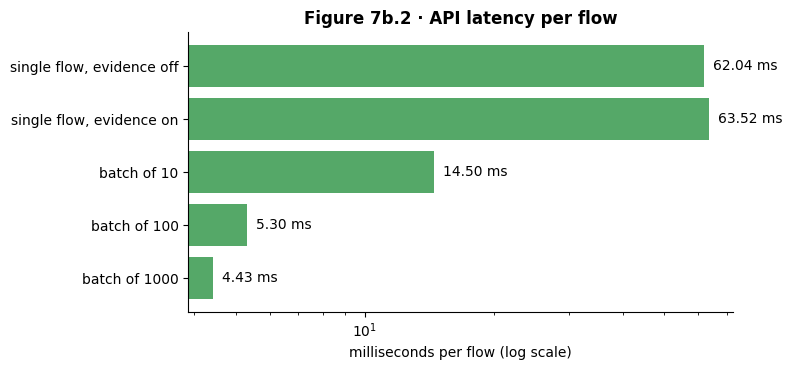

> #### Findings
> | Check | Result |
> |---|---|
> | Single flow, end to end (p50 / p95) | 62.0 / 70.4 ms |
> | Part 4 mechanism estimate | 8.7 ms per flow |
> | Throughput, batch of 1000 | 226 flows/s on one process |
> | Agents for comparison (Part 5) | 22–64 s per flow on a T4 GPU |
>
> **Meaning:** the mechanism stays in the millisecond range behind an API, so it can run inline; batching raises throughput (about 14-fold here), which is how a flow exporter or SIEM forwarder should call it.


In [143]:
from fastapi.testclient import TestClient
import ids_service.main as api
RECS = json.loads(FLOWS.to_json(orient="records"))
rows = []
with TestClient(api.app) as c:
    c.post("/v1/score", json={"flows": RECS[:5]})                         # warm-up
    for ev in (False, True):
        ts, es = [], []
        for i in range(LATENCY_REQUESTS):
            t = time.perf_counter(); res = c.post("/v1/score", json={"flows": [RECS[i % len(RECS)]], "include_evidence": ev})
            ts.append(1e3 * (time.perf_counter() - t)); es.append(res.json()["latency_ms"]); assert res.status_code == 200
        rows.append({"setting": f"single flow, evidence {'on' if ev else 'off'}", "flows per request": 1,
                     "request p50 (ms)": np.median(ts), "request p95 (ms)": np.percentile(ts, 95),
                     "engine p50 (ms)": np.median(es), "ms per flow": np.median(ts), "flows per s": 1e3 / np.median(ts)})
    for b in BATCH_SIZES[1:]:
        batch = (RECS * (b // len(RECS) + 1))[:b]; ts = []
        for _ in range(5):
            t = time.perf_counter(); res = c.post("/v1/score", json={"flows": batch, "include_evidence": False}); ts.append(1e3 * (time.perf_counter() - t))
        rows.append({"setting": f"batch of {b}", "flows per request": b, "request p50 (ms)": np.median(ts),
                     "request p95 (ms)": np.percentile(ts, 95), "engine p50 (ms)": res.json()["latency_ms"],
                     "ms per flow": np.median(ts) / b, "flows per s": b * 1e3 / np.median(ts)})
LAT = pd.DataFrame(rows).set_index("setting"); LAT.to_csv(OUT / "api_latency.csv"); display(LAT.round(3))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(LAT.index[::-1], LAT["ms per flow"][::-1], color="#55A868")
for k, v in enumerate(LAT["ms per flow"][::-1]): ax.text(v * 1.05, k, f"{v:.2f} ms", va="center")
ax.set_xscale("log"); ax.set_xlabel("milliseconds per flow (log scale)")
ax.set_title("Figure 7b.2 · API latency per flow"); savefig("7b_latency.png")
try: REF_MS = json.load(open(NB4 / "run_record_nb4.json"))["mechanism_latency_ms_per_flow"]
except Exception: REF_MS = np.nan
s1 = LAT.iloc[0]
findings([("Single flow, end to end (p50 / p95)", f"{s1['request p50 (ms)']:.1f} / {s1['request p95 (ms)']:.1f} ms"),
          ("Part 4 mechanism estimate", f"{REF_MS:.1f} ms per flow"),
          (f"Throughput, batch of {BATCH_SIZES[-1]}", f"{LAT.iloc[-1]['flows per s']:,.0f} flows/s on one process"),
          ("Agents for comparison (Part 5)", "22–64 s per flow on a T4 GPU")],
         "the mechanism stays in the millisecond range behind an API, so it can run inline; batching raises throughput "
         "(about 14-fold here), which is how a flow exporter or SIEM forwarder should call it.")

## 7b.8 · Live server demonstration
The service is started as a real HTTP server with `uvicorn` (as the container does), queried with five flows (clean, adaptive attack, unseen family), and stopped again. Docker itself is not available on Kaggle; download the bundle (7b.9) and build the image locally or in CI.

In [144]:
import httpx
log = open(OUT / "uvicorn.log", "w")
proc = subprocess.Popen([sys.executable, "-m", "uvicorn", "ids_service.main:app", "--host", "127.0.0.1", "--port", str(PORT)],
                        cwd=BUNDLE, stdout=log, stderr=subprocess.STDOUT, env={**os.environ, "IDS_API_KEY": ""})
BASE = f"http://127.0.0.1:{PORT}"
try:
    for _ in range(120):
        try:
            if httpx.get(f"{BASE}/health", timeout=1).status_code == 200: break
        except httpx.HTTPError: pass
        time.sleep(1)
    else:
        raise RuntimeError("server did not start; see " + str(OUT / "uvicorn.log"))
    print("GET /health ->", httpx.get(f"{BASE}/health").json())
    pick = pd.concat([EXP[EXP.group == "clean"].head(2), EXP[EXP.is_evasion].head(2), EXP[EXP.group == "unseen"].head(1)])
    demo = [RECS[i] for i in pick.index]
    t = time.perf_counter(); r = httpx.post(f"{BASE}/v1/score", json={"flows": demo, "include_evidence": True}, timeout=60); ms = 1e3 * (time.perf_counter() - t)
    out = r.json()
    display(pd.DataFrame([{"flow_id": x["flow_id"], "true family": f, "service decision": x["decision"], "route": x["route"],
                           "predicted": x["predicted_family"], "confidence": round(x["confidence"], 3),
                           "anomaly p": round(x["anomaly_p_value"], 4), "failed checks": ", ".join(x["failed_checks"]) or "–",
                           "top feature": x["top_features"][0]["feature"]} for x, f in zip(out["results"], pick["family"])]))
    print(f"POST /v1/score with {len(demo)} flows over HTTP: {ms:.0f} ms; decisions {out['decisions']}")
    print("\nGET /metrics\n" + httpx.get(f"{BASE}/metrics").text)
finally:
    proc.terminate(); proc.wait(timeout=15); log.close()
print("Same call from a shell:\ncurl -s -X POST localhost:8000/v1/score -H 'Content-Type: application/json' "
      "-d '{\"flows\": [{\"flow_id\": \"f1\", \"Flow Duration\": 117, \"Total Fwd Packets\": 1}]}'")

GET /health -> {'status': 'ok', 'bundle_version': '20261025-0312'}


,flow_id,true family,service decision,route,predicted,confidence,anomaly p,failed checks,top feature
0,clean-1397249,Benign,accept,siem_log,Benign,1.000,0.9763,–,Bwd Packet Length Min
1,clean-444968,Benign,accept,siem_log,Benign,1.000,0.7342,–,Bwd Packet Length Min
2,clean-507066,Bot,escalate,analyst,Benign,0.854,0.0861,"low_confidence, unstable_explanation",Bwd Packet Length Min
3,clean-507067,Bot,escalate,analyst,Benign,0.635,0.0881,"low_confidence, unstable_explanation",Bwd Packet Length Min
4,unseen-1086475,Infiltration,escalate,analyst,Benign,1.000,0.0069,possible_evasion,Init_Win_bytes_backward


POST /v1/score with 5 flows over HTTP: 135 ms; decisions {'accept': 2, 'flag': 0, 'escalate': 3}

GET /metrics
# HELP ids_requests_total Scoring requests.
# TYPE ids_requests_total counter
ids_requests_total 1
# HELP ids_flows_total Flows scored, by decision.
# TYPE ids_flows_total counter
ids_flows_total{decision="accept"} 2
ids_flows_total{decision="flag"} 0
ids_flows_total{decision="escalate"} 3
# HELP ids_request_latency_ms_sum Total request latency in ms.
# TYPE ids_request_latency_ms_sum counter
ids_request_latency_ms_sum 103.977

Same call from a shell:
curl -s -X POST localhost:8000/v1/score -H 'Content-Type: application/json' -d '{"flows": [{"flow_id": "f1", "Flow Duration": 117, "Total Fwd Packets": 1}]}'


## 7b.9 · Package and saved outputs

In [145]:
for p in BUNDLE.rglob("__pycache__"): shutil.rmtree(p, ignore_errors=True)
ZIP = shutil.make_archive(str(OUT / "ids_service_deploy"), "zip", BUNDLE)
RUN = {"bundle_version": MANIFEST["bundle_version"], "created_utc": MANIFEST["created_utc"], "zip": ZIP,
       "zip_mb": round(Path(ZIP).stat().st_size / 1e6, 1), "parity": PAR.round(4).to_dict(orient="index"),
       "fidelity": {"autoencoder_max_rel_diff": AE_REL, "mlp_max_logit_diff": MLP_DIFF, "treeshap_max_diff": SHAP_DIFF},
       "latency": LAT.round(4).to_dict(orient="index"), "requirements": (BUNDLE / "requirements.txt").read_text().splitlines()}
(OUT / "run_record_nb7b.json").write_text(json.dumps(RUN, indent=2, default=lambda o: None if isinstance(o, float) and np.isnan(o) else str(o)))
display(pd.DataFrame([(str(p.relative_to(OUT)), round(p.stat().st_size / 1e6, 2)) for p in sorted(OUT.iterdir()) if p.is_file()],
                     columns=["file", "size_mb"]))
findings([("Download", f"`{Path(ZIP).relative_to(WORK_ROOT)}` ({RUN['zip_mb']} MB): Kaggle → Output → nb7b_deployment"),
          ("Build and run", "`unzip ids_service_deploy.zip -d ids && cd ids && docker compose up --build` → http://localhost:8000/docs")])

,file,size_mb
0,api_latency.csv,0.00
1,ids_service_deploy.zip,12.38
2,parity_with_part4.csv,0.00
3,run_record_nb7b.json,0.00
4,uvicorn.log,0.00


> #### Findings
> | Check | Result |
> |---|---|
> | Download | `nb7b_deployment/ids_service_deploy.zip` (12.4 MB): Kaggle → Output → nb7b_deployment |
> | Build and run | `unzip ids_service_deploy.zip -d ids && cd ids && docker compose up --build` → http://localhost:8000/docs |


> #### Saved files
> | File | Content |
> |---|---|
> | `ids_service_deploy/` and `ids_service_deploy.zip` | service code, model bundle with manifest, tests and parity data, `Dockerfile`, `docker-compose.yml`, `requirements*.txt`, `README.md`, `client_example.py` |
> | `parity_with_part4.csv` | agreement between the service and Part 4 per flow group |
> | `api_latency.csv`, `figures/7b_latency.png` | latency and throughput through the API |
> | `run_record_nb7b.json`, `uvicorn.log` | run record and the log of the live server |

#### API reference (summary)
| Method | Path | Request | Response |
|---|---|---|---|
| GET | `/health` | – | `{"status": "ok", "bundle_version": …}` |
| GET | `/v1/model-info` | – | classes, thresholds, stability measure, expected features, versions |
| POST | `/v1/score` | `{"flows": [{"flow_id": "…", "Flow Duration": …, …}], "include_evidence": true}` | per flow: `decision`, `route`, `predicted_family`, `confidence`, `anomaly_p_value`, `explanation_stability`, `failed_checks`, second opinions, top features, similar cases |
| POST | `/v1/score/csv` | CICFlowMeter CSV upload | the CSV with `ids_*` columns added, or JSON |
| GET | `/metrics` | – | Prometheus counters by decision |

#### Key takeaways
- The mechanism of Part 4 runs as a stand-alone REST service that takes **raw CICFlowMeter features** and reproduces the evaluated decisions (parity table in 7b.4), including on adaptive-attack and never-seen flows.
- The container needs **no GPU and no PyTorch**: the networks are exported to NumPy and the explanations use XGBoost's own TreeSHAP, both checked against the originals.
- Latency stays in the **millisecond range** per flow behind the API, so the mechanism can run inline, while the LLM agents (seconds per flow) stay offline behind the `agent_queue` route, as in Figure 8.1.
- Operational safeguards: fail-closed handling of malformed flows, hash-checked model bundle with versions, optional API key, size limits, health check and Prometheus metrics for a flag-rate alarm.

#### Contribution to the research questions
| RQ | Contribution |
|---|---|
| **RQ4** | latency and throughput of the mechanism as a deployed service; cost of deployment (CPU only, image without PyTorch) |
| **RQ2, RQ3** | the decisions evaluated in Parts 4–5 are reproducible by the deployed artefact (parity test) |

<a id="part8"></a>
# Part 8 · Conclusion

## Contributions
1. **A validated, attacker-realistic evaluation** of ML intrusion detection: leakage-safe data preparation (Part 1), a threat model that keeps every adversarial flow physically realisable (0 violations), and evidence that both detection (macro-F1 0.95 → 0.25) and SHAP explanations degrade under attack (RQ1).
2. **A transparent confidence-aware mechanism** that fuses calibrated confidence, conformal anomaly evidence and a *deployable* explanation-robustness indicator into accept / flag / escalate decisions. The explanation-robustness indicator is new: it needs no clean copy of the flow, tracks the explanation damage measured in RQ1 (ρ = 0.47), and is a better warning sign of a wrong prediction than the classifier's own confidence (AUROC 0.867 vs 0.738). The mechanism catches 96 % of wrong decisions and 91 % of unseen adaptive evasions (56 % against a defence-aware attacker) at a 5 % false-flag cost (RQ2).
3. **A controlled comparison of agentic designs** showing that the reliability gain comes from the mechanism, while confidence-aware routing halves the cost of evidence-grounded multi-agent reporting, and that an LLM cannot replace the detector (RQ3, RQ4).

## Discussion: what the results mean in relation to prior work

**RQ1 confirms the literature, under stricter conditions.** The collapse of macro-F1 from 0.95 to 0.25 agrees with the adversarial-examples literature (Szegedy *et al.*, 2014; Carlini and Wagner, 2017), but here it holds although every adversarial flow respects the realisability constraints argued for by Apruzzese *et al.* (2022). The finding that random noise of the same size already causes most of the drop is less often reported. It suggests that much of the published "adversarial vulnerability" of flow-based IDS is plain fragility to realistic variation, in line with the warnings of Sommer and Paxson (2010) and Arp *et al.* (2022). The loss of SHAP-ranking agreement extends the explanation-fragility results of Ghorbani, Abid and Zou (2019) and Slack *et al.* (2020) to tree-based IDS under a realistic attacker, and shows that explanations can change even when the alert itself stays correct.

**RQ2 extends the reject option to adversarial IDS.** Selective classification (Geifman and El-Yaniv, 2017) and Transcend (Jordaney *et al.*, 2017) reject decisions on the basis of one indicator. The ablation shows why one indicator is not enough under attack: confidence alone keeps only 41.4 % of wrong predictions from automatic acceptance, because an adversarial flow is by design a *confident* mistake (Hendrycks and Gimpel, 2017). The disagreement between classifier and conformal anomaly evidence contributes most. This is consistent with the idea behind anomaly-based NIDS (Mirsky *et al.*, 2018): an attacker who pushes a flow into the *benign* class still has to make it look benign to a model of normal traffic. **Explanation robustness, the project's novel indicator, is a stronger trust indicator than confidence**, the indicator on which selective classification normally relies. It separates wrong from correct predictions better (AUROC 0.867 vs 0.738; risk–coverage area under attack 0.151 vs 0.254), and used alone it catches at least as many wrong predictions as confidence alone, with fewer false flags (3.6 % vs 5.35 %) and a far higher macro-F1 on the flows it accepts (0.677 vs 0.520). In other words, *how stable an explanation is* says more about whether to trust a prediction than *how sure the model is*. Inside the full rule its headline gain looks small (+0.6 points), but only because confidence and anomaly evidence together already catch 95.4 % of errors: of the errors they still miss, explanation robustness catches about one in eight, and it raises the macro-F1 of accepted attacked flows by 1.5 points (both established). When the indicators are weighted freely by the learned combiner, explanation robustness receives a larger standardised weight (−1.51) than confidence (−0.57) or the anomaly p-value (−0.74) on their own; only the interaction between a benign verdict and the anomaly p-value weighs more (−4.15). It is also the only indicator that tells the analyst *why* a flow is suspicious: which features the model relied on and how far that reasoning departs from the typical explanation of the predicted class. The defence-aware attack (56 % of evasions caught) and the adversarial-training baseline (0.96) mark the limits: the mechanism raises the attacker's cost and needs no attack examples, but, as Madry *et al.* (2018) would predict, training on a known attack defends better against that attack.

**RQ3 qualifies the case for agentic IDS.** CyberRAG (Blefari *et al.*, 2026) and Chou, Sudheer and Park (2026) show that LLM agents can classify and write useful incident reports. In this project's controlled comparison, the agents did not handle more detector errors than the deterministic pipeline (B) or than a conventional multi-agent system (D); the reliability gain came from the confidence-aware mechanism. A guarded design, in which the agents may add caution but never remove it (Section 5.12b, added after the main results), tests the obvious remedy: it handles 96.4 % of errors against 92.4 % for the rules alone, a gain that is not established on 200 flows, and sends 41.8 % of flows to analysts instead of 38.1 %. Even with limited authority, the agents' value lies in explanation rather than extra detection. The agents' contribution is evidence-cited explanation: with a deterministic verifier, no unsupported claims were detected, which addresses the hallucination risk described by Ji *et al.* (2023) more transparently than an LLM judge. Section 5.18 states the remaining blind spot, errors of meaning. Section 5.19 measures the opposite design, the LLM classifying flows on its own: it reaches macro-F1 0.05 against 0.63 for XGBoost on the same flows (0.04 against 0.96 on clean flows, i.e. chance level) and needs 0.9 s per flow against microseconds, which supports using the LLM for explanation rather than classification.

**RQ4 makes the trade-off explicit.** The mechanism costs milliseconds per flow; agents cost tens of seconds. Routing only flagged flows to the agents halves tokens and time with no established loss of reliability, which suggests a practical division of labour for a SOC: the mechanism runs inline, agents and analysts work on the small stream it flags (Part 7b, Figure 8.1). The cost is analyst workload under attack, which the budget sweep in Part 4b.5 lets an operator set explicitly.

## Limitations
- **One dataset.** CIC-IDS2017 is a lab capture with known labelling issues (Engelen, Rimmer and Joosen, 2021); results may not transfer to real networks or other datasets.
- **Simulated attacker.** ZOO with 10 steps inside a stated threat model, including a defence-aware variant that targets the mechanism itself (Part 4b); packet-level (problem-space) attacks could lower the numbers further.
- **Workload under attack.** Catching 96 % of wrong decisions means only 46 % of attacked flows are accepted automatically.
- **Agent evaluation.** Small open LLMs (Gemma 4 E2B as primary, compared with the larger Gemma 4 E4B in Section 5.16) on 200 weighted flows; small differences between systems cannot be established at this size. A cybersecurity-specialised model (Foundation-Sec 8B) is configured but was not run.
- **Adversarial training is stronger on known attacks.** Retraining on adversarial flows restores macro-F1 to 0.96 against the attack family it was trained on, well above the flows the mechanism accepts (0.47); the mechanism's value lies in needing no attack examples and in catching never-seen families. Combining the two was not tested.
- **Defence-aware attacker.** An attacker who knows the thresholds gets 44 % of evasions past the mechanism (56 % caught, Section 4b.2).
- **Run-to-run variation.** Two complete runs of this notebook gave slightly different numbers (GPU non-determinism in training and LLM generation): for example, errors handled by system E were 89.9 % in one run and 93.7 % in the other, and the gain from explanation robustness +0.9 and +0.6 points. Every reliability conclusion (which differences are established and which are not) was the same in both runs; one secondary result, the lower macro-F1 of Gemma 4 E4B's automatic decisions, was established in one run but not in the other. This notebook reports the second run.
- **Verifier scope.** The programmatic verifier checks citations, decimal numbers and attack labels in the cited claims. It does not check meaning, integers or the free-text report (Section 5.18), so "0 % unsupported claims" means *no detectable* fabrication, not proven correctness.
- **Retrieval.** The knowledge-base entry of the *true* family is among the top three retrieved entries for only 30 % of flows (Table 6.8), because the query is built from the (possibly wrong) predictions.
- **Service speed.** Behind the API one flow takes about 62 ms end to end and one process handles about 226 flows/s in batches (Section 7b.7). This is enough for a demonstration and for the flagged stream, not for line-rate traffic without more processes or a lighter configuration (for example, without the RF second opinion).
- **Overlap between indicators under attack.** Explanation robustness is a stronger error indicator than confidence, but under attack most of the errors it detects are also caught by the classifier–anomaly disagreement, so its marginal gain inside the full rule is +0.6 points (about one in eight of the remaining errors). A defence-aware attacker could also try to keep explanations stable (Part 4b.2 attacks all checks at once).

## Deviations from the project plan (PDM)
| Plan | What was done | Reason |
|---|---|---|
| four baseline classifiers | four models compared: XGBoost and Random Forest (baselines), MLP (deep learning) and Gemma 4 E2B (LLM, also tested as a stand-alone classifier in Section 5.19); two anomaly detectors for the mechanism | covers boosting, bagging, neural and language models; SHAP stability per model is costly (≈ 2 h per non-tree model) |
| exact and near-duplicate removal | exact duplicates removed; near-duplicate thinning implemented but off | thinning distorts class densities and calibration (Section 1.12) |
| time / group-aware splits | stratified random split | every attack family occurs on a single capture day, so a time split would remove whole classes (Section 1.E3) |
| UNSW-NB15 as backup dataset | not used | CIC-IDS2017 worked; cross-dataset validation is future work |
| LLM via external API | Gemma 4 run locally on Kaggle | no flow data leaves the environment; cost reported as tokens and GPU time |

## Future work
Cross-dataset validation (CSE-CIC-IDS2018, UNSW-NB15), run as separate experiments on a shared NetFlow feature set rather than by merging datasets, whose different feature sets and networks would let a model learn which dataset a flow came from; NLP classifiers (e.g. fine-tuned BERT-family models) on payload-level datasets, where the input is text; packet-level attacks and defence-aware training of the mechanism; combining adversarial training with the mechanism; larger LLMs and agent samples; adaptive thresholds that limit analyst workload during an attack; and carrying out the human evaluation of the threat reports designed in this Part.

## Deployment architecture
How the components would sit in a security operations centre (SOC). Only the fast mechanism runs inline; agents and analysts work on the small flagged stream. The inline part is implemented and tested as a REST service in [Part 7b](#part7b).

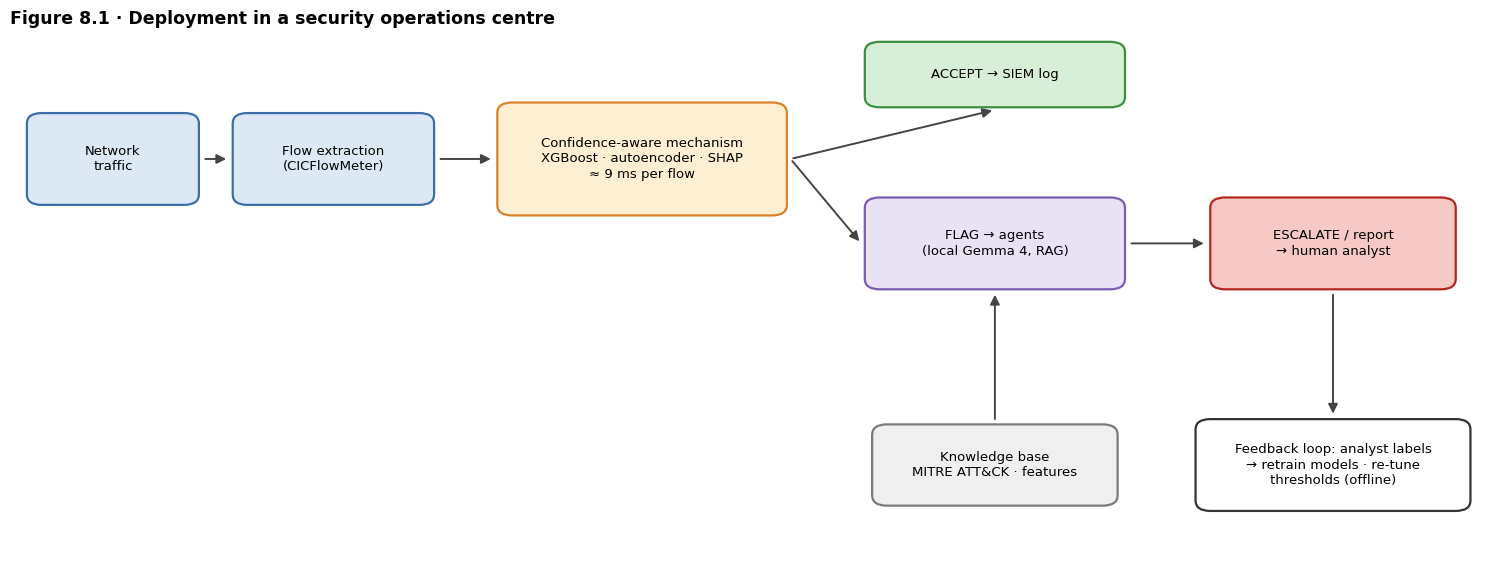

In [146]:
import os, sys
from pathlib import Path
sys.path.insert(0, str(Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"))
import matplotlib.pyplot as plt
from present_lib import flowchart
nodes = {
    "net": (7, 38, 11, 8, "Network\ntraffic", "data"),
    "cfm": (22, 38, 13, 8, "Flow extraction\n(CICFlowMeter)", "data"),
    "mech": (43, 38, 19, 10, "Confidence-aware mechanism\nXGBoost · autoencoder · SHAP\n≈ 9 ms per flow", "policy"),
    "acc": (67, 46, 17, 5.5, "ACCEPT → SIEM log", "accept"),
    "agents": (67, 30, 17, 8, "FLAG → agents\n(local Gemma 4, RAG)", "agent"),
    "an": (90, 30, 16, 8, "ESCALATE / report\n→ human analyst", "escalate"),
    "kb": (67, 9, 16, 7, "Knowledge base\nMITRE ATT&CK · features", "out"),
    "fb": (90, 9, 18, 8, "Feedback loop: analyst labels\n→ retrain models · re-tune\nthresholds (offline)", "rq"),
}
edges = [("net", "cfm"), ("cfm", "mech"), ("mech", "acc"), ("mech", "agents"), ("agents", "an"), ("kb", "agents"), ("an", "fb")]
flowchart(nodes, edges, size=(15, 5.8), title="Figure 8.1 · Deployment in a security operations centre")
plt.show()

## Ethics, privacy and responsible use
| Topic | How the project addresses it | Remaining risk |
|---|---|---|
| **Privacy** | Flow features only (no payloads); the LLM runs locally on Kaggle, so no traffic data leaves the environment | real deployments must still follow data-protection law (e.g. UK GDPR) for IP-level metadata |
| **Human oversight** | Uncertain and possibly evaded flows are escalated to a human; the agents never act automatically | analyst over-reliance on the reports (automation bias) |
| **Transparency** | Every decision lists the failed checks, the SHAP features and cited evidence; a verifier rejects unsupported claims | SHAP explanations themselves can be unstable (Part 3) — shown to the analyst as an indication, not as proof |
| **Dual use** | Attacks are simulated only inside a stated threat model on a public lab dataset; no exploit code is produced | the stress tests show how evasion works in principle; they are reported at the level of features, not tools |
| **Fairness of workload** | The false-flag budget fixes the extra work on normal traffic (Part 4b.5) | under attack, workload rises sharply |
| **Environmental cost** | Energy per 1,000 flows reported (Table 6.12); the cheap mechanism filters what reaches the LLM | estimate is an upper bound |

## Planned human evaluation of the threat reports (protocol)
To turn "the reports help analysts" into evidence, 3–5 raters with security background each rate 20 randomly chosen incident cards (Part 7) on a 1–5 scale. Template (also saved by the report section as a CSV if desired):

| report_id | clarity (1–5) | correctness of the verdict (1–5) | usefulness for the next action (1–5) | trust (1–5) | comment |
|---|---|---|---|---|---|
| INC-001 | | | | | |

Agreement between raters is reported with Krippendorff's α; results are compared between systems D and E. *This study was designed but not carried out within the project time and requires ethics approval from the university before collecting ratings.*

## References

Alvarez-Melis, D. and Jaakkola, T.S. (2018) 'On the robustness of interpretability methods', *ICML Workshop on Human Interpretability in Machine Learning*.

Angelopoulos, A.N. and Bates, S. (2023) 'Conformal prediction: a gentle introduction', *Foundations and Trends in Machine Learning*, 16(4), pp. 494–591.

Apruzzese, G., Andreolini, M., Ferretti, L., Marchetti, M. and Colajanni, M. (2022) 'Modeling realistic adversarial attacks against network intrusion detection systems', *Digital Threats: Research and Practice*, 3(3).

Arp, D. *et al.* (2022) 'Dos and don'ts of machine learning in computer security', *31st USENIX Security Symposium*, pp. 3971–3988.

Blefari, F. *et al.* (2026) 'CyberRAG: an agentic RAG cyber attack classification and reporting tool', *Future Generation Computer Systems*, 176, 108186.

Breiman, L. (2001) 'Random forests', *Machine Learning*, 45(1), pp. 5–32.

Carlini, N. and Wagner, D. (2017) 'Towards evaluating the robustness of neural networks', *2017 IEEE Symposium on Security and Privacy*, pp. 39–57.

Chawla, N.V., Bowyer, K.W., Hall, L.O. and Kegelmeyer, W.P. (2002) 'SMOTE: synthetic minority over-sampling technique', *Journal of Artificial Intelligence Research*, 16, pp. 321–357.

Chen, P.-Y., Zhang, H., Sharma, Y., Yi, J. and Hsieh, C.-J. (2017) 'ZOO: zeroth order optimization based black-box attacks to deep neural networks without training substitute models', *10th ACM Workshop on Artificial Intelligence and Security*, pp. 15–26.

Chen, T. and Guestrin, C. (2016) 'XGBoost: a scalable tree boosting system', *22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, pp. 785–794.

Chou, C.H., Sudheer, A. and Park, Y. (2026) 'An LLM-based agentic network traffic incident-report approach towards explainable-AI network defense', *Journal of Sensor and Actuator Networks*, 15(2), p. 32.

Chow, C.K. (1970) 'On optimum recognition error and reject tradeoff', *IEEE Transactions on Information Theory*, 16(1), pp. 41–46.

Corona, I., Giacinto, G. and Roli, F. (2013) 'Adversarial attacks against intrusion detection systems: taxonomy, solutions and open issues', *Information Sciences*, 239, pp. 201–225.

Dombrowski, A.-K. *et al.* (2019) 'Explanations can be manipulated and geometry is to blame', *Advances in Neural Information Processing Systems 32*.

Engelen, G., Rimmer, V. and Joosen, W. (2021) 'Troubleshooting an intrusion detection dataset: the CICIDS2017 case study', *IEEE Security and Privacy Workshops*, pp. 7–12.

Geifman, Y. and El-Yaniv, R. (2017) 'Selective classification for deep neural networks', *Advances in Neural Information Processing Systems 30*.

Ghorbani, A., Abid, A. and Zou, J. (2019) 'Interpretation of neural networks is fragile', *Proceedings of the AAAI Conference on Artificial Intelligence*, 33(1), pp. 3681–3688.

Goodfellow, I.J., Shlens, J. and Szegedy, C. (2015) 'Explaining and harnessing adversarial examples', *3rd International Conference on Learning Representations (ICLR)*.

Guo, C., Pleiss, G., Sun, Y. and Weinberger, K.Q. (2017) 'On calibration of modern neural networks', *34th International Conference on Machine Learning*.

Hendrycks, D. and Gimpel, K. (2017) 'A baseline for detecting misclassified and out-of-distribution examples in neural networks', *5th International Conference on Learning Representations (ICLR)*.

Ji, Z. *et al.* (2023) 'Survey of hallucination in natural language generation', *ACM Computing Surveys*, 55(12), Article 248.

Jordaney, R. *et al.* (2017) 'Transcend: detecting concept drift in malware classification models', *26th USENIX Security Symposium*, pp. 625–642.

Kull, M. *et al.* (2019) 'Beyond temperature scaling: obtaining well-calibrated multi-class probabilities with Dirichlet calibration', *Advances in Neural Information Processing Systems 32*.

Lewis, P. *et al.* (2020) 'Retrieval-augmented generation for knowledge-intensive NLP tasks', *Advances in Neural Information Processing Systems 33*, pp. 9459–9474.

Lin, Z., Shi, Y. and Xue, Z. (2022) 'IDSGAN: generative adversarial networks for attack generation against intrusion detection', *Pacific-Asia Conference on Knowledge Discovery and Data Mining (PAKDD)*, pp. 79–91.

Liu, F.T., Ting, K.M. and Zhou, Z.-H. (2008) 'Isolation forest', *Eighth IEEE International Conference on Data Mining*, pp. 413–422.

Lundberg, S.M. and Lee, S.I. (2017) 'A unified approach to interpreting model predictions', *Advances in Neural Information Processing Systems 30*, pp. 4765–4774.

Lundberg, S.M. *et al.* (2020) 'From local explanations to global understanding with explainable AI for trees', *Nature Machine Intelligence*, 2, pp. 56–67.

Madry, A. *et al.* (2018) 'Towards deep learning models resistant to adversarial attacks', *6th International Conference on Learning Representations (ICLR)*.

Mirsky, Y., Doitshman, T., Elovici, Y. and Shabtai, A. (2018) 'Kitsune: an ensemble of autoencoders for online network intrusion detection', *Network and Distributed System Security Symposium (NDSS)*.

MITRE (2026) *MITRE ATT&CK*. Available at: https://attack.mitre.org/

Pendlebury, F. *et al.* (2019) 'TESSERACT: eliminating experimental bias in malware classification across space and time', *28th USENIX Security Symposium*, pp. 729–746.

Ribeiro, M.T., Singh, S. and Guestrin, C. (2016) '"Why should I trust you?": explaining the predictions of any classifier', *22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, pp. 1135–1144.

Sharafaldin, I., Lashkari, A.H. and Ghorbani, A.A. (2018) 'Towards the development of a new intrusion detection data set and intrusion traffic classification', *ICISSP 2018*, pp. 108–116.

Slack, D. *et al.* (2020) 'Fooling LIME and SHAP: adversarial attacks on post hoc explanation methods', *AAAI/ACM Conference on AI, Ethics, and Society*, pp. 180–186.

Sommer, R. and Paxson, V. (2010) 'Outside the closed world: on using machine learning for network intrusion detection', *2010 IEEE Symposium on Security and Privacy*, pp. 305–316.

Szegedy, C. *et al.* (2014) 'Intriguing properties of neural networks', *2nd International Conference on Learning Representations (ICLR)*.

Vovk, V., Gammerman, A. and Shafer, G. (2005) *Algorithmic Learning in a Random World*. New York: Springer.

Webber, W., Moffat, A. and Zobel, J. (2010) 'A similarity measure for indefinite rankings', *ACM Transactions on Information Systems*, 28(4).

Yao, S. *et al.* (2023) 'ReAct: synergizing reasoning and acting in language models', *11th International Conference on Learning Representations (ICLR)*.

↑ back to contents (Notebook 1)


---
## Viva guide for this notebook

**Suggested demonstration path (about 8 minutes)**
1. **Figure 5.1**: the agents and the routing that defines system E.
2. **5.8**: the verifier rules (what counts as an unsupported claim).
3. **5.11–5.12**: systems A–E and the bootstrap (E vs D not established; cost halved).
4. **5.14**: an example agent report.
5. **5.19**: the LLM-only baseline (0.047).
6. **Part 6**: one section per research question (6.1–6.5); good closing summary.
7. **Part 7**: run 7.1–7.3 live (≈ 1 minute; attach the outputs of Notebooks 4 and 5), then type `1`, `critical` and `Bot` in the 7.3 box or the explorer; show Previous / Next and Print.
8. **Part 7b**: parity 100 %, 9 tests passed, latency.

**Likely questions and short answers**

| Question | Answer |
|---|---|
| Do the agents improve reliability? | Not significantly: E 93.7 % vs D 96.2 % errors handled, difference not established. The gain over single models comes from the mechanism; the agents add verifiable explanation. |
| Then why use agents? | They write evidence-cited incident reports with MITRE ATT&CK techniques, and routing halves their cost (1,506 vs 3,073 tokens; 29 vs 64 s per flow). |
| How do you stop hallucination? | Agents see only numbered evidence and retrieved knowledge; the deterministic verifier rejects uncited claims, unknown citations, absent classes and numbers not in the evidence. |
| Can the verifier be fooled? | It caught 100 % of injected citation, number and label errors, but it cannot check semantic correctness, so "no unsupported claims" means no detectable fabrication. |
| Why a small local LLM? | Privacy (no data leaves) and cost; a larger Gemma (E4B) gave no established gain. |
| Why 200 flows only? | LLM cost: the run already took 4.8 hours for 1,111 Gemma calls. The sample is weighted to the test mix, and the bootstrap shows which differences can be trusted. |
| Is it deployable? | Yes: a FastAPI service reproduced 100 % of Notebook 4's decisions on 347 flows, passed 9 tests and runs at 62 ms per flow (226 flows/s in batches). |
| How is the threat report produced? | From the saved outputs only: the mechanism's decision and reasons, the trust indicators, SHAP features and similar flows (Notebook 4) and the verified agent analysis (Part 5). Response suggestions are a fixed playbook, not generated by the LLM; ground truth is shown only for evaluation. |
| What are the main limitations? | One lab dataset; feature-space attacks; a defence-aware attacker still gets 44 % of its evasions through; small LLMs on 200 flows; retrieval found the true family in the top three for only 30 % of flows. |